In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
TRAIN_DIR = "/content/drive/MyDrive/ORCHID_224_JPG"
VAL_DIR   = "/content/drive/MyDrive/val"
TEST_DIR  = "/content/drive/MyDrive/test/test"

In [ ]:
import os
import glob

for name, folder in {
    "TRAIN": TRAIN_DIR,
    "VAL": VAL_DIR,
    "TEST": TEST_DIR
}.items():

    files = glob.glob(
        os.path.join(folder, "**", "*"),
        recursive=True
    )

    files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("=" * 60)
    print(name)
    print("Total images:", len(files))

    print("\nFirst 10 files:")
    for f in files[:10]:
        print(os.path.relpath(f, folder))

TRAIN
Total images: 10227

First 10 files:
osmf/o-1-00-29/o-1-00-29-043.jpg
osmf/o-1-00-29/o-1-00-29-095.jpg
osmf/o-1-00-29/o-1-00-29-049.jpg
osmf/o-1-00-29/o-1-00-29-100.jpg
osmf/o-1-00-29/o-1-00-29-099.jpg
osmf/o-1-00-29/o-1-00-29-103.jpg
osmf/o-1-00-29/o-1-00-29-064.jpg
osmf/o-1-00-29/o-1-00-29-123.jpg
osmf/o-1-00-29/o-1-00-29-069.jpg
osmf/o-1-00-29/o-1-00-29-096.jpg
VAL
Total images: 2885

First 10 files:
osmf/o-1-00-29/o-1-00-29-017.jpg
osmf/o-1-00-29/o-1-00-29-059.jpg
osmf/o-1-00-29/o-1-00-29-052.jpg
osmf/o-1-00-29/o-1-00-29-093.jpg
osmf/o-1-00-29/o-1-00-29-002.jpg
osmf/o-1-00-29/o-1-00-29-031.jpg
osmf/o-1-00-29/o-1-00-29-105.jpg
osmf/o-1-00-29/o-1-00-29-008.jpg
osmf/o-1-00-29/o-1-00-29-001.jpg
osmf/o-1-00-29/o-1-00-29-108.jpg
TEST
Total images: 1592

First 10 files:
osmf/o-1-00-29/o-1-00-29-075.jpg
osmf/o-1-00-29/o-1-00-29-062.jpg
osmf/o-1-00-29/o-1-00-29-124.jpg
osmf/o-1-00-29/o-1-00-29-107.jpg
osmf/o-1-00-29/o-1-00-29-030.jpg
osmf/o-1-00-29/o-1-00-29-024.jpg
osmf/o-1-00-29/o-1

In [ ]:
import os
import glob

# =========================================================
# EXTRACT SLIDE IDs FROM FOLDER STRUCTURE
# Structure:
# class / slide_id / image.jpg
# =========================================================

def get_slide_ids(folder):
    slide_ids = set()

    for class_name in os.listdir(folder):

        class_path = os.path.join(folder, class_name)

        if not os.path.isdir(class_path):
            continue

        for slide_name in os.listdir(class_path):

            slide_path = os.path.join(
                class_path,
                slide_name
            )

            if os.path.isdir(slide_path):
                slide_ids.add(slide_name)

    return slide_ids


# =========================================================
# GET SLIDE IDs
# =========================================================

train_slides = get_slide_ids(TRAIN_DIR)
val_slides   = get_slide_ids(VAL_DIR)
test_slides  = get_slide_ids(TEST_DIR)


# =========================================================
# OVERLAP
# =========================================================

train_val = train_slides & val_slides
train_test = train_slides & test_slides
val_test = val_slides & test_slides

all_three = (
    train_slides &
    val_slides &
    test_slides
)


# =========================================================
# RESULTS
# =========================================================

print("=" * 60)
print("SLIDE-LEVEL SPLIT ANALYSIS")
print("=" * 60)

print(f"Train Slides : {len(train_slides)}")
print(f"Val Slides   : {len(val_slides)}")
print(f"Test Slides  : {len(test_slides)}")

print("\n" + "=" * 60)
print("SLIDE OVERLAP")
print("=" * 60)

print(f"Train ∩ Val   : {len(train_val)}")
print(f"Train ∩ Test  : {len(train_test)}")
print(f"Val ∩ Test    : {len(val_test)}")
print(f"All Three     : {len(all_three)}")


# =========================================================
# EXAMPLES
# =========================================================

print("\n" + "=" * 60)
print("EXAMPLE OVERLAPPING SLIDES")
print("=" * 60)

print("\nTrain ∩ Test:")
print(sorted(list(train_test))[:20])

print("\nVal ∩ Test:")
print(sorted(list(val_test))[:20])

print("\nTrain ∩ Val:")
print(sorted(list(train_val))[:20])

SLIDE-LEVEL SPLIT ANALYSIS
Train Slides : 149
Val Slides   : 149
Test Slides  : 150

SLIDE OVERLAP
Train ∩ Val   : 149
Train ∩ Test  : 149
Val ∩ Test    : 149
All Three     : 149

EXAMPLE OVERLAPPING SLIDES

Train ∩ Test:
['o-0-00-01', 'o-0-00-02', 'o-0-00-03', 'o-0-00-04', 'o-0-00-05', 'o-0-00-06', 'o-0-00-07', 'o-0-00-08', 'o-0-00-09', 'o-0-00-10', 'o-0-00-11', 'o-0-00-12', 'o-0-00-13', 'o-0-00-14', 'o-1-00-01', 'o-1-00-02', 'o-1-00-03', 'o-1-00-04', 'o-1-00-05', 'o-1-00-06']

Val ∩ Test:
['o-0-00-01', 'o-0-00-02', 'o-0-00-03', 'o-0-00-04', 'o-0-00-05', 'o-0-00-06', 'o-0-00-07', 'o-0-00-08', 'o-0-00-09', 'o-0-00-10', 'o-0-00-11', 'o-0-00-12', 'o-0-00-13', 'o-0-00-14', 'o-1-00-01', 'o-1-00-02', 'o-1-00-03', 'o-1-00-04', 'o-1-00-05', 'o-1-00-06']

Train ∩ Val:
['o-0-00-01', 'o-0-00-02', 'o-0-00-03', 'o-0-00-04', 'o-0-00-05', 'o-0-00-06', 'o-0-00-07', 'o-0-00-08', 'o-0-00-09', 'o-0-00-10', 'o-0-00-11', 'o-0-00-12', 'o-0-00-13', 'o-0-00-14', 'o-1-00-01', 'o-1-00-02', 'o-1-00-03', 'o-1-00

In [ ]:
import os
import glob

for name, folder in {
    "TRAIN": TRAIN_DIR,
    "VAL": VAL_DIR,
    "TEST": TEST_DIR
}.items():

    files = glob.glob(
        os.path.join(folder, "**", "*.jpg"),
        recursive=True
    )

    print("\n" + "=" * 60)
    print(name)

    for f in files[:20]:
        print(os.path.basename(f))


TRAIN
o-1-00-29-043.jpg
o-1-00-29-095.jpg
o-1-00-29-049.jpg
o-1-00-29-100.jpg
o-1-00-29-099.jpg
o-1-00-29-103.jpg
o-1-00-29-064.jpg
o-1-00-29-123.jpg
o-1-00-29-069.jpg
o-1-00-29-096.jpg
o-1-00-29-121.jpg
o-1-00-29-046.jpg
o-1-00-29-091.jpg
o-1-00-29-070.jpg
o-1-00-29-119.jpg
o-1-00-29-086.jpg
o-1-00-29-039.jpg
o-1-00-29-056.jpg
o-1-00-29-139.jpg
o-1-00-29-092.jpg

VAL
o-1-00-29-017.jpg
o-1-00-29-059.jpg
o-1-00-29-052.jpg
o-1-00-29-093.jpg
o-1-00-29-002.jpg
o-1-00-29-031.jpg
o-1-00-29-105.jpg
o-1-00-29-008.jpg
o-1-00-29-001.jpg
o-1-00-29-108.jpg
o-1-00-29-040.jpg
o-1-00-29-087.jpg
o-1-00-29-134.jpg
o-1-00-29-125.jpg
o-1-00-29-132.jpg
o-1-00-29-084.jpg
o-1-00-29-077.jpg
o-1-00-29-004.jpg
o-1-00-29-088.jpg
o-1-00-29-131.jpg

TEST
o-1-00-29-075.jpg
o-1-00-29-062.jpg
o-1-00-29-124.jpg
o-1-00-29-107.jpg
o-1-00-29-030.jpg
o-1-00-29-024.jpg
o-1-00-29-112.jpg
o-1-00-29-011.jpg
o-1-00-29-034.jpg
o-1-00-29-109.jpg
o-1-00-29-023.jpg
o-1-00-29-035.jpg
o-1-00-29-058.jpg
o-1-00-29-014.jpg
o-1-00-04-

In [ ]:
import os
import glob

# =========================================================
# PATIENT ID EXTRACTION
# ORCHID format:
# o-class_id-source_id-patient_id-image_id.jpg
# Example:
# o-1-00-29-043.jpg  -> Patient ID = 29
# =========================================================

def get_patient_ids(folder):

    patient_ids = set()

    files = glob.glob(
        os.path.join(folder, "**", "*.jpg"),
        recursive=True
    )

    for file_path in files:

        filename = os.path.basename(file_path)
        name = os.path.splitext(filename)[0]

        parts = name.split("-")

        # Expected:
        # ['o', class_id, source_id, patient_id, image_id]

        if len(parts) >= 5:
            patient_id = parts[3]
            patient_ids.add(patient_id)

    return patient_ids


# =========================================================
# EXTRACT PATIENT IDS
# =========================================================

train_patients = get_patient_ids(TRAIN_DIR)
val_patients   = get_patient_ids(VAL_DIR)
test_patients  = get_patient_ids(TEST_DIR)


# =========================================================
# OVERLAP
# =========================================================

train_val = train_patients & val_patients
train_test = train_patients & test_patients
val_test = val_patients & test_patients

all_three = (
    train_patients &
    val_patients &
    test_patients
)


# =========================================================
# RESULTS
# =========================================================

print("=" * 60)
print("PATIENT-LEVEL SPLIT ANALYSIS")
print("=" * 60)

print(f"Train Patients : {len(train_patients)}")
print(f"Val Patients   : {len(val_patients)}")
print(f"Test Patients  : {len(test_patients)}")

print("\n" + "=" * 60)
print("PATIENT OVERLAP")
print("=" * 60)

print(f"Train ∩ Val   : {len(train_val)}")
print(f"Train ∩ Test  : {len(train_test)}")
print(f"Val ∩ Test    : {len(val_test)}")
print(f"All Three     : {len(all_three)}")


# =========================================================
# SHOW OVERLAPPING PATIENT IDS
# =========================================================

print("\n" + "=" * 60)
print("OVERLAPPING PATIENT IDs")
print("=" * 60)

print("\nTrain ∩ Val:")
print(sorted(train_val))

print("\nTrain ∩ Test:")
print(sorted(train_test))

print("\nVal ∩ Test:")
print(sorted(val_test))

print("\nAll Three:")
print(sorted(all_three))

PATIENT-LEVEL SPLIT ANALYSIS
Train Patients : 44
Val Patients   : 44
Test Patients  : 44

PATIENT OVERLAP
Train ∩ Val   : 44
Train ∩ Test  : 44
Val ∩ Test    : 44
All Three     : 44

OVERLAPPING PATIENT IDs

Train ∩ Val:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44']

Train ∩ Test:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44']

Val ∩ Test:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37'

In [ ]:
import os

filename = "o-1-00-29-043.jpg"

name = os.path.splitext(filename)[0]
parts = name.split("-")

print("Filename:", filename)
print()

for i, part in enumerate(parts):
    print(f"Part [{i}] = {part}")

Filename: o-1-00-29-043.jpg

Part [0] = o
Part [1] = 1
Part [2] = 00
Part [3] = 29
Part [4] = 043


In [ ]:
import os
import glob

# =========================================================
# SHOW ONE PATIENT ACROSS TRAIN / VAL / TEST
# =========================================================

PATIENT_ID = "29"

def find_patient_images(folder, patient_id):

    results = []

    files = glob.glob(
        os.path.join(folder, "**", "*.jpg"),
        recursive=True
    )

    for file_path in files:

        filename = os.path.basename(file_path)
        name = os.path.splitext(filename)[0]

        parts = name.split("-")

        # ORCHID:
        # o-class-source-patient-image

        if len(parts) >= 5:

            extracted_patient = parts[3]

            if extracted_patient == patient_id:
                results.append(file_path)

    return results


# =========================================================
# SEARCH
# =========================================================

train_patient = find_patient_images(
    TRAIN_DIR,
    PATIENT_ID
)

val_patient = find_patient_images(
    VAL_DIR,
    PATIENT_ID
)

test_patient = find_patient_images(
    TEST_DIR,
    PATIENT_ID
)


# =========================================================
# RESULTS
# =========================================================

print("=" * 60)
print(f"PATIENT ID: {PATIENT_ID}")
print("=" * 60)

print("\nTRAIN")
print("Images:", len(train_patient))
for x in train_patient[:10]:
    print(os.path.relpath(x, TRAIN_DIR))

print("\nVALIDATION")
print("Images:", len(val_patient))
for x in val_patient[:10]:
    print(os.path.relpath(x, VAL_DIR))

print("\nTEST")
print("Images:", len(test_patient))
for x in test_patient[:10]:
    print(os.path.relpath(x, TEST_DIR))

PATIENT ID: 29

TRAIN
Images: 242
osmf/o-1-00-29/o-1-00-29-043.jpg
osmf/o-1-00-29/o-1-00-29-095.jpg
osmf/o-1-00-29/o-1-00-29-049.jpg
osmf/o-1-00-29/o-1-00-29-100.jpg
osmf/o-1-00-29/o-1-00-29-099.jpg
osmf/o-1-00-29/o-1-00-29-103.jpg
osmf/o-1-00-29/o-1-00-29-064.jpg
osmf/o-1-00-29/o-1-00-29-123.jpg
osmf/o-1-00-29/o-1-00-29-069.jpg
osmf/o-1-00-29/o-1-00-29-096.jpg

VALIDATION
Images: 68
osmf/o-1-00-29/o-1-00-29-017.jpg
osmf/o-1-00-29/o-1-00-29-059.jpg
osmf/o-1-00-29/o-1-00-29-052.jpg
osmf/o-1-00-29/o-1-00-29-093.jpg
osmf/o-1-00-29/o-1-00-29-002.jpg
osmf/o-1-00-29/o-1-00-29-031.jpg
osmf/o-1-00-29/o-1-00-29-105.jpg
osmf/o-1-00-29/o-1-00-29-008.jpg
osmf/o-1-00-29/o-1-00-29-001.jpg
osmf/o-1-00-29/o-1-00-29-108.jpg

TEST
Images: 37
osmf/o-1-00-29/o-1-00-29-075.jpg
osmf/o-1-00-29/o-1-00-29-062.jpg
osmf/o-1-00-29/o-1-00-29-124.jpg
osmf/o-1-00-29/o-1-00-29-107.jpg
osmf/o-1-00-29/o-1-00-29-030.jpg
osmf/o-1-00-29/o-1-00-29-024.jpg
osmf/o-1-00-29/o-1-00-29-112.jpg
osmf/o-1-00-29/o-1-00-29-011.jpg
os

In [ ]:
import os
import glob

def get_patient_ids(folder):

    patient_ids = set()

    files = glob.glob(
        os.path.join(folder, "**", "*.jpg"),
        recursive=True
    )

    for file_path in files:

        filename = os.path.basename(file_path)
        name = os.path.splitext(filename)[0]
        parts = name.split("-")

        if len(parts) >= 5:
            patient_id = parts[3]
            patient_ids.add(patient_id)

    return patient_ids


train_patients = get_patient_ids(TRAIN_DIR)
val_patients   = get_patient_ids(VAL_DIR)
test_patients  = get_patient_ids(TEST_DIR)


train_val = train_patients & val_patients
train_test = train_patients & test_patients
val_test = val_patients & test_patients
all_three = train_patients & val_patients & test_patients


print("=" * 60)
print("FINAL PATIENT-LEVEL OVERLAP")
print("=" * 60)

print("Train Patients :", len(train_patients))
print("Val Patients   :", len(val_patients))
print("Test Patients  :", len(test_patients))

print()
print("Train ∩ Val   :", len(train_val))
print("Train ∩ Test  :", len(train_test))
print("Val ∩ Test    :", len(val_test))
print("All Three     :", len(all_three))

print()
print("Common Patients:")
print(sorted(all_three))

FINAL PATIENT-LEVEL OVERLAP
Train Patients : 44
Val Patients   : 44
Test Patients  : 44

Train ∩ Val   : 44
Train ∩ Test  : 44
Val ∩ Test    : 44
All Three     : 44

Common Patients:
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44']


In [ ]:
import os
import glob

# =========================================================
# GET SLIDE IDs
# =========================================================

def get_slide_ids(folder):

    slide_ids = set()

    files = glob.glob(
        os.path.join(folder, "**", "*.jpg"),
        recursive=True
    )

    for file_path in files:

        filename = os.path.basename(file_path)
        name = os.path.splitext(filename)[0]

        # Example:
        # o-1-00-29-043
        parts = name.split("-")

        if len(parts) >= 5:

            # o-1-00-29
            slide_id = "-".join(parts[:4])

            slide_ids.add(slide_id)

    return slide_ids


# =========================================================
# EXTRACT
# =========================================================

train_slides = get_slide_ids(TRAIN_DIR)
val_slides   = get_slide_ids(VAL_DIR)
test_slides  = get_slide_ids(TEST_DIR)


# =========================================================
# OVERLAP
# =========================================================

train_val   = train_slides & val_slides
train_test  = train_slides & test_slides
val_test    = val_slides & test_slides

all_three = (
    train_slides &
    val_slides &
    test_slides
)


# =========================================================
# RESULTS
# =========================================================

print("=" * 60)
print("FINAL SLIDE-LEVEL OVERLAP ANALYSIS")
print("=" * 60)

print(f"Train Slides : {len(train_slides)}")
print(f"Val Slides   : {len(val_slides)}")
print(f"Test Slides  : {len(test_slides)}")

print("\n" + "=" * 60)
print("SLIDE OVERLAP")
print("=" * 60)

print(f"Train ∩ Val   : {len(train_val)}")
print(f"Train ∩ Test  : {len(train_test)}")
print(f"Val ∩ Test    : {len(val_test)}")
print(f"All Three     : {len(all_three)}")


# =========================================================
# EXAMPLES
# =========================================================

print("\n" + "=" * 60)
print("OVERLAPPING SLIDES")
print("=" * 60)

print("\nTrain ∩ Test:")
print(sorted(train_test)[:30])

print("\nVal ∩ Test:")
print(sorted(val_test)[:30])

print("\nTrain ∩ Val:")
print(sorted(train_val)[:30])

FINAL SLIDE-LEVEL OVERLAP ANALYSIS
Train Slides : 149
Val Slides   : 149
Test Slides  : 150

SLIDE OVERLAP
Train ∩ Val   : 149
Train ∩ Test  : 149
Val ∩ Test    : 149
All Three     : 149

OVERLAPPING SLIDES

Train ∩ Test:
['o-0-00-01', 'o-0-00-02', 'o-0-00-03', 'o-0-00-04', 'o-0-00-05', 'o-0-00-06', 'o-0-00-07', 'o-0-00-08', 'o-0-00-09', 'o-0-00-10', 'o-0-00-11', 'o-0-00-12', 'o-0-00-13', 'o-0-00-14', 'o-1-00-01', 'o-1-00-02', 'o-1-00-03', 'o-1-00-04', 'o-1-00-05', 'o-1-00-06', 'o-1-00-07', 'o-1-00-08', 'o-1-00-09', 'o-1-00-10', 'o-1-00-11', 'o-1-00-12', 'o-1-00-13', 'o-1-00-14', 'o-1-00-15', 'o-1-00-16']

Val ∩ Test:
['o-0-00-01', 'o-0-00-02', 'o-0-00-03', 'o-0-00-04', 'o-0-00-05', 'o-0-00-06', 'o-0-00-07', 'o-0-00-08', 'o-0-00-09', 'o-0-00-10', 'o-0-00-11', 'o-0-00-12', 'o-0-00-13', 'o-0-00-14', 'o-1-00-01', 'o-1-00-02', 'o-1-00-03', 'o-1-00-04', 'o-1-00-05', 'o-1-00-06', 'o-1-00-07', 'o-1-00-08', 'o-1-00-09', 'o-1-00-10', 'o-1-00-11', 'o-1-00-12', 'o-1-00-13', 'o-1-00-14', 'o-1-00-1

In [ ]:
import os
import glob

def get_filenames(folder):
    files = glob.glob(
        os.path.join(folder, "**", "*.jpg"),
        recursive=True
    )

    return {
        os.path.basename(f)
        for f in files
    }

train_files = get_filenames(TRAIN_DIR)
val_files   = get_filenames(VAL_DIR)
test_files  = get_filenames(TEST_DIR)

print("=" * 60)
print("EXACT IMAGE/FILENAME OVERLAP")
print("=" * 60)

print("Train images :", len(train_files))
print("Val images   :", len(val_files))
print("Test images  :", len(test_files))

print()
print("Train ∩ Val  :", len(train_files & val_files))
print("Train ∩ Test :", len(train_files & test_files))
print("Val ∩ Test   :", len(val_files & test_files))

print()
print("Examples:")
print("Train ∩ Test:", list(train_files & test_files)[:20])

EXACT IMAGE/FILENAME OVERLAP
Train images : 10227
Val images   : 2885
Test images  : 1592

Train ∩ Val  : 0
Train ∩ Test : 0
Val ∩ Test   : 0

Examples:
Train ∩ Test: []


In [ ]:
import os
import glob
from collections import defaultdict

# =========================================================
# BUILD: CLASS / SLIDE_FOLDER -> IMAGE FILES
# =========================================================

def get_slide_map(root_dir):

    slide_map = defaultdict(set)

    files = glob.glob(
        os.path.join(root_dir, "**", "*.jpg"),
        recursive=True
    )

    for f in files:

        rel = os.path.relpath(f, root_dir)
        parts = rel.split(os.sep)

        # Expected:
        # class / slide_folder / image.jpg
        if len(parts) >= 3:

            class_name = parts[0]
            slide_folder = parts[-2]

            slide_key = f"{class_name}/{slide_folder}"

            slide_map[slide_key].add(
                os.path.basename(f)
            )

    return slide_map


# =========================================================
# LOAD SLIDE MAPS
# =========================================================

train_slides = get_slide_map(TRAIN_DIR)
val_slides   = get_slide_map(VAL_DIR)
test_slides  = get_slide_map(TEST_DIR)


# =========================================================
# SLIDE KEYS
# =========================================================

train_keys = set(train_slides.keys())
val_keys   = set(val_slides.keys())
test_keys  = set(test_slides.keys())


train_val  = train_keys & val_keys
train_test = train_keys & test_keys
val_test   = val_keys & test_keys

all_three = train_keys & val_keys & test_keys


# =========================================================
# RESULTS
# =========================================================

print("=" * 70)
print("ACTUAL SLIDE FOLDER OVERLAP")
print("=" * 70)

print("Train slides :", len(train_keys))
print("Val slides   :", len(val_keys))
print("Test slides  :", len(test_keys))

print()
print("Train ∩ Val  :", len(train_val))
print("Train ∩ Test :", len(train_test))
print("Val ∩ Test   :", len(val_test))
print("All Three    :", len(all_three))


# =========================================================
# CHECK WHETHER THE SAME SLIDE HAS DIFFERENT PATCHES
# =========================================================

print("\n" + "=" * 70)
print("SLIDE-LEVEL PATCH DISTRIBUTION")
print("=" * 70)

for slide in sorted(list(all_three))[:20]:

    train_imgs = train_slides[slide]
    val_imgs   = val_slides[slide]
    test_imgs  = test_slides[slide]

    exact_tv = train_imgs & val_imgs
    exact_tt = train_imgs & test_imgs
    exact_vt = val_imgs & test_imgs

    print("\nSlide:", slide)

    print("Train patches:", len(train_imgs))
    print("Val patches  :", len(val_imgs))
    print("Test patches :", len(test_imgs))

    print("Exact Train-Val overlap :", len(exact_tv))
    print("Exact Train-Test overlap:", len(exact_tt))
    print("Exact Val-Test overlap  :", len(exact_vt))

ACTUAL SLIDE FOLDER OVERLAP
Train slides : 149
Val slides   : 149
Test slides  : 150

Train ∩ Val  : 149
Train ∩ Test : 149
Val ∩ Test   : 149
All Three    : 149

SLIDE-LEVEL PATCH DISTRIBUTION

Slide: mdoscc/o-3-00-01
Train patches: 77
Val patches  : 22
Test patches : 11
Exact Train-Val overlap : 0
Exact Train-Test overlap: 0
Exact Val-Test overlap  : 0

Slide: mdoscc/o-3-00-02
Train patches: 71
Val patches  : 20
Test patches : 11
Exact Train-Val overlap : 0
Exact Train-Test overlap: 0
Exact Val-Test overlap  : 0

Slide: mdoscc/o-3-00-03
Train patches: 73
Val patches  : 21
Test patches : 11
Exact Train-Val overlap : 0
Exact Train-Test overlap: 0
Exact Val-Test overlap  : 0

Slide: mdoscc/o-3-00-04
Train patches: 71
Val patches  : 20
Test patches : 11
Exact Train-Val overlap : 0
Exact Train-Test overlap: 0
Exact Val-Test overlap  : 0

Slide: mdoscc/o-3-00-05
Train patches: 72
Val patches  : 20
Test patches : 11
Exact Train-Val overlap : 0
Exact Train-Test overlap: 0
Exact Val-Test over

In [ ]:
# =========================================================
# INSTALL GRAD-CAM++
# =========================================================

!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 53.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# =========================================================
# IMPORT + INITIALIZE GRAD-CAM++
# =========================================================

from pytorch_grad_cam import GradCAMPlusPlus

# Original notebook target layer
target_layer = model.backbone.conv_head

cam = GradCAMPlusPlus(
    model=model,
    target_layers=[target_layer]
)

print("======================================")
print("Grad-CAM++ INITIALIZED SUCCESSFULLY")
print("======================================")
print("Target Layer :", target_layer)

Grad-CAM++ INITIALIZED SUCCESSFULLY
Target Layer : Conv2d(384, 1536, kernel_size=(1, 1), stride=(1, 1), bias=False)


In [ ]:
# =========================================================
# REBUILD TEST CONFIDENCE + UNCERTAINTY ARRAYS
# USING SAME DEFINITION AS VALIDATION
# =========================================================

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

MC_SAMPLES = 3

all_confidences = []
all_uncertainties = []

# ---------------------------------------------------------
# MC DROPOUT
# ---------------------------------------------------------

def enable_dropout(model):

    for module in model.modules():

        if isinstance(module, torch.nn.Dropout):

            module.train()

# ---------------------------------------------------------
# TEST INFERENCE
# ---------------------------------------------------------

model.eval()

print("======================================")
print("REBUILDING TEST UNCERTAINTY")
print("======================================")

for images, labels in tqdm(
    test_loader,
    desc="Test MC Inference"
):

    images = images.to(device)

    enable_dropout(model)

    mc_probs = []

    with torch.no_grad():

        for _ in range(MC_SAMPLES):

            outputs = model(images)

            probs = F.softmax(
                outputs,
                dim=1
            )

            mc_probs.append(
                probs.cpu().numpy()
            )

    mc_probs = np.array(mc_probs)

    # -----------------------------------------------------
    # Mean predictive probability
    # -----------------------------------------------------

    mean_probs = np.mean(
        mc_probs,
        axis=0
    )

    # -----------------------------------------------------
    # Confidence
    # -----------------------------------------------------

    confidence = np.max(
        mean_probs,
        axis=1
    )

    # -----------------------------------------------------
    # SAME MC-VARIANCE UNCERTAINTY
    # -----------------------------------------------------

    uncertainty = np.var(
        mc_probs,
        axis=0
    ).mean(axis=1)

    all_confidences.extend(
        confidence
    )

    all_uncertainties.extend(
        uncertainty
    )

# ---------------------------------------------------------
# NumPy
# ---------------------------------------------------------

all_confidences = np.array(
    all_confidences
)

all_uncertainties = np.array(
    all_uncertainties
)

print("\n======================================")
print("TEST ARRAYS REBUILT")
print("======================================")

print(
    "Test Samples       :",
    len(all_confidences)
)

print(
    "Mean Confidence    :",
    f"{np.mean(all_confidences):.6f}"
)

print(
    "Mean Uncertainty   :",
    f"{np.mean(all_uncertainties):.8f}"
)

REBUILDING TEST UNCERTAINTY


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Test MC Inference:   0%|          | 0/100 [00:00<?, ?it/s]


TEST ARRAYS REBUILT
Test Samples       : 1592
Mean Confidence    : 0.864687
Mean Uncertainty   : 0.00010953


In [ ]:
# =========================================================
# FINAL GRAD-CAM++ TRUSTED vs REFERRED ANALYSIS
# =========================================================

import numpy as np
import torch
from tqdm.auto import tqdm

# =========================================================
# 1. LOAD FIXED VALIDATION THRESHOLDS
# =========================================================

CONF_THRESHOLD = np.load(
    "/content/drive/MyDrive/confidence_threshold.npy"
).item()

UNC_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

print("======================================")
print("FINAL GRAD-CAM++ ANALYSIS")
print("======================================")

print(f"Confidence Threshold  : {CONF_THRESHOLD:.8f}")
print(f"Uncertainty Threshold : {UNC_THRESHOLD:.8f}")

# =========================================================
# 2. CREATE TRUSTED / REFERRED MASK
# =========================================================

all_confidences = np.asarray(all_confidences)
all_uncertainties = np.asarray(all_uncertainties)

confidence_ok = (
    all_confidences >= CONF_THRESHOLD
)

uncertainty_ok = (
    all_uncertainties <= UNC_THRESHOLD
)

# Both conditions must be satisfied
trusted_mask = (
    confidence_ok &
    uncertainty_ok
)

referred_mask = ~trusted_mask

print("\n======================================")
print("TRUST GROUPS")
print("======================================")

print(
    f"Total Test Samples : {len(trusted_mask)}"
)

print(
    f"Trusted Samples    : {trusted_mask.sum()}"
)

print(
    f"Referred Samples   : {referred_mask.sum()}"
)

print(
    f"Coverage           : "
    f"{trusted_mask.mean()*100:.2f}%"
)

# =========================================================
# 3. GRAD-CAM++ ACTIVATION
# =========================================================

all_activation_scores = []

model.eval()

print("\nStarting Grad-CAM++ analysis...\n")

for images, labels in tqdm(
    test_loader,
    desc="Processing Test Images"
):

    images = images.to(device)

    for i in range(images.size(0)):

        input_tensor = images[i].unsqueeze(0)

        # Grad-CAM++
        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=None
        )[0]

        # Same activation definition as your notebook
        activation_score = float(
            np.mean(grayscale_cam)
        )

        all_activation_scores.append(
            activation_score
        )

# =========================================================
# 4. CONVERT TO NUMPY
# =========================================================

all_activation_scores = np.asarray(
    all_activation_scores
)

# =========================================================
# 5. SAFETY CHECK
# =========================================================

print("\n======================================")
print("GRAD-CAM++ COMPLETED")
print("======================================")

print(
    "Activation Scores :",
    len(all_activation_scores)
)

print(
    "Trust Mask Length  :",
    len(trusted_mask)
)

assert len(all_activation_scores) == len(trusted_mask), \
    "Activation count and trust-mask count do not match!"

# =========================================================
# 6. SPLIT TRUSTED / REFERRED
# =========================================================

trusted_activation = (
    all_activation_scores[trusted_mask]
)

referred_activation = (
    all_activation_scores[referred_mask]
)

# =========================================================
# 7. STATISTICS
# =========================================================

trusted_mean = np.mean(
    trusted_activation
)

trusted_std = np.std(
    trusted_activation
)

referred_mean = np.mean(
    referred_activation
)

referred_std = np.std(
    referred_activation
)

# =========================================================
# 8. FINAL RESULTS
# =========================================================

print("\n======================================")
print("TRUSTED vs REFERRED ACTIVATION")
print("======================================")

print(
    f"Trusted Samples          : "
    f"{len(trusted_activation)}"
)

print(
    f"Trusted Mean Activation  : "
    f"{trusted_mean:.4f}"
)

print(
    f"Trusted Std              : "
    f"{trusted_std:.4f}"
)

print()

print(
    f"Referred Samples         : "
    f"{len(referred_activation)}"
)

print(
    f"Referred Mean Activation : "
    f"{referred_mean:.4f}"
)

print(
    f"Referred Std             : "
    f"{referred_std:.4f}"
)

FINAL GRAD-CAM++ ANALYSIS
Confidence Threshold  : 0.80000000
Uncertainty Threshold : 0.00012634


NameError: name 'all_confidences' is not defined

In [ ]:
# =========================================================
# VALIDATION + TEST DATALOADERS
# =========================================================

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# =========================================================
# PATHS
# =========================================================

val_dir = "/content/drive/MyDrive/val"

test_dir = "/content/drive/MyDrive/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 5

# =========================================================
# VALIDATION / TEST TRANSFORM
# =========================================================

val_test_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# =========================================================
# VALIDATION DATASET
# =========================================================

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

# =========================================================
# TEST DATASET
# =========================================================

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# VALIDATION LOADER
# =========================================================

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# =========================================================
# TEST LOADER
# =========================================================

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# =========================================================
# INFORMATION
# =========================================================

print("======================================")
print("DATA LOADERS CREATED")
print("======================================")

print("Validation Images :", len(val_dataset))
print("Test Images       :", len(test_dataset))

print("Validation Batches:", len(val_loader))
print("Test Batches      :", len(test_loader))

print("Classes           :", val_dataset.classes)

DATA LOADERS CREATED
Validation Images : 2885
Test Images       : 1592
Validation Batches: 181
Test Batches      : 100
Classes           : ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

all_rats = []
all_preds = []
all_labels = []
all_confidences = []
all_uncertainties = []

model.eval()

for images, labels in test_loader:

    images = images.to(device)

    enable_dropout(model)

    mc_predictions = []

    with torch.no_grad():

        for _ in range(3):

            outputs = model(images)

            probs = F.softmax(outputs, dim=1)

            mc_predictions.append(
                probs.cpu().numpy()
            )

    mc_predictions = np.array(mc_predictions)

    mean_probs = mc_predictions.mean(axis=0)

    confidence = np.max(mean_probs, axis=1)

    uncertainty = mc_predictions.var(axis=0).mean(axis=1)

    rats = confidence * (1 - uncertainty)

    preds = np.argmax(mean_probs, axis=1)

    all_rats.extend(rats)
    all_confidences.extend(confidence)
    all_uncertainties.extend(uncertainty)

    all_preds.extend(preds)
    all_labels.extend(labels.numpy())

print("Done")
print("Samples:", len(all_labels))

NameError: name 'model' is not defined

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = EfficientNetB3_CBAM_MC(num_classes=5).to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth",
        map_location=device
    )
)

model.eval()

print("Model Loaded Successfully")

NameError: name 'EfficientNetB3_CBAM_MC' is not defined

In [ ]:
# =========================================================
# ACTIVATION SCORES FOR ALL TEST IMAGES
# =========================================================

from pytorch_grad_cam import GradCAMPlusPlus
import numpy as np
from tqdm import tqdm

target_layer = model.backbone.conv_head

cam = GradCAMPlusPlus(
    model=model,
    target_layers=[target_layer]
)

all_activation_scores = []

model.eval()

for images, labels in tqdm(test_loader):

    images = images.to(device)

    for i in range(images.size(0)):

        input_tensor = images[i].unsqueeze(0)

        grayscale_cam = cam(
            input_tensor=input_tensor
        )[0]

        activation_score = np.mean(
            grayscale_cam
        )

        all_activation_scores.append(
            activation_score
        )

all_activation_scores = np.array(
    all_activation_scores
)

print("Total Activation Scores:",
      len(all_activation_scores))

print("Mean Activation:",
      np.mean(all_activation_scores))

print("Std Activation:",
      np.std(all_activation_scores))

100%|██████████| 100/100 [11:50<00:00,  7.10s/it]

Total Activation Scores: 1592
Mean Activation: 0.44363305
Std Activation: 0.09658559


In [ ]:
# =========================================================
# VALIDATION THRESHOLD SELECTION
# RUN AFTER BEST MODEL IS LOADED
# =========================================================

import numpy as np
import torch

# ------------------------------------------
# Enable MC Dropout
# ------------------------------------------

def enable_dropout(model):
    for m in model.modules():
        if isinstance(m, torch.nn.Dropout):
            m.train()

# ------------------------------------------
# Validation Inference
# ------------------------------------------

model.eval()
enable_dropout(model)

val_confidence = []
val_entropy = []

MC_SAMPLES = 2

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        mc_predictions = []

        for _ in range(MC_SAMPLES):

            outputs = model(images)

            probs = torch.softmax(outputs, dim=1)

            mc_predictions.append(
                probs.cpu().numpy()
            )

        mc_predictions = np.array(mc_predictions)

        mean_probs = np.mean(
            mc_predictions,
            axis=0
        )

        confidence = np.max(
            mean_probs,
            axis=1
        )

        entropy = -np.sum(

            mean_probs *

            np.log(mean_probs + 1e-10),

            axis=1

        )

        val_confidence.extend(confidence)

        val_entropy.extend(entropy)

# ------------------------------------------
# Convert to numpy
# ------------------------------------------

val_confidence = np.array(val_confidence)

val_entropy = np.array(val_entropy)

# ------------------------------------------
# FIX THRESHOLDS
# ------------------------------------------

CONFIDENCE_THRESHOLD = 0.80

UNCERTAINTY_THRESHOLD = np.percentile(
    val_entropy,
    80
)

print("\n===================================")
print("VALIDATION THRESHOLD SELECTION")
print("===================================\n")

print(f"Confidence Threshold : {CONFIDENCE_THRESHOLD:.2f}")
print(f"Uncertainty Threshold (80th Percentile): {UNCERTAINTY_THRESHOLD:.4f}")

# ------------------------------------------
# Save Thresholds
# ------------------------------------------

np.save(
    "/content/drive/MyDrive/confidence_threshold.npy",
    np.array([CONFIDENCE_THRESHOLD])
)

np.save(
    "/content/drive/MyDrive/uncertainty_threshold.npy",
    np.array([UNCERTAINTY_THRESHOLD])
)

print("\nThresholds Saved Successfully!")


VALIDATION THRESHOLD SELECTION

Confidence Threshold : 0.80
Uncertainty Threshold (80th Percentile): 0.6447

Thresholds Saved Successfully!


In [ ]:
# =========================================================
# PART 2
# TEST-SET MC DROPOUT INFERENCE
# =========================================================

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# =========================================================
# LOAD FIXED VALIDATION THRESHOLDS
# =========================================================

CONF_THRESHOLD = np.load(
    "/content/drive/MyDrive/confidence_threshold.npy"
).item()

UNC_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

print("======================================")
print("FIXED VALIDATION THRESHOLDS")
print("======================================")

print(f"Confidence Threshold  : {CONF_THRESHOLD:.4f}")
print(f"Uncertainty Threshold : {UNC_THRESHOLD:.4f}")

# =========================================================
# STORAGE
# =========================================================

all_confidences = []
all_uncertainties = []
all_predictions = []
all_labels = []

# =========================================================
# ENABLE MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if isinstance(module, torch.nn.Dropout):

            module.train()

# =========================================================
# MC DROPOUT TEST INFERENCE
# =========================================================

MC_SAMPLES = 3

model.eval()

print("\nRunning test-set MC inference...\n")

for images, labels in tqdm(test_loader):

    images = images.to(device)

    # Keep dropout active for MC sampling
    enable_dropout(model)

    mc_probs = []

    with torch.no_grad():

        for _ in range(MC_SAMPLES):

            outputs = model(images)

            probs = F.softmax(
                outputs,
                dim=1
            )

            mc_probs.append(
                probs.cpu().numpy()
            )

    # -----------------------------------------------------
    # Shape:
    # [MC_SAMPLES, BATCH, NUM_CLASSES]
    # -----------------------------------------------------

    mc_probs = np.array(mc_probs)

    # Mean predictive probability
    mean_probs = np.mean(
        mc_probs,
        axis=0
    )

    # -----------------------------------------------------
    # CONFIDENCE
    # -----------------------------------------------------

    confidence = np.max(
        mean_probs,
        axis=1
    )

    # -----------------------------------------------------
    # PREDICTION
    # -----------------------------------------------------

    predictions = np.argmax(
        mean_probs,
        axis=1
    )

    # -----------------------------------------------------
    # MC UNCERTAINTY
    # -----------------------------------------------------

    uncertainty = np.var(
        mc_probs,
        axis=0
    ).mean(axis=1)

    # -----------------------------------------------------
    # STORE
    # -----------------------------------------------------

    all_confidences.extend(
        confidence
    )

    all_uncertainties.extend(
        uncertainty
    )

    all_predictions.extend(
        predictions
    )

    all_labels.extend(
        labels.numpy()
    )

# =========================================================
# CONVERT TO NUMPY
# =========================================================

all_confidences = np.array(
    all_confidences
)

all_uncertainties = np.array(
    all_uncertainties
)

all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)

# =========================================================
# CHECK
# =========================================================

print("\n======================================")
print("TEST INFERENCE COMPLETED")
print("======================================")

print(
    "Test Samples       :",
    len(all_labels)
)

print(
    "Confidence Mean    :",
    f"{np.mean(all_confidences):.4f}"
)

print(
    "Uncertainty Mean   :",
    f"{np.mean(all_uncertainties):.4f}"
)

print(
    "Confidence Threshold  :",
    f"{CONF_THRESHOLD:.4f}"
)

print(
    "Uncertainty Threshold :",
    f"{UNC_THRESHOLD:.4f}"
)

FIXED VALIDATION THRESHOLDS
Confidence Threshold  : 0.8000
Uncertainty Threshold : 0.6447

Running test-set MC inference...



  0%|          | 0/100 [00:00<?, ?it/s]


TEST INFERENCE COMPLETED
Test Samples       : 1592
Confidence Mean    : 0.8643
Uncertainty Mean   : 0.0001
Confidence Threshold  : 0.8000
Uncertainty Threshold : 0.6447


In [ ]:
# =========================================================
# PART 3
# CONSENSUS FRAMEWORK
# CONFIDENCE + UNCERTAINTY
# =========================================================

import numpy as np
from sklearn.metrics import accuracy_score

# =========================================================
# FIXED THRESHOLDS
# These were determined ONLY from validation data
# =========================================================

CONF_THRESHOLD = np.load(
    "/content/drive/MyDrive/confidence_threshold.npy"
).item()

UNC_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

# =========================================================
# CONFIDENCE VOTE
# =========================================================

conf_trusted_idx = (
    all_confidences >= CONF_THRESHOLD
)

# =========================================================
# UNCERTAINTY VOTE
# =========================================================

unc_trusted_idx = (
    all_uncertainties <= UNC_THRESHOLD
)

# =========================================================
# TWO-VOTE CONSENSUS
# A sample is trusted only when BOTH conditions agree
# =========================================================

trust_votes = (
    conf_trusted_idx.astype(int)
    +
    unc_trusted_idx.astype(int)
)

final_trusted = (
    trust_votes == 2
)

final_referred = (
    trust_votes < 2
)

# =========================================================
# COUNTS
# =========================================================

trusted_samples = np.sum(
    final_trusted
)

referred_samples = np.sum(
    final_referred
)

# =========================================================
# ACCURACY
# =========================================================

trusted_accuracy = accuracy_score(
    all_labels[final_trusted],
    all_predictions[final_trusted]
)

referred_accuracy = accuracy_score(
    all_labels[final_referred],
    all_predictions[final_referred]
)

# =========================================================
# COVERAGE
# =========================================================

coverage = (
    trusted_samples /
    len(all_labels)
)

# =========================================================
# RISK
# =========================================================

risk = (
    1 -
    trusted_accuracy
)

# =========================================================
# RESULTS
# =========================================================

print("\n" + "="*60)
print("CONSENSUS TRUST-VERIFICATION RESULTS")
print("="*60)

print("\nThresholds:")
print(
    f"Confidence Threshold  : {CONF_THRESHOLD:.4f}"
)

print(
    f"Uncertainty Threshold : {UNC_THRESHOLD:.4f}"
)

print("\n----------------------------------------")

print(
    f"Total Test Samples    : {len(all_labels)}"
)

print(
    f"Trusted Samples       : {trusted_samples}"
)

print(
    f"Referred Samples      : {referred_samples}"
)

print(
    f"Coverage              : {coverage*100:.2f}%"
)

print(
    f"Risk                  : {risk*100:.2f}%"
)

print(
    f"Trusted Accuracy      : {trusted_accuracy*100:.2f}%"
)

print(
    f"Referred Accuracy     : {referred_accuracy*100:.2f}%"
)

print("="*60)


CONSENSUS TRUST-VERIFICATION RESULTS

Thresholds:
Confidence Threshold  : 0.8000
Uncertainty Threshold : 0.6447

----------------------------------------
Total Test Samples    : 1592
Trusted Samples       : 1381
Referred Samples      : 211
Coverage              : 86.75%
Risk                  : 1.81%
Trusted Accuracy      : 98.19%
Referred Accuracy     : 67.30%


In [ ]:
# =========================================================
# CORRECT VALIDATION THRESHOLD SELECTION
# SAME UNCERTAINTY DEFINITION AS TEST
# =========================================================

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

MC_SAMPLES = 3

CONF_THRESHOLD = 0.80

all_val_confidences = []
all_val_uncertainties = []

# ---------------------------------------------------------
# Enable MC Dropout
# ---------------------------------------------------------

def enable_dropout(model):

    for module in model.modules():

        if isinstance(module, torch.nn.Dropout):

            module.train()

# ---------------------------------------------------------
# Validation inference
# ---------------------------------------------------------

model.eval()

print("======================================")
print("VALIDATION THRESHOLD SELECTION")
print("======================================")

for images, labels in tqdm(val_loader):

    images = images.to(device)

    enable_dropout(model)

    mc_probs = []

    with torch.no_grad():

        for _ in range(MC_SAMPLES):

            outputs = model(images)

            probs = F.softmax(
                outputs,
                dim=1
            )

            mc_probs.append(
                probs.cpu().numpy()
            )

    mc_probs = np.array(mc_probs)

    # Mean predictive probability
    mean_probs = np.mean(
        mc_probs,
        axis=0
    )

    # Confidence
    confidence = np.max(
        mean_probs,
        axis=1
    )

    # SAME uncertainty definition used in test
    uncertainty = np.var(
        mc_probs,
        axis=0
    ).mean(axis=1)

    all_val_confidences.extend(
        confidence
    )

    all_val_uncertainties.extend(
        uncertainty
    )

# ---------------------------------------------------------
# Convert to numpy
# ---------------------------------------------------------

all_val_confidences = np.array(
    all_val_confidences
)

all_val_uncertainties = np.array(
    all_val_uncertainties
)

# ---------------------------------------------------------
# Validation-derived threshold
# ---------------------------------------------------------

UNC_THRESHOLD = np.percentile(
    all_val_uncertainties,
    80
)

print("\n======================================")
print("VALIDATION THRESHOLD SELECTION")
print("======================================")

print(
    f"Validation Samples       : "
    f"{len(all_val_uncertainties)}"
)

print(
    f"Confidence Threshold     : "
    f"{CONF_THRESHOLD:.4f}"
)

print(
    f"Uncertainty Threshold    : "
    f"{UNC_THRESHOLD:.8f}"
)

print(
    f"Validation Mean Uncertainty : "
    f"{np.mean(all_val_uncertainties):.8f}"
)

# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

np.save(
    "/content/drive/MyDrive/confidence_threshold.npy",
    np.array(CONF_THRESHOLD)
)

np.save(
    "/content/drive/MyDrive/uncertainty_threshold.npy",
    np.array(UNC_THRESHOLD)
)

print("\nThresholds Saved Successfully!")

VALIDATION THRESHOLD SELECTION


  0%|          | 0/181 [00:00<?, ?it/s]


VALIDATION THRESHOLD SELECTION
Validation Samples       : 2885
Confidence Threshold     : 0.8000
Uncertainty Threshold    : 0.00012634
Validation Mean Uncertainty : 0.00017507

Thresholds Saved Successfully!


In [ ]:
# =========================================================
# PART 4
# FINAL TEST CONSENSUS USING VALIDATION-ONLY THRESHOLDS
# =========================================================

import numpy as np
from sklearn.metrics import accuracy_score

# =========================================================
# LOAD VALIDATION-DERIVED THRESHOLDS
# =========================================================

CONF_THRESHOLD = np.load(
    "/content/drive/MyDrive/confidence_threshold.npy"
).item()

UNC_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

print("======================================")
print("FINAL VALIDATION-DERIVED THRESHOLDS")
print("======================================")

print(
    f"Confidence Threshold  : {CONF_THRESHOLD:.8f}"
)

print(
    f"Uncertainty Threshold : {UNC_THRESHOLD:.8f}"
)

# =========================================================
# CONFIDENCE CONDITION
# =========================================================

confidence_ok = (
    all_confidences >= CONF_THRESHOLD
)

# =========================================================
# UNCERTAINTY CONDITION
# =========================================================

uncertainty_ok = (
    all_uncertainties <= UNC_THRESHOLD
)

# =========================================================
# CONSENSUS
# BOTH CONDITIONS MUST BE SATISFIED
# =========================================================

trusted_mask = (
    confidence_ok &
    uncertainty_ok
)

referred_mask = ~trusted_mask

# =========================================================
# COUNTS
# =========================================================

total_samples = len(all_labels)

trusted_samples = int(
    np.sum(trusted_mask)
)

referred_samples = int(
    np.sum(referred_mask)
)

# =========================================================
# COVERAGE
# =========================================================

coverage = (
    trusted_samples /
    total_samples
)

# =========================================================
# TRUSTED ACCURACY
# =========================================================

if trusted_samples > 0:

    trusted_accuracy = accuracy_score(
        all_labels[trusted_mask],
        all_predictions[trusted_mask]
    )

else:

    trusted_accuracy = np.nan

# =========================================================
# REFERRED ACCURACY
# =========================================================

if referred_samples > 0:

    referred_accuracy = accuracy_score(
        all_labels[referred_mask],
        all_predictions[referred_mask]
    )

else:

    referred_accuracy = np.nan

# =========================================================
# RISK
# =========================================================

risk = (
    1 - trusted_accuracy
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n======================================")
print("FINAL CONSENSUS TRUST-VERIFICATION")
print("======================================")

print(
    f"Total Test Samples    : {total_samples}"
)

print(
    f"Trusted Samples       : {trusted_samples}"
)

print(
    f"Referred Samples      : {referred_samples}"
)

print(
    f"Coverage              : {coverage*100:.2f}%"
)

print(
    f"Risk                  : {risk*100:.2f}%"
)

print(
    f"Trusted Accuracy      : "
    f"{trusted_accuracy*100:.2f}%"
)

print(
    f"Referred Accuracy     : "
    f"{referred_accuracy*100:.2f}%"
)

print("======================================")

FINAL VALIDATION-DERIVED THRESHOLDS
Confidence Threshold  : 0.80000000
Uncertainty Threshold : 0.00012634

FINAL CONSENSUS TRUST-VERIFICATION
Total Test Samples    : 1592
Trusted Samples       : 1225
Referred Samples      : 367
Coverage              : 76.95%
Risk                  : 1.39%
Trusted Accuracy      : 98.61%
Referred Accuracy     : 79.02%



UPDATED TRUST ASSESSMENT RESULTS
Confidence Threshold  : 0.80000000
Uncertainty Threshold : 0.00012634

--------------------------------------
Confidence Trusted Samples  : 1381
Confidence Accuracy         : 98.19%
Uncertainty Trusted Samples : 1291
Uncertainty Accuracy        : 96.98%
Consensus Trusted Samples   : 1225
Consensus Accuracy          : 98.61%


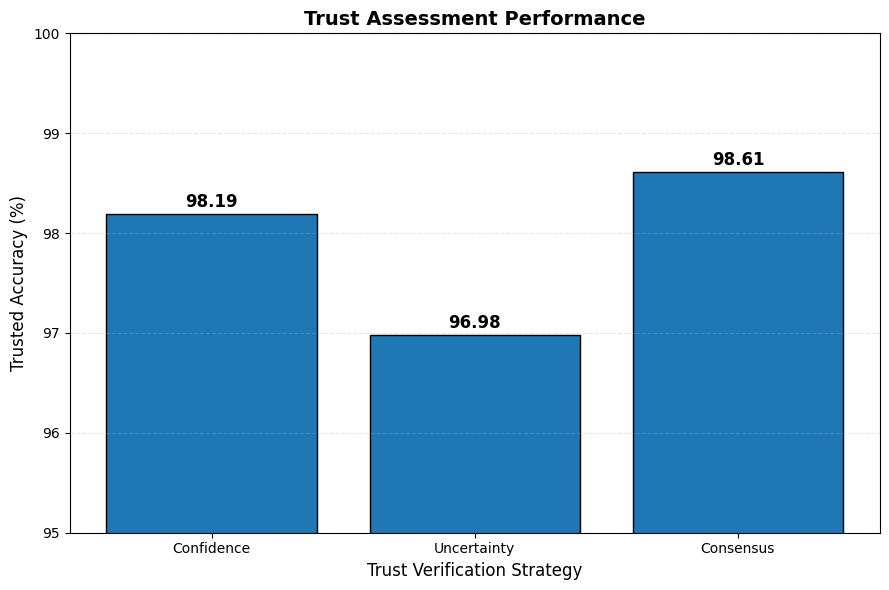

In [ ]:
# =========================================================
# FIGURE 7
# UPDATED TRUSTED PREDICTION ACCURACY COMPARISON
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# =========================================================
# LOAD VALIDATION-DERIVED THRESHOLDS
# =========================================================

CONF_THRESHOLD = np.load(
    "/content/drive/MyDrive/confidence_threshold.npy"
).item()

UNC_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

# =========================================================
# CONFIDENCE-BASED TRUST
# =========================================================

confidence_mask = (
    all_confidences >= CONF_THRESHOLD
)

confidence_samples = np.sum(
    confidence_mask
)

confidence_accuracy = accuracy_score(
    all_labels[confidence_mask],
    all_predictions[confidence_mask]
)

# =========================================================
# UNCERTAINTY-BASED TRUST
# =========================================================

uncertainty_mask = (
    all_uncertainties <= UNC_THRESHOLD
)

uncertainty_samples = np.sum(
    uncertainty_mask
)

uncertainty_accuracy = accuracy_score(
    all_labels[uncertainty_mask],
    all_predictions[uncertainty_mask]
)

# =========================================================
# CONSENSUS TRUST
# BOTH CONDITIONS MUST BE SATISFIED
# =========================================================

consensus_mask = (
    confidence_mask &
    uncertainty_mask
)

consensus_samples = np.sum(
    consensus_mask
)

consensus_accuracy = accuracy_score(
    all_labels[consensus_mask],
    all_predictions[consensus_mask]
)

# =========================================================
# PRINT RESULTS
# =========================================================

print("\n======================================")
print("UPDATED TRUST ASSESSMENT RESULTS")
print("======================================")

print(
    f"Confidence Threshold  : {CONF_THRESHOLD:.8f}"
)

print(
    f"Uncertainty Threshold : {UNC_THRESHOLD:.8f}"
)

print("\n--------------------------------------")

print(
    f"Confidence Trusted Samples  : "
    f"{confidence_samples}"
)

print(
    f"Confidence Accuracy         : "
    f"{confidence_accuracy*100:.2f}%"
)

print(
    f"Uncertainty Trusted Samples : "
    f"{uncertainty_samples}"
)

print(
    f"Uncertainty Accuracy        : "
    f"{uncertainty_accuracy*100:.2f}%"
)

print(
    f"Consensus Trusted Samples   : "
    f"{consensus_samples}"
)

print(
    f"Consensus Accuracy          : "
    f"{consensus_accuracy*100:.2f}%"
)

# =========================================================
# VALUES FOR FIGURE
# =========================================================

strategies = [
    "Confidence",
    "Uncertainty",
    "Consensus"
]

accuracies = [
    confidence_accuracy * 100,
    uncertainty_accuracy * 100,
    consensus_accuracy * 100
]

# =========================================================
# FIGURE
# =========================================================

plt.figure(figsize=(9, 6))

bars = plt.bar(
    strategies,
    accuracies,
    edgecolor="black",
    linewidth=1
)

# =========================================================
# VALUE LABELS
# =========================================================

for bar, value in zip(
    bars,
    accuracies
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.03,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# =========================================================
# AXIS / TITLE
# =========================================================

plt.ylabel(
    "Trusted Accuracy (%)",
    fontsize=12
)

plt.xlabel(
    "Trust Verification Strategy",
    fontsize=12
)

plt.title(
    "Trust Assessment Performance",
    fontsize=14,
    fontweight="bold"
)

# Keep the same visual range as your original figure
plt.ylim(
    95,
    100
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
# =========================================================
# FINAL CONSENSUS GRAD-CAM++ ACTIVATION ANALYSIS
# CORRECTED VERSION
# =========================================================

import numpy as np

# =========================================================
# FINAL THRESHOLDS
# =========================================================

CONF_THRESHOLD = 0.80
UNC_THRESHOLD = 0.00012634

# =========================================================
# CONVERT ARRAYS
# =========================================================

all_confidences = np.asarray(
    all_confidences
)

all_uncertainties = np.asarray(
    all_uncertainties
)

all_activation_scores = np.asarray(
    all_activation_scores
)

# =========================================================
# SAFETY CHECK
# =========================================================

print("======================================")
print("FINAL CONSENSUS GRAD-CAM++ ANALYSIS")
print("======================================")

print(
    "Total Activation Scores :",
    len(all_activation_scores)
)

print(
    "Total Confidence Scores :",
    len(all_confidences)
)

print(
    "Total Uncertainty Scores:",
    len(all_uncertainties)
)

# =========================================================
# FINAL CONSENSUS MASK
# =========================================================

confidence_mask = (
    all_confidences >= CONF_THRESHOLD
)

uncertainty_mask = (
    all_uncertainties <= UNC_THRESHOLD
)

final_trusted_mask = (
    confidence_mask &
    uncertainty_mask
)

final_referred_mask = (
    ~final_trusted_mask
)

# =========================================================
# CHECK FINAL GROUPS
# =========================================================

print("\n======================================")
print("FINAL TRUST GROUPS")
print("======================================")

print(
    "Total Samples    :",
    len(final_trusted_mask)
)

print(
    "Trusted Samples  :",
    final_trusted_mask.sum()
)

print(
    "Referred Samples :",
    final_referred_mask.sum()
)

print(
    "Coverage         :",
    f"{final_trusted_mask.mean()*100:.2f}%"
)

# =========================================================
# IMPORTANT SAFETY CHECK
# =========================================================

assert len(all_activation_scores) == len(final_trusted_mask), \
    "Activation scores and trust masks have different lengths!"

# =========================================================
# SPLIT ACTIVATION SCORES
# =========================================================

trusted_activation = (
    all_activation_scores[
        final_trusted_mask
    ]
)

referred_activation = (
    all_activation_scores[
        final_referred_mask
    ]
)

# =========================================================
# STATISTICS
# =========================================================

trusted_mean = np.mean(
    trusted_activation
)

trusted_std = np.std(
    trusted_activation
)

referred_mean = np.mean(
    referred_activation
)

referred_std = np.std(
    referred_activation
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n======================================")
print("FINAL TRUSTED vs REFERRED ACTIVATION")
print("======================================")

print(
    f"Trusted Samples          : "
    f"{len(trusted_activation)}"
)

print(
    f"Trusted Mean Activation  : "
    f"{trusted_mean:.4f}"
)

print(
    f"Trusted Std              : "
    f"{trusted_std:.4f}"
)

print()

print(
    f"Referred Samples         : "
    f"{len(referred_activation)}"
)

print(
    f"Referred Mean Activation : "
    f"{referred_mean:.4f}"
)

print(
    f"Referred Std             : "
    f"{referred_std:.4f}"
)

FINAL CONSENSUS GRAD-CAM++ ANALYSIS
Total Activation Scores : 1592
Total Confidence Scores : 1592
Total Uncertainty Scores: 1592

FINAL TRUST GROUPS
Total Samples    : 1592
Trusted Samples  : 1206
Referred Samples : 386
Coverage         : 75.75%

FINAL TRUSTED vs REFERRED ACTIVATION
Trusted Samples          : 1206
Trusted Mean Activation  : 0.4561
Trusted Std              : 0.0903

Referred Samples         : 386
Referred Mean Activation : 0.4045
Referred Std             : 0.1048


In [ ]:
# =========================================================
# FINAL CONSISTENT TRUST + GRAD-CAM++ ANALYSIS
# ONE RUN — SAME TEST ORDER
# =========================================================

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# =========================================================
# SETTINGS
# =========================================================

MC_SAMPLES = 3

CONF_THRESHOLD = 0.80
UNC_THRESHOLD = 0.00012634

# =========================================================
# STORAGE
# =========================================================

final_confidences = []
final_uncertainties = []
final_predictions = []
final_labels = []

# =========================================================
# MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if isinstance(module, torch.nn.Dropout):
            module.train()

# =========================================================
# FINAL MC INFERENCE
# =========================================================

model.eval()

print("======================================")
print("FINAL CONSISTENT MC INFERENCE")
print("======================================")

for images, labels in tqdm(
    test_loader,
    desc="MC Test Inference"
):

    images = images.to(device)

    enable_dropout(model)

    mc_probs = []

    with torch.no_grad():

        for _ in range(MC_SAMPLES):

            outputs = model(images)

            probs = F.softmax(
                outputs,
                dim=1
            )

            mc_probs.append(
                probs.cpu().numpy()
            )

    mc_probs = np.asarray(mc_probs)

    # Mean probability
    mean_probs = np.mean(
        mc_probs,
        axis=0
    )

    # Confidence
    confidence = np.max(
        mean_probs,
        axis=1
    )

    # MC variance uncertainty
    uncertainty = np.var(
        mc_probs,
        axis=0
    ).mean(axis=1)

    # Prediction
    predictions = np.argmax(
        mean_probs,
        axis=1
    )

    final_confidences.extend(confidence)
    final_uncertainties.extend(uncertainty)
    final_predictions.extend(predictions)
    final_labels.extend(labels.numpy())

# =========================================================
# NUMPY
# =========================================================

final_confidences = np.asarray(
    final_confidences
)

final_uncertainties = np.asarray(
    final_uncertainties
)

final_predictions = np.asarray(
    final_predictions
)

final_labels = np.asarray(
    final_labels
)

print("\n======================================")
print("MC INFERENCE COMPLETED")
print("======================================")

print(
    "Test Samples :",
    len(final_labels)
)

# =========================================================
# FINAL CONSENSUS MASK
# =========================================================

confidence_mask = (
    final_confidences >= CONF_THRESHOLD
)

uncertainty_mask = (
    final_uncertainties <= UNC_THRESHOLD
)

final_trusted_mask = (
    confidence_mask &
    uncertainty_mask
)

final_referred_mask = (
    ~final_trusted_mask
)

print("\n======================================")
print("FINAL TRUST GROUPS")
print("======================================")

print(
    "Trusted Samples  :",
    final_trusted_mask.sum()
)

print(
    "Referred Samples :",
    final_referred_mask.sum()
)

print(
    "Coverage         :",
    f"{final_trusted_mask.mean()*100:.2f}%"
)

# =========================================================
# GRAD-CAM++ ACTIVATION
# =========================================================

final_activation_scores = []

model.eval()

print("\n======================================")
print("GRAD-CAM++ ANALYSIS")
print("======================================")

for images, labels in tqdm(
    test_loader,
    desc="Grad-CAM++"
):

    images = images.to(device)

    for i in range(images.size(0)):

        input_tensor = images[i].unsqueeze(0)

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=None
        )[0]

        activation_score = float(
            np.mean(grayscale_cam)
        )

        final_activation_scores.append(
            activation_score
        )

final_activation_scores = np.asarray(
    final_activation_scores
)

# =========================================================
# SAFETY CHECK
# =========================================================

assert len(final_activation_scores) == len(
    final_trusted_mask
)

print("\n======================================")
print("GRAD-CAM++ COMPLETED")
print("======================================")

print(
    "Activation Scores :",
    len(final_activation_scores)
)

# =========================================================
# TRUSTED / REFERRED ACTIVATION
# =========================================================

trusted_activation = (
    final_activation_scores[
        final_trusted_mask
    ]
)

referred_activation = (
    final_activation_scores[
        final_referred_mask
    ]
)

# =========================================================
# STATISTICS
# =========================================================

trusted_mean = np.mean(
    trusted_activation
)

trusted_std = np.std(
    trusted_activation
)

referred_mean = np.mean(
    referred_activation
)

referred_std = np.std(
    referred_activation
)

# =========================================================
# FINAL ACTIVATION RESULT
# =========================================================

print("\n======================================")
print("FINAL TRUSTED vs REFERRED ACTIVATION")
print("======================================")

print(
    f"Trusted Samples          : "
    f"{len(trusted_activation)}"
)

print(
    f"Trusted Mean Activation  : "
    f"{trusted_mean:.4f}"
)

print(
    f"Trusted Std              : "
    f"{trusted_std:.4f}"
)

print()

print(
    f"Referred Samples         : "
    f"{len(referred_activation)}"
)

print(
    f"Referred Mean Activation : "
    f"{referred_mean:.4f}"
)

print(
    f"Referred Std             : "
    f"{referred_std:.4f}"
)

FINAL CONSISTENT MC INFERENCE


MC Test Inference:   0%|          | 0/100 [00:00<?, ?it/s]


MC INFERENCE COMPLETED
Test Samples : 1592

FINAL TRUST GROUPS
Trusted Samples  : 1217
Referred Samples : 375
Coverage         : 76.44%

GRAD-CAM++ ANALYSIS


Grad-CAM++:   0%|          | 0/100 [00:00<?, ?it/s]


GRAD-CAM++ COMPLETED
Activation Scores : 1592

FINAL TRUSTED vs REFERRED ACTIVATION
Trusted Samples          : 1217
Trusted Mean Activation  : 0.4530
Trusted Std              : 0.0922

Referred Samples         : 375
Referred Mean Activation : 0.4131
Referred Std             : 0.1039


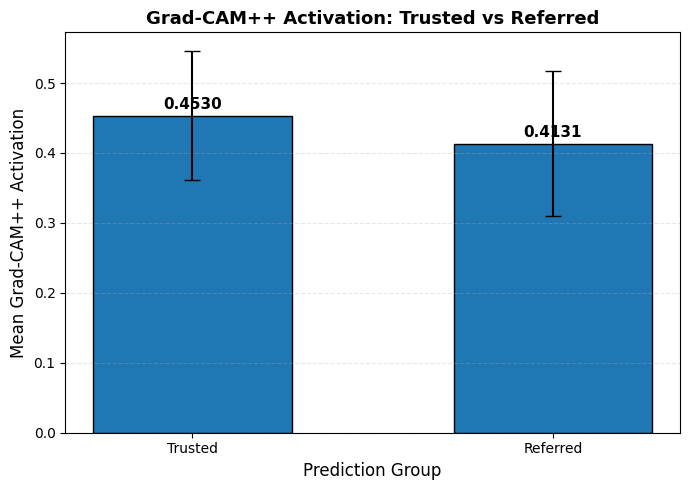

In [ ]:
# =========================================================
# FINAL GRAD-CAM++ ACTIVATION FIGURE
# =========================================================

import matplotlib.pyplot as plt

groups = [
    "Trusted",
    "Referred"
]

means = [
    0.4530,
    0.4131
]

stds = [
    0.0922,
    0.1039
]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    groups,
    means,
    yerr=stds,
    capsize=6,
    width=0.55,
    edgecolor="black",
    linewidth=1
)

for bar, value in zip(bars, means):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.005,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.ylabel(
    "Mean Grad-CAM++ Activation",
    fontsize=12
)

plt.xlabel(
    "Prediction Group",
    fontsize=12
)

plt.title(
    "Grad-CAM++ Activation: Trusted vs Referred",
    fontsize=13,
    fontweight="bold"
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

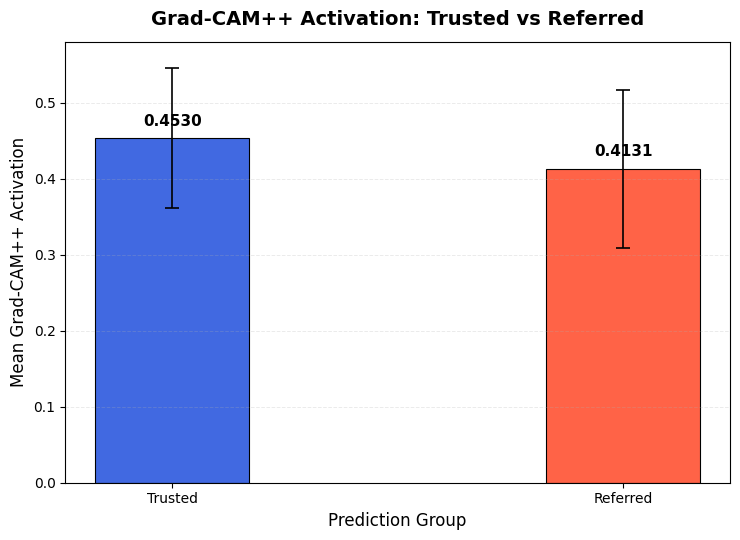

In [ ]:
# =========================================================
# FINAL GRAD-CAM++ FIGURE — THINNER BARS
# =========================================================

import matplotlib.pyplot as plt

groups = [
    "Trusted",
    "Referred"
]

means = [
    0.4530,
    0.4131
]

stds = [
    0.0922,
    0.1039
]

colors = [
    "royalblue",
    "tomato"
]

plt.figure(figsize=(7.5, 5.5))

bars = plt.bar(
    groups,
    means,
    yerr=stds,
    width=0.34,          # thinner bars
    capsize=5,
    color=colors,
    edgecolor="black",
    linewidth=0.8,
    error_kw={
        "elinewidth": 1.2,
        "capthick": 1.2
    }
)

# ---------------------------------------------------------
# Value labels
# ---------------------------------------------------------

for bar, value in zip(bars, means):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.012,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# ---------------------------------------------------------
# Labels
# ---------------------------------------------------------

plt.ylabel(
    "Mean Grad-CAM++ Activation",
    fontsize=12
)

plt.xlabel(
    "Prediction Group",
    fontsize=12
)

plt.title(
    "Grad-CAM++ Activation: Trusted vs Referred",
    fontsize=14,
    fontweight="bold",
    pad=12
)

# ---------------------------------------------------------
# Axis
# ---------------------------------------------------------

plt.ylim(0, 0.58)

# ---------------------------------------------------------
# Grid
# ---------------------------------------------------------

plt.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.25
)

plt.tight_layout()

plt.show()

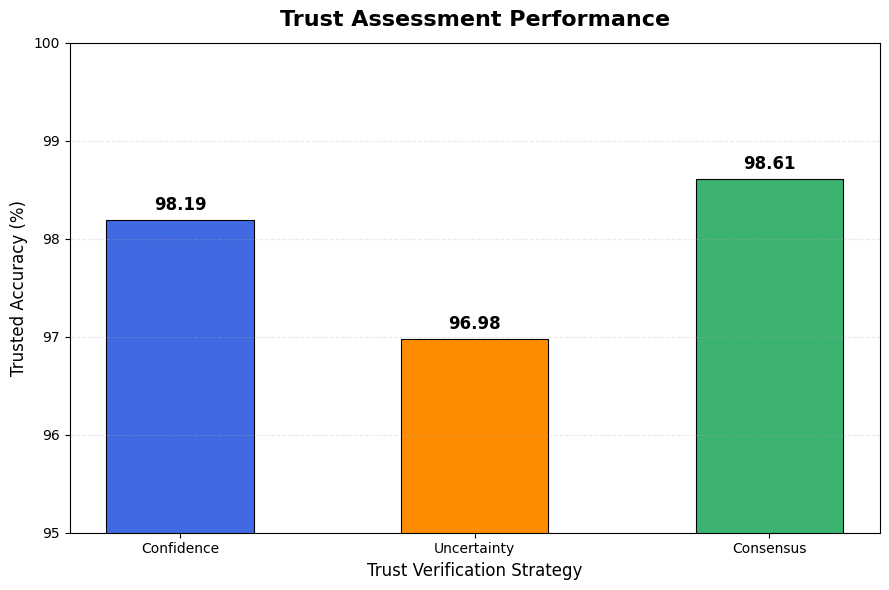

In [ ]:
# =========================================================
# FIGURE 7
# TRUST ASSESSMENT PERFORMANCE
# =========================================================

import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Results
# ---------------------------------------------------------

strategies = [
    "Confidence",
    "Uncertainty",
    "Consensus"
]

accuracies = [
    98.19,
    96.98,
    98.61
]

# Three different colors
colors = [
    "royalblue",
    "darkorange",
    "mediumseagreen"
]

# ---------------------------------------------------------
# Figure
# ---------------------------------------------------------

plt.figure(figsize=(9, 6))

bars = plt.bar(
    strategies,
    accuracies,
    width=0.50,              # thinner columns
    color=colors,
    edgecolor="black",
    linewidth=0.8
)

# ---------------------------------------------------------
# Value Labels
# ---------------------------------------------------------

for bar, value in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.06,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# ---------------------------------------------------------
# Labels and Title
# ---------------------------------------------------------

plt.title(
    "Trust Assessment Performance",
    fontsize=16,
    fontweight="bold",
    pad=12
)

plt.xlabel(
    "Trust Verification Strategy",
    fontsize=12
)

plt.ylabel(
    "Trusted Accuracy (%)",
    fontsize=12
)

# ---------------------------------------------------------
# Axis Range
# ---------------------------------------------------------

plt.ylim(
    95,
    100
)

# ---------------------------------------------------------
# Grid
# ---------------------------------------------------------

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# ---------------------------------------------------------
# Layout
# ---------------------------------------------------------

plt.tight_layout()

plt.show()

In [ ]:
model = ProposedModel(num_classes=5)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

NameError: name 'ProposedModel' is not defined

In [ ]:
# =========================================================
# LOAD BEST MODEL
# =========================================================

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create model
model = ProposedModel(num_classes=5)

# Load trained weights
checkpoint = torch.load(
    "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth",
    map_location=device
)

model.load_state_dict(checkpoint)

# Move to device
model = model.to(device)

# Evaluation mode
model.eval()

print("===================================")
print("Best Model Loaded Successfully!")
print("===================================")

NameError: name 'ProposedModel' is not defined

In [ ]:
'ProposedModel' in globals()

False

In [ ]:
# =========================================================
# TRUSTED VS REFERRED ACTIVATION
# =========================================================

trusted_activation = all_activation_scores[
    final_trusted_2
]

referred_activation = all_activation_scores[
    final_referred_2
]

print("\n===== ACTIVATION ANALYSIS =====")

print(
    "Trusted Mean Activation:",
    trusted_activation.mean()
)

print(
    "Trusted Std:",
    trusted_activation.std()
)

print(
    "Referred Mean Activation:",
    referred_activation.mean()
)

print(
    "Referred Std:",
    referred_activation.std()
)

print(
    "\nActivation Difference:",
    trusted_activation.mean()
    -
    referred_activation.mean()
)


===== ACTIVATION ANALYSIS =====
Trusted Mean Activation: 0.4523015
Trusted Std: 0.091315895
Referred Mean Activation: 0.41588944
Referred Std: 0.107180595

Activation Difference: 0.03641206


In [ ]:
# ==========================================
# TOP REFERRED
# ==========================================

referred_uncertainties = np.array(
    all_uncertainties
)[final_referred_2]

top_referred_local = np.argsort(
    referred_uncertainties
)[-3:]

top_referred_indices = referred_indices[
    top_referred_local
]

print("Top Referred Indices:")
print(top_referred_indices)

Top Referred Indices:
[1258 1263 1260]


In [ ]:
import numpy as np

trusted_indices = np.where(
    final_trusted_2
)[0]

referred_indices = np.where(
    final_referred_2
)[0]

print("Trusted:", len(trusted_indices))
print("Referred:", len(referred_indices))

Trusted: 1213
Referred: 379


In [ ]:
# ==========================================
# TOP 3 TRUSTED
# ==========================================

trusted_confidences = np.array(
    all_confidences
)[final_trusted_2]

top_trusted_local = np.argsort(
    trusted_confidences
)[-3:]

top_trusted_indices = trusted_indices[
    top_trusted_local
]

print("Top Trusted:")
print(top_trusted_indices)

Top Trusted:
[1144 1108 1104]


In [ ]:
trusted_mid = trusted_indices[
    np.linspace(
        0,
        len(trusted_indices)-1,
        3,
        dtype=int
    )
]

referred_mid = referred_indices[
    np.linspace(
        0,
        len(referred_indices)-1,
        3,
        dtype=int
    )
]

print("Trusted Examples:", trusted_mid)
print("Referred Examples:", referred_mid)

Trusted Examples: [   0  785 1591]
Referred Examples: [   1  831 1590]


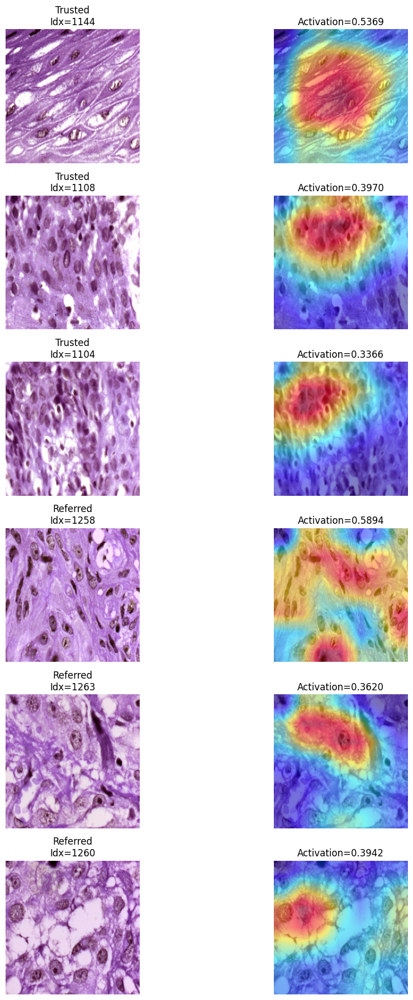

In [ ]:
# =========================================================
# VISUALIZE TRUSTED & REFERRED SAMPLES
# =========================================================

import matplotlib.pyplot as plt
import numpy as np

trusted_examples = [1144, 1108, 1104]
referred_examples = [1258, 1263, 1260]

selected_indices = (
    trusted_examples +
    referred_examples
)

titles = (
    ["Trusted"] * 3 +
    ["Referred"] * 3
)

plt.figure(figsize=(12,18))

for plot_idx, sample_idx in enumerate(selected_indices):

    img_tensor, label = test_dataset[sample_idx]

    input_tensor = (
        img_tensor
        .unsqueeze(0)
        .to(device)
    )

    grayscale_cam = cam(
        input_tensor=input_tensor
    )[0]

    img_np = (
        img_tensor
        .permute(1,2,0)
        .cpu()
        .numpy()
    )

    # de-normalize
    mean = np.array(
        [0.485,0.456,0.406]
    )

    std = np.array(
        [0.229,0.224,0.225]
    )

    img_np = (
        img_np * std + mean
    )

    img_np = np.clip(
        img_np,
        0,
        1
    )

    visualization = show_cam_on_image(
        img_np,
        grayscale_cam,
        use_rgb=True
    )

    activation_score = np.mean(
        grayscale_cam
    )

    # =====================================
    # ORIGINAL
    # =====================================

    plt.subplot(
        6,2,
        plot_idx*2 + 1
    )

    plt.imshow(img_np)

    plt.title(
        f"{titles[plot_idx]}\n"
        f"Idx={sample_idx}"
    )

    plt.axis("off")

    # =====================================
    # GRADCAM++
    # =====================================

    plt.subplot(
        6,2,
        plot_idx*2 + 2
    )

    plt.imshow(
        visualization
    )

    plt.title(
        f"Activation="
        f"{activation_score:.4f}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

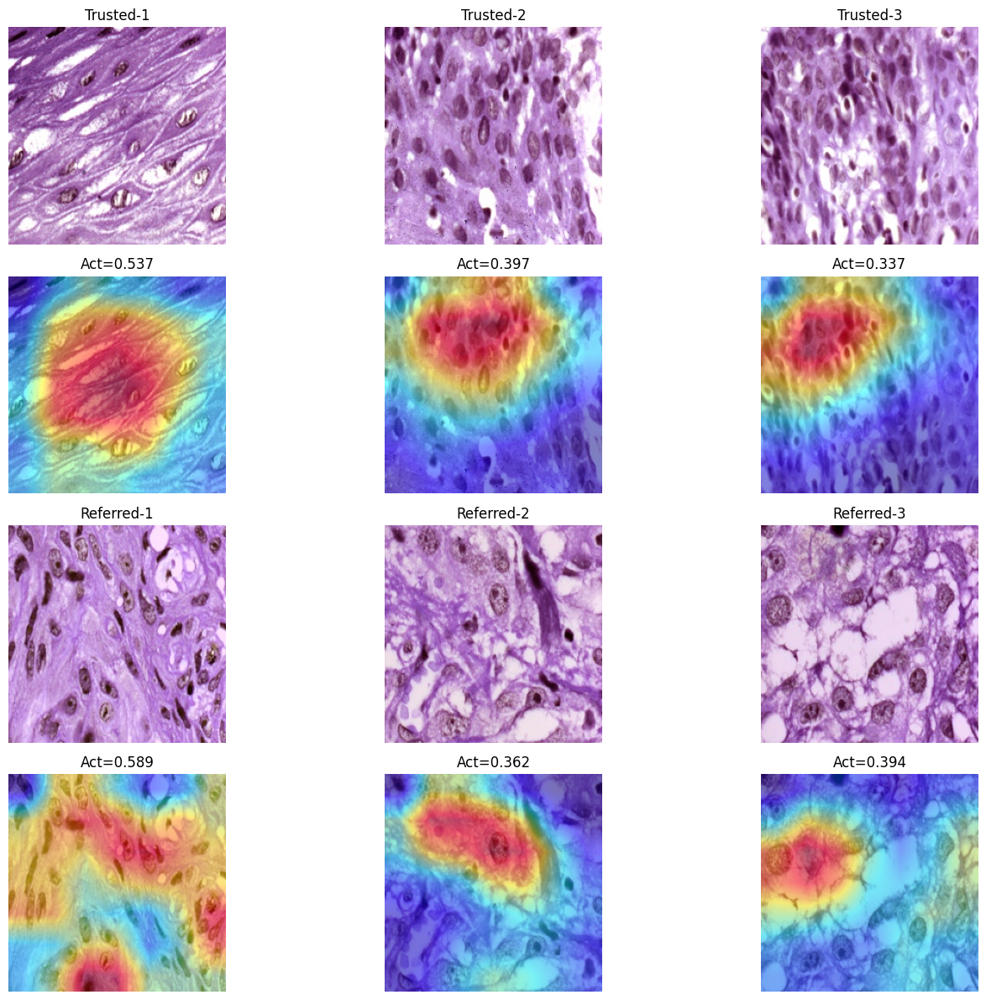

In [ ]:
plt.figure(figsize=(15,12))

# =========================
# TRUSTED
# =========================

for col, sample_idx in enumerate(trusted_examples):

    img_tensor, label = test_dataset[sample_idx]

    input_tensor = img_tensor.unsqueeze(0).to(device)

    grayscale_cam = cam(
        input_tensor=input_tensor
    )[0]

    img_np = img_tensor.permute(
        1,2,0
    ).cpu().numpy()

    mean = np.array(
        [0.485,0.456,0.406]
    )

    std = np.array(
        [0.229,0.224,0.225]
    )

    img_np = img_np * std + mean

    img_np = np.clip(
        img_np,
        0,
        1
    )

    visualization = show_cam_on_image(
        img_np,
        grayscale_cam,
        use_rgb=True
    )

    # Row 1
    plt.subplot(4,3,col+1)

    plt.imshow(img_np)

    plt.title(
        f"Trusted-{col+1}"
    )

    plt.axis("off")

    # Row 2
    plt.subplot(4,3,col+4)

    plt.imshow(
        visualization
    )

    plt.title(
        f"Act={np.mean(grayscale_cam):.3f}"
    )

    plt.axis("off")


# =========================
# REFERRED
# =========================

for col, sample_idx in enumerate(referred_examples):

    img_tensor, label = test_dataset[sample_idx]

    input_tensor = img_tensor.unsqueeze(0).to(device)

    grayscale_cam = cam(
        input_tensor=input_tensor
    )[0]

    img_np = img_tensor.permute(
        1,2,0
    ).cpu().numpy()

    img_np = img_np * std + mean

    img_np = np.clip(
        img_np,
        0,
        1
    )

    visualization = show_cam_on_image(
        img_np,
        grayscale_cam,
        use_rgb=True
    )

    # Row 3
    plt.subplot(4,3,col+7)

    plt.imshow(img_np)

    plt.title(
        f"Referred-{col+1}"
    )

    plt.axis("off")

    # Row 4
    plt.subplot(4,3,col+10)

    plt.imshow(
        visualization
    )

    plt.title(
        f"Act={np.mean(grayscale_cam):.3f}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

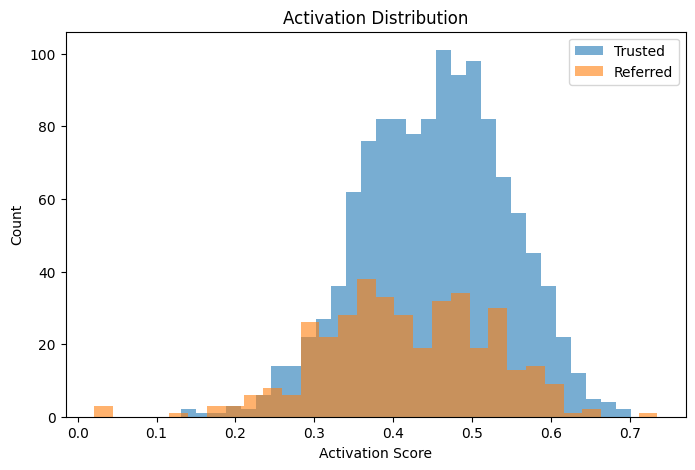

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    trusted_activation,
    bins=30,
    alpha=0.6,
    label="Trusted"
)

plt.hist(
    referred_activation,
    bins=30,
    alpha=0.6,
    label="Referred"
)

plt.legend()

plt.xlabel("Activation Score")

plt.ylabel("Count")

plt.title(
    "Activation Distribution"
)

plt.show()

/tmp/ipykernel_94236/1997494656.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


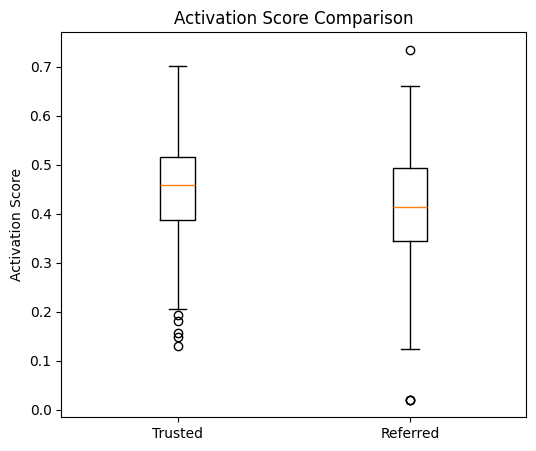

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

plt.boxplot(
    [trusted_activation, referred_activation],
    labels=["Trusted", "Referred"]
)

plt.ylabel("Activation Score")

plt.title(
    "Activation Score Comparison"
)

plt.show()

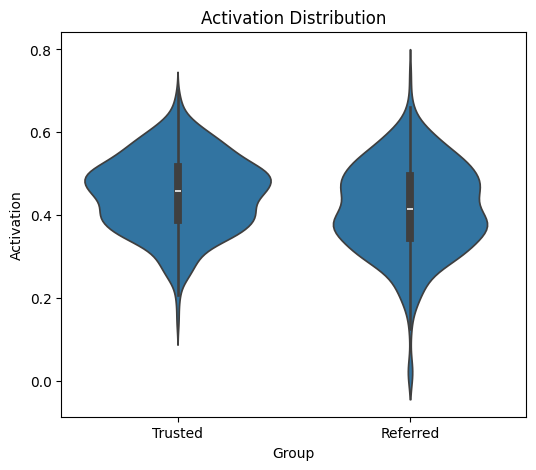

In [ ]:
import seaborn as sns
import pandas as pd

df = pd.DataFrame({
    "Activation":
        np.concatenate(
            [trusted_activation,
             referred_activation]
        ),
    "Group":
        ["Trusted"]*len(trusted_activation)
        +
        ["Referred"]*len(referred_activation)
})

plt.figure(figsize=(6,5))

sns.violinplot(
    data=df,
    x="Group",
    y="Activation"
)

plt.title(
    "Activation Distribution"
)

plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

means = [
    trusted_activation.mean(),
    referred_activation.mean()
]

stds = [
    trusted_activation.std(),
    referred_activation.std()
]

labels = [
    "Trusted",
    "Referred"
]

colors = [
    "#02006c",   # Blue
    "#8b008b"    # Red
]

plt.figure(figsize=(6,5))

bars = plt.bar(
    labels,
    means,
    yerr=stds,
    capsize=8,
    color=colors,
    edgecolor="black",
    linewidth=1.5
)

for bar, value in zip(bars, means):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.01,
        f"{value:.3f}",
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.ylabel(
    "Mean Grad-CAM++ Activation"
)

plt.title(
    "Trusted vs Referred Activation Analysis",
    fontsize=13,
    fontweight='bold'
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.4
)

plt.tight_layout()

plt.show()

NameError: name 'trusted_activation' is not defined

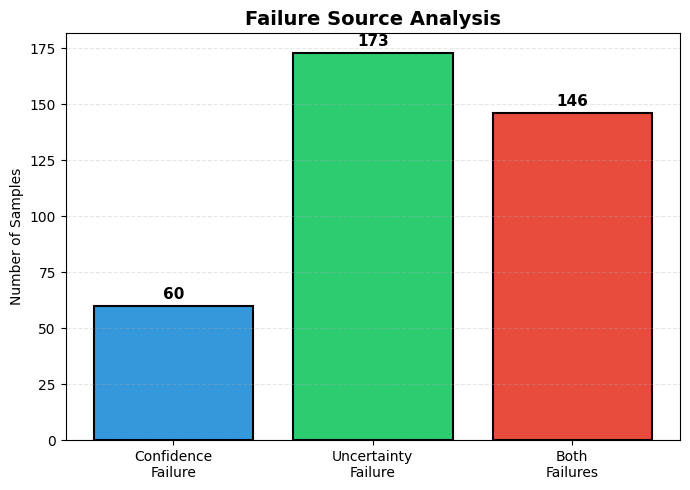

In [ ]:
import matplotlib.pyplot as plt

categories = [
    "Confidence\nFailure",
    "Uncertainty\nFailure",
    "Both\nFailures"
]

values = [60, 173, 146]

colors = [
    "#3498db",
    "#2ecc71",
    "#e74c3c"
]

plt.figure(figsize=(7,5))

bars = plt.bar(
    categories,
    values,
    color=colors,
    edgecolor='black',
    linewidth=1.5
)

for bar in bars:

    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+3,
        str(int(bar.get_height())),
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.ylabel("Number of Samples")

plt.title(
    "Failure Source Analysis",
    fontsize=14,
    fontweight='bold'
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()
plt.show()

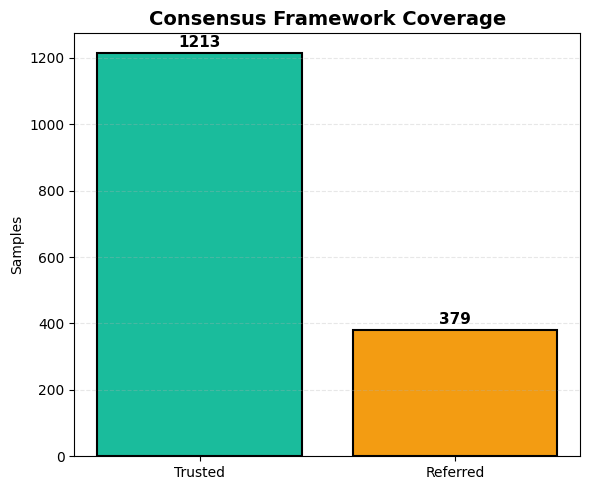

In [ ]:
import matplotlib.pyplot as plt

labels = [
    "Trusted",
    "Referred"
]

values = [
    1213,
    379
]

colors = [
    "#1abc9c",
    "#f39c12"
]

plt.figure(figsize=(6,5))

bars = plt.bar(
    labels,
    values,
    color=colors,
    edgecolor='black',
    linewidth=1.5
)

for bar in bars:

    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+20,
        str(int(bar.get_height())),
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.ylabel("Samples")

plt.title(
    "Consensus Framework Coverage",
    fontsize=14,
    fontweight='bold'
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()
plt.show()

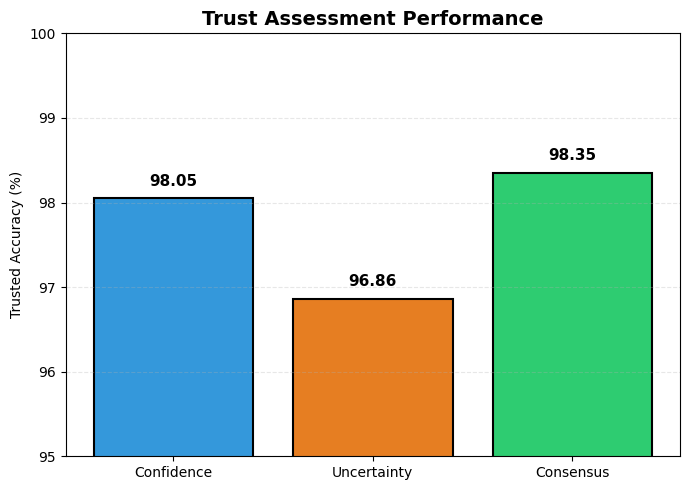

In [ ]:
import matplotlib.pyplot as plt

methods = [
    "Confidence",
    "Uncertainty",
    "Consensus"
]

acc = [
    98.05,
    96.86,
    98.35
]

colors = [
    "#3498db",
    "#e67e22",
    "#2ecc71"
]

plt.figure(figsize=(7,5))

bars = plt.bar(
    methods,
    acc,
    color=colors,
    edgecolor='black',
    linewidth=1.5
)

for bar in bars:

    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.15,
        f"{bar.get_height():.2f}",
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.ylabel("Trusted Accuracy (%)")

plt.title(
    "Trust Assessment Performance",
    fontsize=14,
    fontweight='bold'
)

plt.ylim(95,100)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()
plt.show()

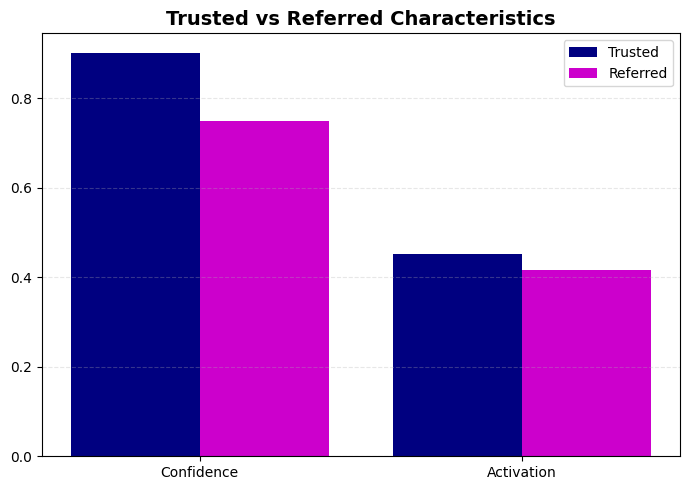

In [ ]:
import matplotlib.pyplot as plt

metrics = [
    "Confidence",
    "Activation"
]

trusted = [
    0.8999,
    0.4523
]

referred = [
    0.7500,
    0.4159
]

x = range(len(metrics))

plt.figure(figsize=(7,5))

plt.bar(
    [i-0.2 for i in x],
    trusted,
    width=0.4,
    label="Trusted",
    color="#000080"
)

plt.bar(
    [i+0.2 for i in x],
    referred,
    width=0.4,
    label="Referred",
    color="#CC00CC"
)

plt.xticks(x, metrics)

plt.title(
    "Trusted vs Referred Characteristics",
    fontsize=14,
    fontweight='bold'
)

plt.legend()

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [ ]:
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
import os

train_path = "/content/drive/MyDrive/ORCHID_224_JPG"
val_path   = "/content/drive/MyDrive/val"
test_path  = "/content/drive/MyDrive/test/test"

def count_images(folder):
    total = 0
    for cls in os.listdir(folder):
        cls_path = os.path.join(folder, cls)
        if os.path.isdir(cls_path):
            total += len(os.listdir(cls_path))
    return total

print("Train Images :", count_images(train_path))
print("Validation Images :", count_images(val_path))
print("Test Images :", count_images(test_path))

Train Images : 149
Validation Images : 149
Test Images : 150


In [ ]:
import os

base_dir = '/content/drive/MyDrive/ORCHID_PROJECT'
os.makedirs(base_dir, exist_ok=True)

print('Folder created:', base_dir)

Folder created: /content/drive/MyDrive/ORCHID_PROJECT


In [ ]:
!wget -c "https://zenodo.org/records/12636426/files/train.zip?download=1" -O /content/train.zip

--2026-08-07 18:08:58--  https://zenodo.org/records/12636426/files/train.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.184.103.118, 137.138.52.235, 188.184.98.114, ...
Connecting to zenodo.org (zenodo.org)|188.184.103.118|:443... connected.
HTTP request sent, awaiting response... 206 PARTIAL_CONTENT
Length: 39745604871 (37G), 32225067815 (30G) remaining [application/octet-stream]
Saving to: ‘/content/train.zip’

/content/train.zip   19%[+++                 ]   7.11G   791KB/s    eta 13h 6m ^C


In [ ]:
import zipfile
import os

extract_path = "/content/train_data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile('/content/train.zip', 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction Complete")

Extraction Complete


In [ ]:
!du -sh /content/*

^C


In [ ]:
print("Extraction Complete")

Extraction Complete


In [ ]:
!rm /content/train.zip

In [ ]:
!df -h

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   58G   51G  54% /
tmpfs            64M     0   64M   0% /dev
shm             5.7G     0  5.7G   0% /dev/shm
/dev/root       2.0G  1.3G  696M  65% /usr/sbin/docker-init
tmpfs           6.4G   72K  6.4G   1% /var/colab
/dev/sda1       114G   96G   19G  84% /kaggle/input
tmpfs           6.4G     0  6.4G   0% /proc/acpi
tmpfs           6.4G     0  6.4G   0% /proc/scsi
tmpfs           6.4G     0  6.4G   0% /sys/firmware
drive            15G   20K   15G   1% /content/drive


In [ ]:
import os
import random
import shutil
from glob import glob

random.seed(42)

# Extracted dataset path
source_root = "/content/train_data"

# Google Drive save path
save_root = "/content/drive/MyDrive/ORCHID_PROJECT/ORCHID_30K"

os.makedirs(save_root, exist_ok=True)

# Update class names if needed
classes = ['Normal', 'OSMF', 'WDOSCC', 'MDOSCC', 'PDOSCC']

IMAGES_PER_CLASS = 6000

for cls in classes:

    print(f"\nProcessing {cls}...")

    class_path = os.path.join(source_root, cls)

    images = glob(os.path.join(class_path, '**', '*.jpg'), recursive=True)
    images += glob(os.path.join(class_path, '**', '*.png'), recursive=True)
    images += glob(os.path.join(class_path, '**', '*.jpeg'), recursive=True)

    print("Total images found:", len(images))

    selected_images = random.sample(images, IMAGES_PER_CLASS)

    save_class_dir = os.path.join(save_root, cls)
    os.makedirs(save_class_dir, exist_ok=True)

    for img_path in selected_images:
        shutil.copy(img_path, save_class_dir)

    print(f"Saved {IMAGES_PER_CLASS} images for {cls}")

print("\n30K balanced dataset saved to Google Drive!")


Processing Normal...
Total images found: 0


ValueError: Sample larger than population or is negative

In [ ]:
import os
from glob import glob

source_root = "/content/train_data/train"

classes = ['normal', 'osmf', 'wdoscc', 'mdoscc', 'pdoscc']

for cls in classes:

    class_path = os.path.join(source_root, cls)

    images = glob(os.path.join(class_path, '**', '*.jpg'), recursive=True)
    images += glob(os.path.join(class_path, '**', '*.png'), recursive=True)
    images += glob(os.path.join(class_path, '**', '*.jpeg'), recursive=True)

    print(f"{cls}: {len(images)} images")

normal: 1045 images
osmf: 2095 images
wdoscc: 2790 images
mdoscc: 2699 images
pdoscc: 1599 images


In [ ]:
import os

source_root = "/content/train_data/train"

extensions = {}

for root, dirs, files in os.walk(source_root):
    for file in files:
        ext = os.path.splitext(file)[1].lower()

        if ext not in extensions:
            extensions[ext] = 0

        extensions[ext] += 1

print(extensions)

{}


In [ ]:
import os

total_images = 0

for root, dirs, files in os.walk("/content/train_data"):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            total_images += 1

print("Total extracted images:", total_images)

Total extracted images: 0


In [ ]:
import os

root = "/content/train_data"

for root_dir, dirs, files in os.walk(root):

    if len(dirs) > 0:
        print("\nPATH:", root_dir)
        print("SUBFOLDERS:", dirs[:10])

    if any(f.endswith('.zip') for f in files):
        print("\nZIP FOUND IN:", root_dir)


PATH: /content/train_data
SUBFOLDERS: ['train']

PATH: /content/train_data/train
SUBFOLDERS: ['pdoscc', 'mdoscc', 'normal', 'osmf', 'wdoscc']

PATH: /content/train_data/train/pdoscc
SUBFOLDERS: ['o-4-00-06', 'o-4-00-07', 'o-4-00-02', 'o-4-00-05', 'o-4-00-14', 'o-4-00-10', 'o-4-00-16', 'o-4-00-01', 'o-4-00-09', 'o-4-00-17']

PATH: /content/train_data/train/mdoscc
SUBFOLDERS: ['o-3-00-25', 'o-3-00-36', 'o-3-00-39', 'o-3-00-07', 'o-3-00-05', 'o-3-00-35', 'o-3-00-33', 'o-3-00-41', 'o-3-00-26', 'o-3-00-40']

PATH: /content/train_data/train/normal
SUBFOLDERS: ['o-0-00-13', 'o-0-00-04', 'o-0-00-12', 'o-0-00-01', 'o-0-00-14', 'o-0-00-06', 'o-0-00-10', 'o-0-00-02', 'o-0-00-03', 'o-0-00-05']

PATH: /content/train_data/train/osmf
SUBFOLDERS: ['o-1-00-14', 'o-1-00-04', 'o-1-00-23', 'o-1-00-29', 'o-1-00-18', 'o-1-00-26', 'o-1-00-15', 'o-1-00-31', 'o-1-00-19', 'o-1-00-22']

PATH: /content/train_data/train/wdoscc
SUBFOLDERS: ['o-2-00-43', 'o-2-00-01', 'o-2-00-42', 'o-2-00-33', 'o-2-00-02', 'o-2-00-2

In [ ]:
import shutil
import os

source_folder = "/content/train_data/train"

destination_folder = "/content/drive/MyDrive/ORCHID_PROJECT/ORCHID_FULL_TRAIN"

# Delete if already exists
if os.path.exists(destination_folder):
    shutil.rmtree(destination_folder)

# Copy full dataset to Drive
shutil.copytree(source_folder, destination_folder)

print("Full training dataset saved to Google Drive!")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!wget -c "https://zenodo.org/records/12636426/files/train.zip?download=1" -O /content/train.zip

--2026-05-14 06:11:19--  https://zenodo.org/records/12636426/files/train.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.184.98.114, 188.184.103.118, 188.185.48.75, ...
Connecting to zenodo.org (zenodo.org)|188.184.98.114|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 39745604871 (37G) [application/octet-stream]
Saving to: ‘/content/train.zip’

/content/train.zip  100%[===================>]  37.02G  23.0MB/s    in 27m 26s 

2026-05-14 06:38:46 (23.0 MB/s) - ‘/content/train.zip’ saved [39745604871/39745604871]



In [ ]:
import zipfile

zip_path = "/content/train.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    file_list = z.namelist()

print("Total files:", len(file_list))

# first 50 files/folders
for f in file_list[:50]:
    print(f)

Total files: 10384
train/
train/normal/
train/normal/o-0-00-10/
train/normal/o-0-00-10/o-0-00-10-085.png
train/normal/o-0-00-10/o-0-00-10-046.png
train/normal/o-0-00-10/o-0-00-10-111.png
train/normal/o-0-00-10/o-0-00-10-102.png
train/normal/o-0-00-10/o-0-00-10-025.png
train/normal/o-0-00-10/o-0-00-10-016.png
train/normal/o-0-00-10/o-0-00-10-103.png
train/normal/o-0-00-10/o-0-00-10-058.png
train/normal/o-0-00-10/o-0-00-10-081.png
train/normal/o-0-00-10/o-0-00-10-070.png
train/normal/o-0-00-10/o-0-00-10-114.png
train/normal/o-0-00-10/o-0-00-10-151.png
train/normal/o-0-00-10/o-0-00-10-060.png
train/normal/o-0-00-10/o-0-00-10-052.png
train/normal/o-0-00-10/o-0-00-10-059.png
train/normal/o-0-00-10/o-0-00-10-101.png
train/normal/o-0-00-10/o-0-00-10-109.png
train/normal/o-0-00-10/o-0-00-10-142.png
train/normal/o-0-00-10/o-0-00-10-041.png
train/normal/o-0-00-10/o-0-00-10-062.png
train/normal/o-0-00-10/o-0-00-10-042.png
train/normal/o-0-00-10/o-0-00-10-138.png
train/normal/o-0-00-10/o-0-00-10-0

In [ ]:
import zipfile
from collections import defaultdict

zip_path = "/content/train.zip"

class_counts = defaultdict(int)

with zipfile.ZipFile(zip_path, 'r') as z:

    for file in z.namelist():

        file_lower = file.lower()

        if file_lower.endswith(('.png', '.jpg', '.jpeg')):

            parts = file.replace("\\", "/").split("/")

            for p in parts:

                p_lower = p.lower()

                if p_lower in ['normal', 'osmf', 'wdoscc', 'mdoscc', 'pdoscc']:

                    class_counts[p_lower] += 1

print("\nClass-wise Image Count:\n")

total = 0

for cls, count in class_counts.items():
    print(f"{cls}: {count} images")
    total += count

print(f"\nTotal Images: {total}")


Class-wise Image Count:

normal: 1045 images
osmf: 2095 images
wdoscc: 2790 images
mdoscc: 2699 images
pdoscc: 1599 images

Total Images: 10228


In [ ]:
pip install pillow tqdm

In [ ]:
import os
from PIL import Image
from tqdm import tqdm

# =========================
# INPUT & OUTPUT PATH
# =========================

input_dir = r"D:\ORCHID\train"          # Original extracted train folder
output_dir = r"D:\ORCHID_224_JPG"      # Optimized output folder

# =========================
# SETTINGS
# =========================

IMG_SIZE = (224, 224)
JPEG_QUALITY = 95

# =========================
# PROCESS
# =========================

for root, dirs, files in os.walk(input_dir):

    for file in tqdm(files):

        if file.lower().endswith(('.png', '.jpg', '.jpeg')):

            input_path = os.path.join(root, file)

            # Relative path maintain
            relative_path = os.path.relpath(root, input_dir)

            save_folder = os.path.join(output_dir, relative_path)

            os.makedirs(save_folder, exist_ok=True)

            # Change extension to jpg
            save_name = os.path.splitext(file)[0] + ".jpg"

            save_path = os.path.join(save_folder, save_name)

            try:
                img = Image.open(input_path).convert("RGB")

                # Resize
                img = img.resize(IMG_SIZE)

                # Save as JPG
                img.save(
                    save_path,
                    "JPEG",
                    quality=JPEG_QUALITY,
                    optimize=True
                )

            except Exception as e:
                print(f"Error processing {input_path}")
                print(e)

print("\nOptimization Complete!")


Optimization Complete!


In [ ]:
import os

base = r"D:\ORCHID_224_JPG"

total_images = 0

for cls in os.listdir(base):

    cls_path = os.path.join(base, cls)

    if os.path.isdir(cls_path):

        count = 0

        for root, dirs, files in os.walk(cls_path):

            count += len([
                f for f in files
                if f.lower().endswith(('.jpg', '.jpeg'))
            ])

        print(f"{cls}: {count} images")

        total_images += count

print(f"\nTotal Images: {total_images}")

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\ORCHID_224_JPG'

In [ ]:
import os

print(os.getcwd())

/content


In [ ]:
import os

for item in os.listdir():
    print(item)

.config
train.zip
drive
sample_data


In [ ]:
!mkdir -p /content/train_data

!unzip -q /content/train.zip -d /content/train_data

In [ ]:
import os

base = "/content/train_data/train"

total_images = 0

for cls in os.listdir(base):

    cls_path = os.path.join(base, cls)

    if os.path.isdir(cls_path):

        count = 0

        for root, dirs, files in os.walk(cls_path):

            count += len([
                f for f in files
                if f.lower().endswith(('.png', '.jpg', '.jpeg'))
            ])

        print(f"{cls}: {count} images")

        total_images += count

print(f"\nTotal Images: {total_images}")

osmf: 2095 images
normal: 1045 images
pdoscc: 1599 images
mdoscc: 2699 images
wdoscc: 2790 images

Total Images: 10228


In [ ]:
!mkdir -p /content/drive/MyDrive/ORCHID_224_JPG

In [ ]:
import os
from PIL import Image
from tqdm import tqdm

input_dir = "/content/train_data/train"

output_dir = "/content/drive/MyDrive/ORCHID_224_JPG"

IMG_SIZE = (224, 224)
JPEG_QUALITY = 95

total = 0

for root, dirs, files in os.walk(input_dir):

    for file in tqdm(files):

        if file.lower().endswith(('.png', '.jpg', '.jpeg')):

            input_path = os.path.join(root, file)

            relative_path = os.path.relpath(root, input_dir)

            save_folder = os.path.join(output_dir, relative_path)

            os.makedirs(save_folder, exist_ok=True)

            save_name = os.path.splitext(file)[0] + ".jpg"

            save_path = os.path.join(save_folder, save_name)

            try:
                img = Image.open(input_path).convert("RGB")

                img = img.resize(IMG_SIZE)

                img.save(
                    save_path,
                    "JPEG",
                    quality=JPEG_QUALITY,
                    optimize=True
                )

                total += 1

            except Exception as e:
                print("Error:", input_path)

print(f"\nOptimization Complete! Total Images: {total}")

0it [00:00, ?it/s]
0it [00:00, ?it/s]
100%|██████████| 88/88 [00:05<00:00, 14.71it/s]
0it [00:00, ?it/s]
100%|██████████| 30/30 [00:04<00:00,  6.92it/s]
0it [00:00, ?it/s]
100%|██████████| 71/71 [00:19<00:00,  3.72it/s]
0it [00:00, ?it/s]
100%|██████████| 80/80 [00:20<00:00,  3.83it/s]
0it [00:00, ?it/s]
100%|██████████| 47/47 [00:03<00:00, 15.01it/s]
0it [00:00, ?it/s]
100%|██████████| 67/67 [00:04<00:00, 14.62it/s]



Optimization Complete! Total Images: 10228


In [ ]:
import os

base = "/content/drive/MyDrive/ORCHID_224_JPG"

total_images = 0

for cls in os.listdir(base):

    cls_path = os.path.join(base, cls)

    if os.path.isdir(cls_path):

        count = 0

        for root, dirs, files in os.walk(cls_path):

            count += len([
                f for f in files
                if f.lower().endswith(('.jpg', '.jpeg'))
            ])

        print(f"{cls}: {count} images")

        total_images += count

print(f"\nTotal Images: {total_images}")

osmf: 2095 images
normal: 1045 images
pdoscc: 1599 images
mdoscc: 2699 images
wdoscc: 2790 images

Total Images: 10228


In [ ]:
!du -sh /content/drive/MyDrive/ORCHID_224_JPG

272M	/content/drive/MyDrive/ORCHID_224_JPG


Class: mdoscc
Image: /content/drive/MyDrive/ORCHID_224_JPG/mdoscc/o-3-00-18/o-3-00-18-081.jpg


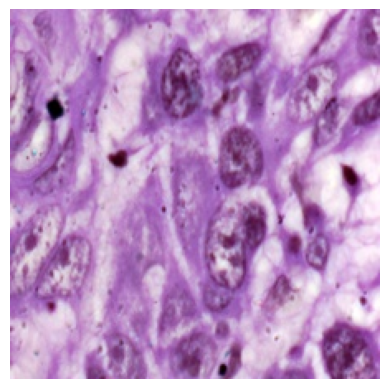

Image Size: (224, 224)


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

base = "/content/drive/MyDrive/ORCHID_224_JPG"

# random class
cls = random.choice(os.listdir(base))

cls_path = os.path.join(base, cls)

# collect images
all_images = []

for root, dirs, files in os.walk(cls_path):
    for f in files:
        if f.lower().endswith(".jpg"):
            all_images.append(os.path.join(root, f))

img_path = random.choice(all_images)

print("Class:", cls)
print("Image:", img_path)

img = Image.open(img_path)

plt.imshow(img)
plt.axis("off")
plt.show()

print("Image Size:", img.size)

In [ ]:
!wget -c "https://zenodo.org/records/12646943/files/val.zip?download=1" -O /content/val.zip

!wget -c "https://zenodo.org/records/12646943/files/test.zip?download=1" -O /content/test.zip

--2026-05-14 10:14:07--  https://zenodo.org/records/12646943/files/val.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.184.103.118, 188.185.43.153, 188.185.48.75, ...
Connecting to zenodo.org (zenodo.org)|188.184.103.118|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 11269377883 (10G) [application/octet-stream]
Saving to: ‘/content/val.zip’

/content/val.zip    100%[===================>]  10.50G  22.9MB/s    in 21m 39s 

2026-05-14 10:35:47 (8.27 MB/s) - ‘/content/val.zip’ saved [11269377883/11269377883]

--2026-05-14 10:35:47--  https://zenodo.org/records/12646943/files/test.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.153.219, 188.185.43.153, 188.184.103.118, ...
Connecting to zenodo.org (zenodo.org)|137.138.153.219|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6138851343 (5.7G) [application/octet-stream]
Saving to: ‘/content/test.zip’

/content/test.zip     1%[                    ]  98.66M  1022KB/s    eta

In [ ]:
!rm -rf /content/train_data

In [ ]:
import os

print(
    os.path.exists(
        "/content/drive/MyDrive/final_proposed_model.pth"
    )
)

True


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive/test/test"))

['osmf', 'normal', 'pdoscc', 'mdoscc', 'wdoscc']


In [ ]:
# =========================================================
# FIXED CBAM FOR MODEL RECOVERY
# =========================================================

class CBAM(nn.Module):

    def __init__(self, in_channels):

        super(CBAM, self).__init__()

        # SAME NAMES AS TRAINING CODE

        self.channel_attention = ChannelAttention(
            in_channels
        )

        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = x * self.channel_attention(x)

        x = x * self.spatial_attention(x)

        return x

# =========================================================
# FIXED MODEL
# =========================================================

class ProposedModel(nn.Module):

    def __init__(self, num_classes=5):

        super(ProposedModel, self).__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

# =========================================================
# LOAD MODEL
# =========================================================

model = ProposedModel(
    num_classes=5
)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/final_proposed_model.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("Model Loaded Successfully!")

NameError: name 'device' is not defined

In [ ]:
import torch
import torch.nn as nn
import timm

# =========================================================
# CHANNEL ATTENTION
# =========================================================

class ChannelAttention(nn.Module):

    def __init__(self, in_channels, reduction=16):
        super(ChannelAttention, self).__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(in_channels, in_channels // reduction, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_channels // reduction, in_channels, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))

        return self.sigmoid(avg_out + max_out)


# =========================================================
# SPATIAL ATTENTION
# =========================================================

class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)

        x = torch.cat([avg_out, max_out], dim=1)

        x = self.conv(x)

        return self.sigmoid(x)


# =========================================================
# CBAM
# =========================================================

class CBAM(nn.Module):

    def __init__(self, in_channels):
        super(CBAM, self).__init__()

        self.channel_attention = ChannelAttention(in_channels)
        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = x * self.channel_attention(x)
        x = x * self.spatial_attention(x)

        return x


# =========================================================
# PROPOSED MODEL
# =========================================================

class ProposedModel(nn.Module):

    def __init__(self, num_classes=5):
        super(ProposedModel, self).__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=""
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(1536, num_classes)

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

In [ ]:
# =========================================================
# REBUILD FINAL TEST ARRAYS + TABLE 5 + TABLE 6
# =========================================================

import numpy as np
import torch
import torch.nn.functional as F

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score

# =========================================================
# SETTINGS
# =========================================================

MC_SAMPLES = 3

# =========================================================
# LOAD FINAL VALIDATION-DERIVED THRESHOLDS
# =========================================================

CONF_THRESHOLD = np.load(
    "/content/drive/MyDrive/confidence_threshold.npy"
).item()

UNC_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

print("======================================")
print("FINAL THRESHOLDS")
print("======================================")

print(
    f"Confidence Threshold  : {CONF_THRESHOLD:.8f}"
)

print(
    f"Uncertainty Threshold : {UNC_THRESHOLD:.8f}"
)


# =========================================================
# MC DROPOUT FUNCTION
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if isinstance(module, torch.nn.Dropout):

            module.train()


# =========================================================
# STORAGE
# =========================================================

all_confidences = []
all_uncertainties = []
all_predictions = []
all_labels = []


# =========================================================
# FINAL TEST MC INFERENCE
# =========================================================

model.eval()

print("\n======================================")
print("REBUILDING FINAL TEST ARRAYS")
print("======================================\n")


for images, labels in tqdm(
    test_loader,
    desc="Final MC Test Inference"
):

    images = images.to(device)

    # -----------------------------------------------------
    # Enable dropout for MC sampling
    # -----------------------------------------------------

    enable_dropout(model)

    mc_probs = []

    # -----------------------------------------------------
    # MC FORWARD PASSES
    # -----------------------------------------------------

    with torch.no_grad():

        for _ in range(MC_SAMPLES):

            outputs = model(images)

            probs = F.softmax(
                outputs,
                dim=1
            )

            mc_probs.append(
                probs.cpu().numpy()
            )

    # -----------------------------------------------------
    # Shape:
    # [MC_SAMPLES, BATCH, NUM_CLASSES]
    # -----------------------------------------------------

    mc_probs = np.array(mc_probs)

    # -----------------------------------------------------
    # Mean predictive probability
    # -----------------------------------------------------

    mean_probs = np.mean(
        mc_probs,
        axis=0
    )

    # -----------------------------------------------------
    # CONFIDENCE
    # -----------------------------------------------------

    confidence = np.max(
        mean_probs,
        axis=1
    )

    # -----------------------------------------------------
    # PREDICTION
    # -----------------------------------------------------

    predictions = np.argmax(
        mean_probs,
        axis=1
    )

    # -----------------------------------------------------
    # SAME UNCERTAINTY DEFINITION
    # USED IN VALIDATION
    # -----------------------------------------------------

    uncertainty = np.var(
        mc_probs,
        axis=0
    ).mean(axis=1)

    # -----------------------------------------------------
    # STORE
    # -----------------------------------------------------

    all_confidences.extend(
        confidence
    )

    all_uncertainties.extend(
        uncertainty
    )

    all_predictions.extend(
        predictions
    )

    all_labels.extend(
        labels.cpu().numpy()
    )


# =========================================================
# CONVERT TO NUMPY
# =========================================================

all_confidences = np.array(
    all_confidences
)

all_uncertainties = np.array(
    all_uncertainties
)

all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)


# =========================================================
# CHECK
# =========================================================

print("\n======================================")
print("TEST ARRAYS READY")
print("======================================")

print(
    "Test Samples       :",
    len(all_labels)
)

print(
    "Confidence Mean    :",
    f"{np.mean(all_confidences):.6f}"
)

print(
    "Uncertainty Mean   :",
    f"{np.mean(all_uncertainties):.8f}"
)


# =========================================================
# CONFIDENCE ONLY
# =========================================================

confidence_trusted = (
    all_confidences >= CONF_THRESHOLD
)

confidence_referred = (
    ~confidence_trusted
)

confidence_trusted_n = int(
    np.sum(confidence_trusted)
)

confidence_referred_n = int(
    np.sum(confidence_referred)
)

confidence_trusted_acc = accuracy_score(
    all_labels[confidence_trusted],
    all_predictions[confidence_trusted]
)

confidence_referred_acc = accuracy_score(
    all_labels[confidence_referred],
    all_predictions[confidence_referred]
)


# =========================================================
# UNCERTAINTY ONLY
# =========================================================

uncertainty_trusted = (
    all_uncertainties <= UNC_THRESHOLD
)

uncertainty_referred = (
    ~uncertainty_trusted
)

uncertainty_trusted_n = int(
    np.sum(uncertainty_trusted)
)

uncertainty_referred_n = int(
    np.sum(uncertainty_referred)
)

uncertainty_trusted_acc = accuracy_score(
    all_labels[uncertainty_trusted],
    all_predictions[uncertainty_trusted]
)

uncertainty_referred_acc = accuracy_score(
    all_labels[uncertainty_referred],
    all_predictions[uncertainty_referred]
)


# =========================================================
# CONSENSUS
# =========================================================

consensus_trusted = (
    confidence_trusted &
    uncertainty_trusted
)

consensus_referred = (
    ~consensus_trusted
)

consensus_trusted_n = int(
    np.sum(consensus_trusted)
)

consensus_referred_n = int(
    np.sum(consensus_referred)
)

consensus_trusted_acc = accuracy_score(
    all_labels[consensus_trusted],
    all_predictions[consensus_trusted]
)

consensus_referred_acc = accuracy_score(
    all_labels[consensus_referred],
    all_predictions[consensus_referred]
)


# =========================================================
# TABLE 5 RESULTS
# =========================================================

print("\n")
print("======================================")
print("TABLE 5 — FINAL RESULTS")
print("======================================")

print("\nConfidence Only")
print("--------------------------------------")
print(
    f"Trusted Samples   : {confidence_trusted_n}"
)
print(
    f"Referred Samples  : {confidence_referred_n}"
)
print(
    f"Trusted Accuracy  : "
    f"{confidence_trusted_acc*100:.2f}%"
)
print(
    f"Referred Accuracy : "
    f"{confidence_referred_acc*100:.2f}%"
)

print("\nUncertainty Only")
print("--------------------------------------")
print(
    f"Trusted Samples   : {uncertainty_trusted_n}"
)
print(
    f"Referred Samples  : {uncertainty_referred_n}"
)
print(
    f"Trusted Accuracy  : "
    f"{uncertainty_trusted_acc*100:.2f}%"
)
print(
    f"Referred Accuracy : "
    f"{uncertainty_referred_acc*100:.2f}%"
)

print("\nConfidence + Uncertainty")
print("--------------------------------------")
print(
    f"Trusted Samples   : {consensus_trusted_n}"
)
print(
    f"Referred Samples  : {consensus_referred_n}"
)
print(
    f"Trusted Accuracy  : "
    f"{consensus_trusted_acc*100:.2f}%"
)
print(
    f"Referred Accuracy : "
    f"{consensus_referred_acc*100:.2f}%"
)


# =========================================================
# TABLE 6
# COVERAGE-RISK ANALYSIS
# =========================================================

coverage = (
    consensus_trusted_n /
    len(all_labels)
)

risk = (
    1 -
    consensus_trusted_acc
)


print("\n")
print("======================================")
print("TABLE 6 — COVERAGE-RISK ANALYSIS")
print("======================================")

print(
    f"Coverage (%)         : "
    f"{coverage*100:.2f}"
)

print(
    f"Risk (%)             : "
    f"{risk*100:.2f}"
)

print(
    f"Trusted Accuracy (%) : "
    f"{consensus_trusted_acc*100:.2f}"
)

print(
    f"Trusted Samples      : "
    f"{consensus_trusted_n}"
)

print(
    f"Referred Samples     : "
    f"{consensus_referred_n}"
)

print("======================================")

FINAL THRESHOLDS
Confidence Threshold  : 0.80000000
Uncertainty Threshold : 0.00012634

REBUILDING FINAL TEST ARRAYS



/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Final MC Test Inference:   0%|          | 0/100 [00:00<?, ?it/s]


TEST ARRAYS READY
Test Samples       : 1592
Confidence Mean    : 0.864202
Uncertainty Mean   : 0.00011797


TABLE 5 — FINAL RESULTS

Confidence Only
--------------------------------------
Trusted Samples   : 1387
Referred Samples  : 205
Trusted Accuracy  : 97.98%
Referred Accuracy : 67.80%

Uncertainty Only
--------------------------------------
Trusted Samples   : 1268
Referred Samples  : 324
Trusted Accuracy  : 97.24%
Referred Accuracy : 81.79%

Confidence + Uncertainty
--------------------------------------
Trusted Samples   : 1203
Referred Samples  : 389
Trusted Accuracy  : 98.50%
Referred Accuracy : 80.46%


TABLE 6 — COVERAGE-RISK ANALYSIS
Coverage (%)         : 75.57
Risk (%)             : 1.50
Trusted Accuracy (%) : 98.50
Trusted Samples      : 1203
Referred Samples     : 389


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ProposedModel(num_classes=5)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Best Model Loaded Successfully!")

RuntimeError: Error(s) in loading state_dict for ProposedModel:
	Missing key(s) in state_dict: "cbam.channel_attention.fc.0.weight", "cbam.channel_attention.fc.2.weight", "cbam.spatial_attention.conv.weight". 
	Unexpected key(s) in state_dict: "cbam.ca.fc.0.weight", "cbam.ca.fc.2.weight", "cbam.sa.conv.weight". 

In [ ]:
!pip install timm

In [ ]:
import torch
import torch.nn as nn
import timm

In [ ]:
import torch
import torch.nn as nn
import timm

In [ ]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 78.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44285 sha256=9b9209fbe3a048d58b7b703369baa39a0b386f1200cd7956af06e7cbc96ad056
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


In [ ]:
# =========================================================
# IMPORTS
# =========================================================

import torch
import torch.nn as nn
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =========================================================
# CHANNEL ATTENTION
# =========================================================

class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))

        return self.sigmoid(avg_out + max_out)


# =========================================================
# SPATIAL ATTENTION
# =========================================================

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)

        x = torch.cat([avg_out, max_out], dim=1)
        x = self.conv(x)

        return self.sigmoid(x)


# =========================================================
# CBAM
# =========================================================

class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.ca = ChannelAttention(channels)
        self.sa = SpatialAttention()

    def forward(self, x):

        x = x * self.ca(x)
        x = x * self.sa(x)

        return x


# =========================================================
# MODEL
# =========================================================

class EfficientNetB3_CBAM_MC(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=""
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(1536, num_classes)

    def forward(self, x):

        x = self.backbone(x)
        x = self.cbam(x)
        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x


# =========================================================
# LOAD MODEL
# =========================================================

model = EfficientNetB3_CBAM_MC(num_classes=5).to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth",
        map_location=device
    )
)

model.eval()

print("✅ Best Model Loaded Successfully")

✅ Best Model Loaded Successfully


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

val_dir = "/content/drive/MyDrive/val"

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=transform
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

print("Validation Images:", len(val_dataset))

Validation Images: 2885


In [ ]:
# =========================================================
# VALIDATION THRESHOLD SELECTION
# =========================================================

import numpy as np
import torch

MC_SAMPLES = 5

# ------------------------------------------
# Enable MC Dropout
# ------------------------------------------

def enable_dropout(model):
    for m in model.modules():
        if isinstance(m, torch.nn.Dropout):
            m.train()

# ------------------------------------------
# Validation Inference
# ------------------------------------------

model.eval()
enable_dropout(model)

all_confidence = []
all_entropy = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        mc_probs = []

        for _ in range(MC_SAMPLES):

            outputs = model(images)

            probs = torch.softmax(outputs, dim=1)

            mc_probs.append(probs.cpu().numpy())

        mc_probs = np.array(mc_probs)

        mean_probs = np.mean(mc_probs, axis=0)

        confidence = np.max(mean_probs, axis=1)

        entropy = -np.sum(
            mean_probs *
            np.log(mean_probs + 1e-10),
            axis=1
        )

        all_confidence.extend(confidence)
        all_entropy.extend(entropy)

all_confidence = np.array(all_confidence)
all_entropy = np.array(all_entropy)

# =========================================================
# THRESHOLD SELECTION
# =========================================================

CONFIDENCE_THRESHOLD = 0.80
UNCERTAINTY_THRESHOLD = np.percentile(all_entropy, 80)

print("====================================")
print("VALIDATION THRESHOLD SELECTION")
print("====================================")

print(f"Validation Samples      : {len(all_entropy)}")
print(f"Confidence Threshold    : {CONFIDENCE_THRESHOLD:.2f}")
print(f"Uncertainty Threshold   : {UNCERTAINTY_THRESHOLD:.6f}")

# =========================================================
# SAVE
# =========================================================

np.save(
    "/content/drive/MyDrive/confidence_threshold.npy",
    np.array([CONFIDENCE_THRESHOLD])
)

np.save(
    "/content/drive/MyDrive/uncertainty_threshold.npy",
    np.array([UNCERTAINTY_THRESHOLD])
)

print("\nThresholds saved successfully.")

KeyboardInterrupt: 

In [ ]:
# =========================================================
# VALIDATION THRESHOLD SELECTION
# =========================================================

import numpy as np
import torch

MC_SAMPLES = 2

# ------------------------------------------
# Enable MC Dropout
# ------------------------------------------

def enable_dropout(model):
    for m in model.modules():
        if isinstance(m, torch.nn.Dropout):
            m.train()

# ------------------------------------------
# Validation Inference
# ------------------------------------------

model.eval()
enable_dropout(model)

all_confidence = []
all_entropy = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        mc_probs = []

        for _ in range(MC_SAMPLES):

            outputs = model(images)

            probs = torch.softmax(outputs, dim=1)

            mc_probs.append(probs.cpu().numpy())

        mc_probs = np.array(mc_probs)

        mean_probs = np.mean(mc_probs, axis=0)

        confidence = np.max(mean_probs, axis=1)

        entropy = -np.sum(
            mean_probs *
            np.log(mean_probs + 1e-10),
            axis=1
        )

        all_confidence.extend(confidence)
        all_entropy.extend(entropy)

all_confidence = np.array(all_confidence)
all_entropy = np.array(all_entropy)

# =========================================================
# THRESHOLD SELECTION
# =========================================================

CONFIDENCE_THRESHOLD = 0.80
UNCERTAINTY_THRESHOLD = np.percentile(all_entropy, 80)

print("====================================")
print("VALIDATION THRESHOLD SELECTION")
print("====================================")

print(f"Validation Samples      : {len(all_entropy)}")
print(f"Confidence Threshold    : {CONFIDENCE_THRESHOLD:.2f}")
print(f"Uncertainty Threshold   : {UNCERTAINTY_THRESHOLD:.6f}")

# =========================================================
# SAVE
# =========================================================

np.save(
    "/content/drive/MyDrive/confidence_threshold.npy",
    np.array([CONFIDENCE_THRESHOLD])
)

np.save(
    "/content/drive/MyDrive/uncertainty_threshold.npy",
    np.array([UNCERTAINTY_THRESHOLD])
)

print("\nThresholds saved successfully.")

VALIDATION THRESHOLD SELECTION
Validation Samples      : 2885
Confidence Threshold    : 0.80
Uncertainty Threshold   : 0.641065

Thresholds saved successfully.


In [ ]:
import numpy as np

CONF_THRESHOLD = 0.80

UNC_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

conf_trusted_idx = np.array(all_confidences) >= CONF_THRESHOLD
conf_referred_idx = ~conf_trusted_idx

unc_trusted_idx = np.array(all_uncertainties) <= UNC_THRESHOLD
unc_referred_idx = ~unc_trusted_idx

print("Confidence Trusted :", conf_trusted_idx.sum())
print("Confidence Referred :", conf_referred_idx.sum())

print("Uncertainty Threshold :", UNC_THRESHOLD)

print("Uncertainty Trusted :", unc_trusted_idx.sum())
print("Uncertainty Referred :", unc_referred_idx.sum())

Device: cpu

Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']

EfficientNetB3 + CBAM
Accuracy  : 92.53%
Precision : 0.9254
Recall    : 0.9253
F1 Score  : 0.9252

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.89      0.88      0.88       421
      normal       0.94      0.99      0.96       163
        osmf       0.98      0.95      0.97       328
      pdoscc       0.95      0.97      0.96       247
      wdoscc       0.90      0.90      0.90       433

    accuracy                           0.93      1592
   macro avg       0.93      0.94      0.94      1592
weighted avg       0.93      0.93      0.93      1592



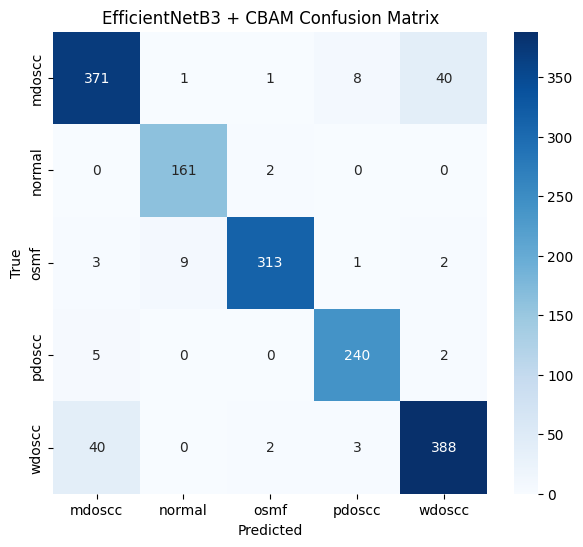


EfficientNetB3 + MC Dropout
Accuracy  : 92.78%
Precision : 0.9289
Recall    : 0.9278
F1 Score  : 0.9280

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.90      0.87      0.89       421
      normal       0.96      0.99      0.98       163
        osmf       0.99      0.97      0.98       328
      pdoscc       0.97      0.93      0.95       247
      wdoscc       0.87      0.92      0.90       433

    accuracy                           0.93      1592
   macro avg       0.94      0.94      0.94      1592
weighted avg       0.93      0.93      0.93      1592



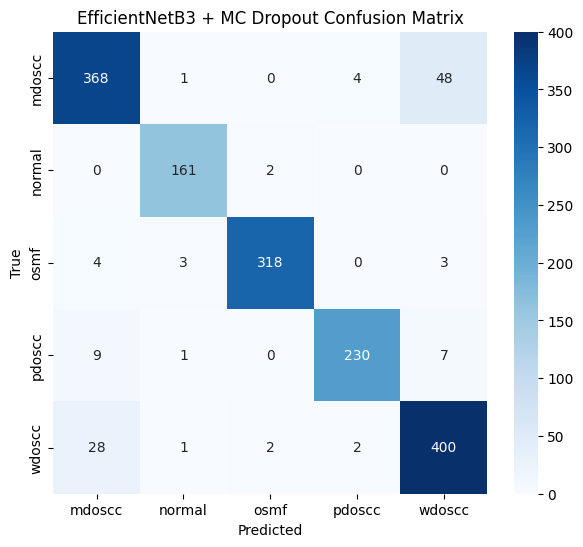


Final Proposed Model
Accuracy  : 93.40%
Precision : 0.9345
Recall    : 0.9340
F1 Score  : 0.9339

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.88      0.91      0.90       421
      normal       0.97      0.98      0.97       163
        osmf       0.97      0.99      0.98       328
      pdoscc       0.94      0.96      0.95       247
      wdoscc       0.94      0.88      0.91       433

    accuracy                           0.93      1592
   macro avg       0.94      0.94      0.94      1592
weighted avg       0.93      0.93      0.93      1592



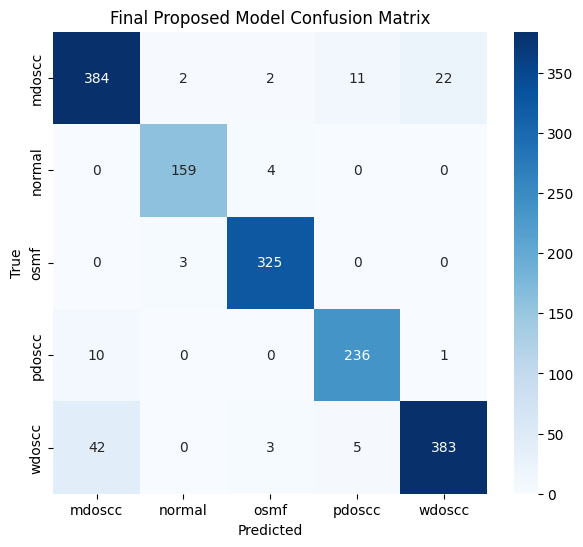


FINAL COMPARISON TABLE

                         Model  Accuracy  Precision  Recall  F1 Score
0        EfficientNetB3 + CBAM     92.53     0.9254  0.9253    0.9252
1  EfficientNetB3 + MC Dropout     92.78     0.9289  0.9278    0.9280
2         Final Proposed Model     93.40     0.9345  0.9340    0.9339


In [ ]:
# =========================================================
# UNIFIED EVALUATION NOTEBOOK
# CBAM + MC DROPOUT + FINAL MODEL
# =========================================================

# !pip install timm

# =========================================================
# IMPORTS
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import torch
import torch.nn as nn

from torch.utils.data import DataLoader

from torchvision import datasets, transforms

import timm

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# =========================================================
# TEST PATH
# =========================================================

test_dir = "/content/drive/MyDrive/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224

BATCH_SIZE = 16

NUM_CLASSES = 5

# =========================================================
# TRANSFORM
# =========================================================

transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASET
# =========================================================

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# CBAM MODULE
# =========================================================

class ChannelAttention(nn.Module):

    def __init__(self, in_channels, reduction=16):

        super(ChannelAttention, self).__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(

            nn.Conv2d(
                in_channels,
                in_channels // reduction,
                1,
                bias=False
            ),

            nn.ReLU(),

            nn.Conv2d(
                in_channels // reduction,
                in_channels,
                1,
                bias=False
            )
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(self.avg_pool(x))

        max_out = self.fc(self.max_pool(x))

        return self.sigmoid(avg_out + max_out)

# =========================================================

class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super(SpatialAttention, self).__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        x = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        x = self.conv(x)

        return self.sigmoid(x)

# =========================================================

class CBAM(nn.Module):

    def __init__(self, in_channels):

        super(CBAM, self).__init__()

        self.channel_attention = ChannelAttention(
            in_channels
        )

        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = x * self.channel_attention(x)

        x = x * self.spatial_attention(x)

        return x

# =========================================================
# CBAM MODEL
# =========================================================

class EfficientNetB3_CBAM(nn.Module):

    def __init__(self, num_classes=5):

        super(EfficientNetB3_CBAM, self).__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.fc(x)

        return x

# =========================================================
# MC DROPOUT MODEL
# =========================================================

class EfficientNetB3_MCDropout(nn.Module):

    def __init__(self, num_classes=5):

        super(EfficientNetB3_MCDropout, self).__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0
        )

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(
            self.backbone.num_features,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.dropout(x)

        x = self.fc(x)

        return x

# =========================================================
# FINAL MODEL
# =========================================================

class ProposedModel(nn.Module):

    def __init__(self, num_classes=5):

        super(ProposedModel, self).__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate_model(model, model_name):

    model.eval()

    all_labels = []

    all_preds = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)

            outputs = model(images)

            _, preds = torch.max(outputs, 1)

            all_labels.extend(labels.numpy())

            all_preds.extend(preds.cpu().numpy())

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average="weighted"
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average="weighted"
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average="weighted"
    )

    print("\n===================================")

    print(model_name)

    print("===================================")

    print(f"Accuracy  : {acc*100:.2f}%")

    print(f"Precision : {precision:.4f}")

    print(f"Recall    : {recall:.4f}")

    print(f"F1 Score  : {f1:.4f}")

    print("\nCLASSIFICATION REPORT\n")

    print(classification_report(
        all_labels,
        all_preds,
        target_names=class_names
    ))

    # =====================================================
    # CONFUSION MATRIX
    # =====================================================

    cm = confusion_matrix(
        all_labels,
        all_preds
    )

    plt.figure(figsize=(7,6))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"{model_name} Confusion Matrix")

    plt.xlabel("Predicted")

    plt.ylabel("True")

    plt.show()

    return [
        model_name,
        round(acc*100,2),
        round(precision,4),
        round(recall,4),
        round(f1,4)
    ]

# =========================================================
# RESULT STORAGE
# =========================================================

results = []

# =========================================================
# CBAM MODEL
# =========================================================

cbam_model = EfficientNetB3_CBAM(
    num_classes=NUM_CLASSES
)

cbam_model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/best_efficientnetb3_cbam.pth",
        map_location=device
    )
)

cbam_model = cbam_model.to(device)

results.append(
    evaluate_model(
        cbam_model,
        "EfficientNetB3 + CBAM"
    )
)

# =========================================================
# MC DROPOUT MODEL
# =========================================================

mc_model = EfficientNetB3_MCDropout(
    num_classes=NUM_CLASSES
)

mc_model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/best_efficientnetb3_mcdropout.pth",
        map_location=device
    )
)

mc_model = mc_model.to(device)

results.append(
    evaluate_model(
        mc_model,
        "EfficientNetB3 + MC Dropout"
    )
)

# =========================================================
# FINAL PROPOSED MODEL
# =========================================================

final_model = ProposedModel(
    num_classes=NUM_CLASSES
)

final_model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/final_proposed_model.pth",
        map_location=device
    )
)

final_model = final_model.to(device)

results.append(
    evaluate_model(
        final_model,
        "Final Proposed Model"
    )
)

# =========================================================
# COMPARISON TABLE
# =========================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\n===================================")

print("FINAL COMPARISON TABLE")

print("===================================\n")

print(results_df)

In [ ]:
print(class_names)

print(test_dataset.class_to_idx)

print(NUM_CLASSES)

['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
{'mdoscc': 0, 'normal': 1, 'osmf': 2, 'pdoscc': 3, 'wdoscc': 4}
5


In [ ]:
import os

for file in os.listdir("/content/drive/MyDrive"):

    if file.endswith(".pth"):

        print(file)

best_efficientnetb3_cbam.pth
best_efficientnetb3_mcdropout.pth
final_proposed_model.pth


In [ ]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
!pip install grad-cam -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 43.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Device: cpu
Model Loaded Successfully!

Using Image: /content/drive/MyDrive/test/test/mdoscc/o-3-00-20/o-3-00-20-075.jpg
mdoscc Mean Activation: 0.3843

Using Image: /content/drive/MyDrive/test/test/normal/o-0-00-04/o-0-00-04-032.jpg
normal Mean Activation: 0.4246

Using Image: /content/drive/MyDrive/test/test/osmf/o-1-00-29/o-1-00-29-075.jpg
osmf Mean Activation: 0.3930

Using Image: /content/drive/MyDrive/test/test/pdoscc/o-4-00-06/o-4-00-06-048.jpg
pdoscc Mean Activation: 0.3203

Using Image: /content/drive/MyDrive/test/test/wdoscc/o-2-00-15/o-2-00-15-046.jpg
wdoscc Mean Activation: 0.3514


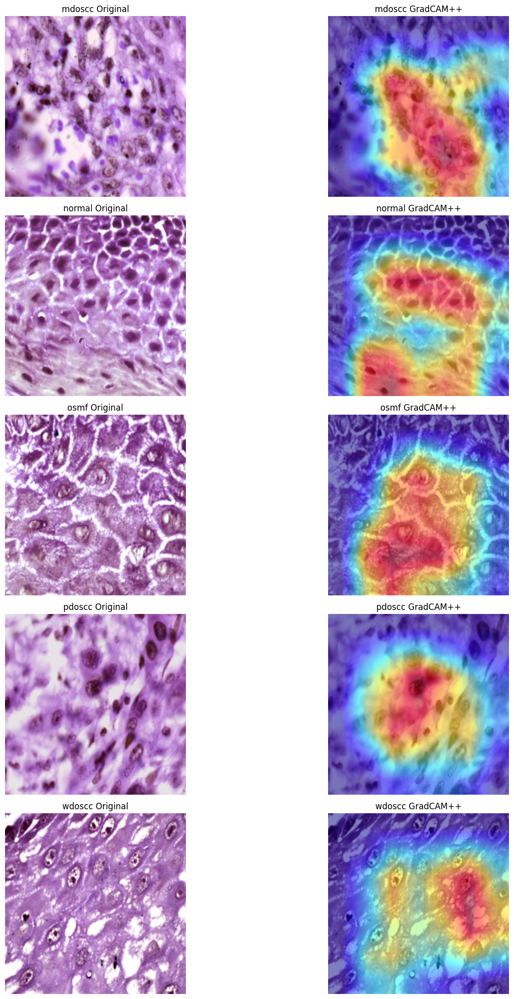


QUANTITATIVE GRADCAM++ ANALYSIS
Mean Activation Score : 0.3747
Activation Std        : 0.0358


In [ ]:
# =========================================================
# FINAL FIXED GRADCAM++ CODE
# SUBFOLDER SUPPORT ADDED
# =========================================================

# !pip install grad-cam timm

# =========================================================
# IMPORTS
# =========================================================

import glob
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torchvision import transforms

import timm

from pytorch_grad_cam import GradCAMPlusPlus

from pytorch_grad_cam.utils.image import show_cam_on_image

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# =========================================================
# TRANSFORM
# =========================================================

transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# CBAM
# =========================================================

class ChannelAttention(nn.Module):

    def __init__(self, in_channels, reduction=16):

        super(ChannelAttention, self).__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(

            nn.Conv2d(
                in_channels,
                in_channels // reduction,
                1,
                bias=False
            ),

            nn.ReLU(),

            nn.Conv2d(
                in_channels // reduction,
                in_channels,
                1,
                bias=False
            )
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(self.avg_pool(x))

        max_out = self.fc(self.max_pool(x))

        return self.sigmoid(avg_out + max_out)

# =========================================================

class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super(SpatialAttention, self).__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        x = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        x = self.conv(x)

        return self.sigmoid(x)

# =========================================================

class CBAM(nn.Module):

    def __init__(self, in_channels):

        super(CBAM, self).__init__()

        self.channel_attention = ChannelAttention(
            in_channels
        )

        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = x * self.channel_attention(x)

        x = x * self.spatial_attention(x)

        return x

# =========================================================
# FINAL MODEL
# =========================================================

class ProposedModel(nn.Module):

    def __init__(self, num_classes=5):

        super(ProposedModel, self).__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

# =========================================================
# LOAD MODEL
# =========================================================

model = ProposedModel(num_classes=5)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/final_proposed_model.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("Model Loaded Successfully!")

# =========================================================
# TARGET LAYER
# =========================================================

target_layer = model.backbone.conv_head

cam = GradCAMPlusPlus(
    model=model,
    target_layers=[target_layer]
)

# =========================================================
# CLASS PATHS
# =========================================================

class_paths = {
    "mdoscc": "/content/drive/MyDrive/test/test/mdoscc",
    "normal": "/content/drive/MyDrive/test/test/normal",
    "osmf": "/content/drive/MyDrive/test/test/osmf",
    "pdoscc": "/content/drive/MyDrive/test/test/pdoscc",
    "wdoscc": "/content/drive/MyDrive/test/test/wdoscc"
}

# =========================================================
# STORAGE
# =========================================================

activation_scores = []

# =========================================================
# FIGURE
# =========================================================

plt.figure(figsize=(16,20))

plot_index = 1

# =========================================================
# LOOP THROUGH CLASSES
# =========================================================

for class_name, class_path in class_paths.items():

    # =====================================================
    # SEARCH RECURSIVELY INSIDE SUBFOLDERS
    # =====================================================

    image_list = (

        glob.glob(
            class_path + "/**/*.jpg",
            recursive=True
        ) +

        glob.glob(
            class_path + "/**/*.jpeg",
            recursive=True
        ) +

        glob.glob(
            class_path + "/**/*.png",
            recursive=True
        )
    )

    # =====================================================
    # CHECK IMAGES
    # =====================================================

    if len(image_list) == 0:

        print(f"No image found in {class_name}")

        continue

    # =====================================================
    # TAKE FIRST IMAGE
    # =====================================================

    image_path = image_list[0]

    print(f"\nUsing Image: {image_path}")

    # =====================================================
    # LOAD IMAGE
    # =====================================================

    img = Image.open(image_path).convert("RGB")

    img = img.resize((224,224))

    img_np = np.array(img) / 255.0

    # =====================================================
    # PREPROCESS
    # =====================================================

    input_tensor = transform(img).unsqueeze(0).to(device)

    # =====================================================
    # GENERATE GRADCAM++
    # =====================================================

    grayscale_cam = cam(
        input_tensor=input_tensor
    )[0]

    # =====================================================
    # VISUALIZATION
    # =====================================================

    visualization = show_cam_on_image(
        img_np,
        grayscale_cam,
        use_rgb=True
    )

    # =====================================================
    # QUANTITATIVE XAI
    # =====================================================

    mean_activation = np.mean(grayscale_cam)

    activation_scores.append(mean_activation)

    print(f"{class_name} Mean Activation: {mean_activation:.4f}")

    # =====================================================
    # ORIGINAL IMAGE
    # =====================================================

    plt.subplot(5,2,plot_index)

    plt.imshow(img_np)

    plt.title(f"{class_name} Original")

    plt.axis("off")

    plot_index += 1

    # =====================================================
    # GRADCAM++
    # =====================================================

    plt.subplot(5,2,plot_index)

    plt.imshow(visualization)

    plt.title(f"{class_name} GradCAM++")

    plt.axis("off")

    plot_index += 1

# =========================================================
# SHOW RESULTS
# =========================================================

plt.tight_layout()

plt.show()

# =========================================================
# QUANTITATIVE XAI SUMMARY
# =========================================================

mean_xai_score = np.mean(activation_scores)

std_xai_score = np.std(activation_scores)

print("\n===================================")

print("QUANTITATIVE GRADCAM++ ANALYSIS")

print("===================================")

print(f"Mean Activation Score : {mean_xai_score:.4f}")

print(f"Activation Std        : {std_xai_score:.4f}")

Device: cpu
Model Loaded Successfully!

Using Image: /content/drive/MyDrive/test/test/mdoscc/o-3-00-20/o-3-00-20-075.jpg
mdoscc Min = 0.0 Max = 0.9999999 Mean = 0.38433686
mdoscc Mean Activation: 0.3843

Using Image: /content/drive/MyDrive/test/test/normal/o-0-00-04/o-0-00-04-032.jpg
normal Min = 0.0 Max = 0.9999999 Mean = 0.4245637
normal Mean Activation: 0.4246

Using Image: /content/drive/MyDrive/test/test/osmf/o-1-00-29/o-1-00-29-075.jpg
osmf Min = 0.0 Max = 0.9999999 Mean = 0.39303872
osmf Mean Activation: 0.3930

Using Image: /content/drive/MyDrive/test/test/pdoscc/o-4-00-06/o-4-00-06-048.jpg
pdoscc Min = 0.0 Max = 0.9999999 Mean = 0.3202723
pdoscc Mean Activation: 0.3203

Using Image: /content/drive/MyDrive/test/test/wdoscc/o-2-00-15/o-2-00-15-046.jpg
wdoscc Min = 0.0 Max = 0.9999999 Mean = 0.35144502
wdoscc Mean Activation: 0.3514


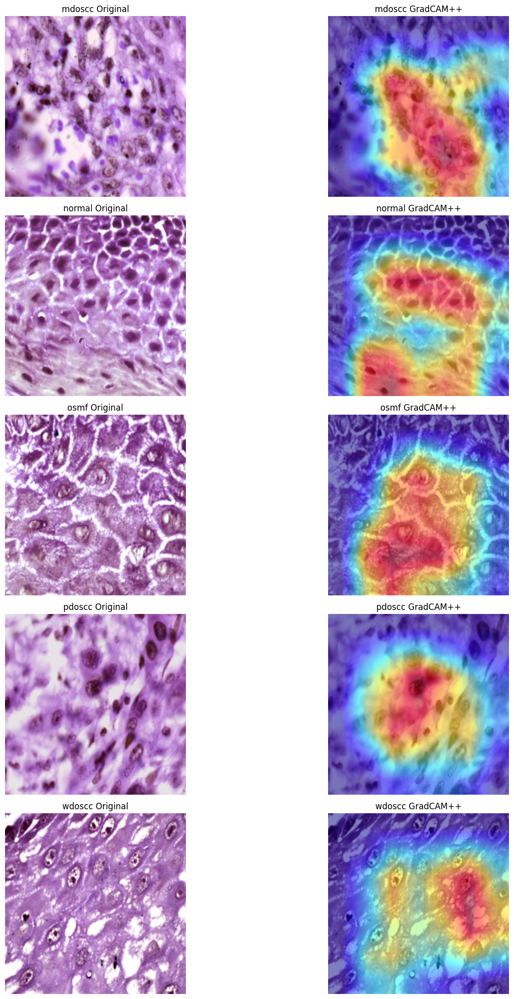


Dictionary Contents:
{'mdoscc': np.float32(0.38433686), 'normal': np.float32(0.4245637), 'osmf': np.float32(0.39303872), 'pdoscc': np.float32(0.3202723), 'wdoscc': np.float32(0.35144502)}

PER-CLASS GRADCAM++ ANALYSIS

mdoscc     : 0.3843
normal     : 0.4246
osmf       : 0.3930
pdoscc     : 0.3203
wdoscc     : 0.3514

-----------------------------------

Overall Mean Activation : 0.3747
Activation Std          : 0.0358


In [ ]:
# =========================================================
# FINAL FIXED GRADCAM++ CODE
# SUBFOLDER SUPPORT ADDED
# =========================================================

# !pip install grad-cam timm

# =========================================================
# IMPORTS
# =========================================================

import glob
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torchvision import transforms

import timm

from pytorch_grad_cam import GradCAMPlusPlus

from pytorch_grad_cam.utils.image import show_cam_on_image

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# =========================================================
# TRANSFORM
# =========================================================

transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# CBAM
# =========================================================

class ChannelAttention(nn.Module):

    def __init__(self, in_channels, reduction=16):

        super(ChannelAttention, self).__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(

            nn.Conv2d(
                in_channels,
                in_channels // reduction,
                1,
                bias=False
            ),

            nn.ReLU(),

            nn.Conv2d(
                in_channels // reduction,
                in_channels,
                1,
                bias=False
            )
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(self.avg_pool(x))

        max_out = self.fc(self.max_pool(x))

        return self.sigmoid(avg_out + max_out)

# =========================================================

class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super(SpatialAttention, self).__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        x = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        x = self.conv(x)

        return self.sigmoid(x)

# =========================================================

class CBAM(nn.Module):

    def __init__(self, in_channels):

        super(CBAM, self).__init__()

        self.channel_attention = ChannelAttention(
            in_channels
        )

        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = x * self.channel_attention(x)

        x = x * self.spatial_attention(x)

        return x

# =========================================================
# FINAL MODEL
# =========================================================

class ProposedModel(nn.Module):

    def __init__(self, num_classes=5):

        super(ProposedModel, self).__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

# =========================================================
# LOAD MODEL
# =========================================================

model = ProposedModel(num_classes=5)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/final_proposed_model.pth",
        map_location=device
    )
)

model = model.to(device)

model.eval()

print("Model Loaded Successfully!")

# =========================================================
# TARGET LAYER
# =========================================================

target_layer = model.backbone.conv_head

cam = GradCAMPlusPlus(
    model=model,
    target_layers=[target_layer]
)

# =========================================================
# CLASS PATHS
# =========================================================

class_paths = {
    "mdoscc": "/content/drive/MyDrive/test/test/mdoscc",
    "normal": "/content/drive/MyDrive/test/test/normal",
    "osmf": "/content/drive/MyDrive/test/test/osmf",
    "pdoscc": "/content/drive/MyDrive/test/test/pdoscc",
    "wdoscc": "/content/drive/MyDrive/test/test/wdoscc"
}

# =========================================================
# STORAGE
# =========================================================

# =========================================================
# STORAGE
# =========================================================

activation_scores = []

class_activation_scores = {}

# =========================================================
# FIGURE
# =========================================================

plt.figure(figsize=(16,20))

plot_index = 1

# =========================================================
# LOOP THROUGH CLASSES
# =========================================================

for class_name, class_path in class_paths.items():

    # =====================================================
    # SEARCH RECURSIVELY INSIDE SUBFOLDERS
    # =====================================================

    image_list = (

        glob.glob(
            class_path + "/**/*.jpg",
            recursive=True
        ) +

        glob.glob(
            class_path + "/**/*.jpeg",
            recursive=True
        ) +

        glob.glob(
            class_path + "/**/*.png",
            recursive=True
        )
    )

    # =====================================================
    # CHECK IMAGES
    # =====================================================

    if len(image_list) == 0:

        print(f"No image found in {class_name}")

        continue

    # =====================================================
    # TAKE FIRST IMAGE
    # =====================================================

    image_path = image_list[0]

    print(f"\nUsing Image: {image_path}")

    # =====================================================
    # LOAD IMAGE
    # =====================================================

    img = Image.open(image_path).convert("RGB")

    img = img.resize((224,224))

    img_np = np.array(img) / 255.0

    # =====================================================
    # PREPROCESS
    # =====================================================

    input_tensor = transform(img).unsqueeze(0).to(device)

    # =====================================================
    # GENERATE GRADCAM++
    # =====================================================

        # =====================================================
    # GENERATE GRADCAM++
    # =====================================================

    grayscale_cam = cam(
        input_tensor=input_tensor
    )[0]

    print(
        class_name,
        "Min =", np.min(grayscale_cam),
        "Max =", np.max(grayscale_cam),
        "Mean =", np.mean(grayscale_cam)
    )

    # =====================================================
    # VISUALIZATION
    # =====================================================

    visualization = show_cam_on_image(
        img_np,
        grayscale_cam,
        use_rgb=True
    )

    # =====================================================
    # QUANTITATIVE XAI
    # =====================================================

    mean_activation = np.mean(grayscale_cam)

    activation_scores.append(mean_activation)

    class_activation_scores[class_name] = mean_activation

    print(
        f"{class_name} Mean Activation: "
        f"{mean_activation:.4f}"
    )

    # =====================================================
    # ORIGINAL IMAGE
    # =====================================================

    plt.subplot(5,2,plot_index)

    plt.imshow(img_np)

    plt.title(f"{class_name} Original")

    plt.axis("off")

    plot_index += 1

    # =====================================================
    # GRADCAM++
    # =====================================================

    plt.subplot(5,2,plot_index)

    plt.imshow(visualization)

    plt.title(f"{class_name} GradCAM++")

    plt.axis("off")

    plot_index += 1
    # =====================================================


# =========================================================
# SHOW RESULTS
# =========================================================

plt.tight_layout()

plt.show()
print("\nDictionary Contents:")

print(class_activation_scores)
# =========================================================
# OVERALL STATISTICS
# =========================================================

mean_xai_score = np.mean(
    activation_scores
)

std_xai_score = np.std(
    activation_scores
)
# =========================================================
# QUANTITATIVE XAI SUMMARY
# =========================================================

print("\n===================================")
print("PER-CLASS GRADCAM++ ANALYSIS")
print("===================================\n")

for cls, score in class_activation_scores.items():

    print(
        f"{cls:<10} : {score:.4f}"
    )

print("\n-----------------------------------\n")

print(
    f"Overall Mean Activation : "
    f"{mean_xai_score:.4f}"
)

print(
    f"Activation Std          : "
    f"{std_xai_score:.4f}"
)

In [ ]:
print(np.mean(all_correct) * 100)

20.85427135678392


In [ ]:
print(class_activation_scores)

{'wdoscc': np.float32(0.35144502)}



CALIBRATION ANALYSIS

Expected Calibration Error (ECE): 0.0302


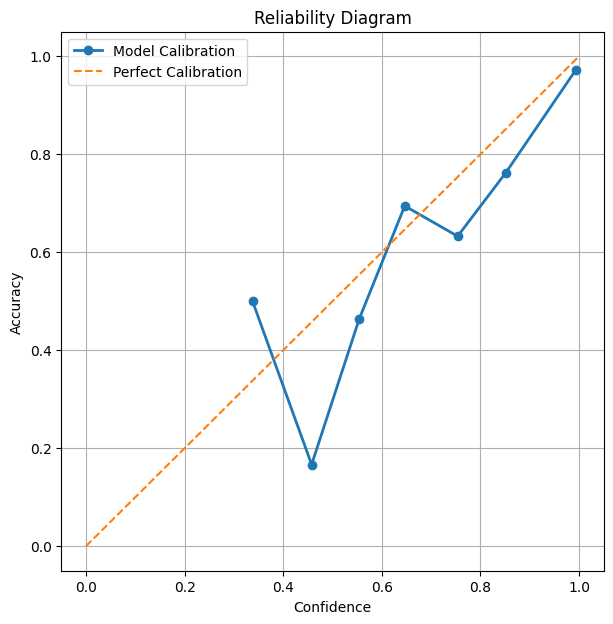

In [ ]:
# =========================================================
# CALIBRATION ANALYSIS
# ECE + RELIABILITY DIAGRAM
# =========================================================

# RUN AFTER:
# model loaded
# test_loader created

# =========================================================
# IMPORTS
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve

# =========================================================
# MODEL EVALUATION
# =========================================================

model.eval()

all_probs = []

all_preds = []

all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )

        confidences, preds = torch.max(
            probs,
            dim=1
        )

        all_probs.extend(
            confidences.cpu().numpy()
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

# =========================================================
# NUMPY
# =========================================================

all_probs = np.array(all_probs)

all_preds = np.array(all_preds)

all_labels = np.array(all_labels)

# =========================================================
# CORRECTNESS
# =========================================================

correct = (
    all_preds == all_labels
).astype(int)

# =========================================================
# EXPECTED CALIBRATION ERROR (ECE)
# =========================================================

n_bins = 10

bin_boundaries = np.linspace(
    0,
    1,
    n_bins + 1
)

ece = 0.0

for i in range(n_bins):

    bin_lower = bin_boundaries[i]

    bin_upper = bin_boundaries[i + 1]

    in_bin = (
        (all_probs > bin_lower) &
        (all_probs <= bin_upper)
    )

    prop_in_bin = np.mean(in_bin)

    if prop_in_bin > 0:

        accuracy_in_bin = np.mean(
            correct[in_bin]
        )

        avg_confidence_in_bin = np.mean(
            all_probs[in_bin]
        )

        ece += np.abs(
            avg_confidence_in_bin -
            accuracy_in_bin
        ) * prop_in_bin

# =========================================================
# PRINT ECE
# =========================================================

print("\n===================================")

print("CALIBRATION ANALYSIS")

print("===================================\n")

print(f"Expected Calibration Error (ECE): {ece:.4f}")

# =========================================================
# RELIABILITY DIAGRAM
# =========================================================

prob_true, prob_pred = calibration_curve(

    correct,
    all_probs,
    n_bins=n_bins
)

plt.figure(figsize=(7,7))

plt.plot(
    prob_pred,
    prob_true,
    marker='o',
    linewidth=2,
    label='Model Calibration'
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--',
    label='Perfect Calibration'
)

plt.xlabel("Confidence")

plt.ylabel("Accuracy")

plt.title("Reliability Diagram")

plt.legend()

plt.grid()

plt.show()


Using: /content/drive/MyDrive/test/test/mdoscc/o-3-00-20/o-3-00-20-075.jpg
mdoscc Uncertainty: 0.0000
mdoscc Overlap Score: 0.0000

Using: /content/drive/MyDrive/test/test/normal/o-0-00-04/o-0-00-04-032.jpg
normal Uncertainty: 0.0001
normal Overlap Score: 1.0000

Using: /content/drive/MyDrive/test/test/osmf/o-1-00-29/o-1-00-29-075.jpg
osmf Uncertainty: 0.0000
osmf Overlap Score: 0.0000

Using: /content/drive/MyDrive/test/test/pdoscc/o-4-00-06/o-4-00-06-048.jpg
pdoscc Uncertainty: 0.2585
pdoscc Overlap Score: 1.0000

Using: /content/drive/MyDrive/test/test/wdoscc/o-2-00-15/o-2-00-15-046.jpg
wdoscc Uncertainty: 0.0002
wdoscc Overlap Score: 0.0000


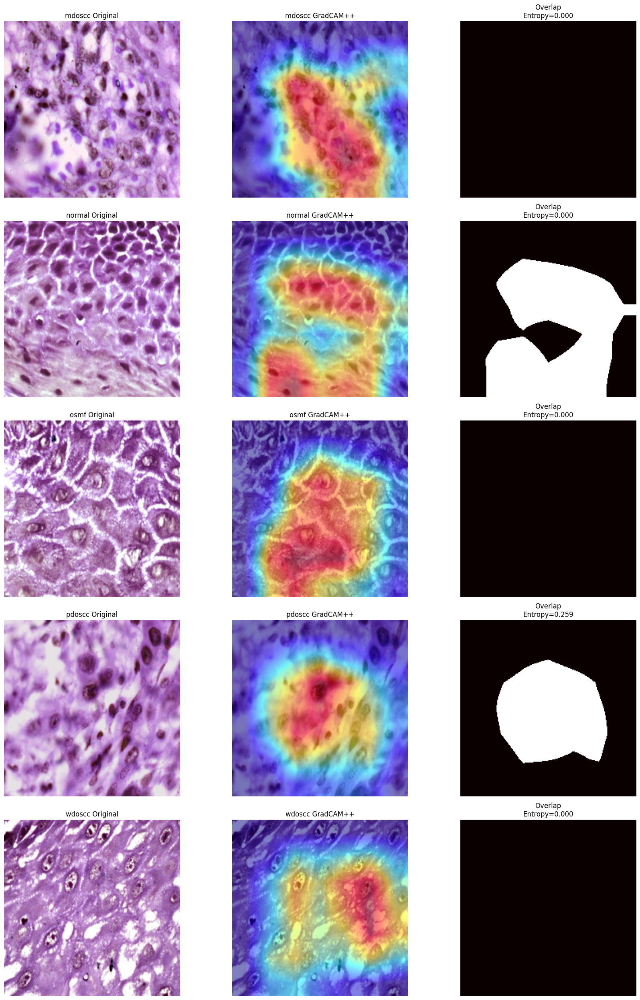


EXPLAINABILITY-GUIDED UNCERTAINTY

Mean Overlap Score : 0.4000
Overlap Std        : 0.4899


In [ ]:
# =========================================================
# EXPLAINABILITY-GUIDED UNCERTAINTY ANALYSIS
# GradCAM++ + MC Dropout Overlap
# =========================================================

# RUN AFTER:
# model loaded
# transform created

# =========================================================
# IMPORTS
# =========================================================

import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch

from pytorch_grad_cam import GradCAMPlusPlus

from pytorch_grad_cam.utils.image import show_cam_on_image

# =========================================================
# ENABLE MC DROPOUT DURING INFERENCE
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if module.__class__.__name__.startswith("Dropout"):

            module.train()

# =========================================================
# MC DROPOUT UNCERTAINTY
# =========================================================

def compute_uncertainty(
    model,
    input_tensor,
    mc_samples=20
):

    enable_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(input_tensor)

            probs = torch.softmax(
                outputs,
                dim=1
            )

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    mean_probs = np.mean(
        predictions,
        axis=0
    )

    entropy = -np.sum(
        mean_probs * np.log(mean_probs + 1e-10),
        axis=1
    )

    return entropy[0]

# =========================================================
# GRADCAM++
# =========================================================

target_layer = model.backbone.conv_head

cam = GradCAMPlusPlus(
    model=model,
    target_layers=[target_layer]
)

# =========================================================
# CLASS PATHS
# =========================================================

class_paths = {
    "mdoscc": "/content/drive/MyDrive/test/test/mdoscc",
    "normal": "/content/drive/MyDrive/test/test/normal",
    "osmf": "/content/drive/MyDrive/test/test/osmf",
    "pdoscc": "/content/drive/MyDrive/test/test/pdoscc",
    "wdoscc": "/content/drive/MyDrive/test/test/wdoscc"
}

# =========================================================
# FIGURE
# =========================================================

plt.figure(figsize=(18,25))

plot_index = 1

# =========================================================
# STORE OVERLAP SCORES
# =========================================================

overlap_scores = []

# =========================================================
# LOOP
# =========================================================

for class_name, class_path in class_paths.items():

    # =====================================================
    # FIND IMAGES
    # =====================================================

    image_list = (

        glob.glob(
            class_path + "/**/*.jpg",
            recursive=True
        ) +

        glob.glob(
            class_path + "/**/*.jpeg",
            recursive=True
        ) +

        glob.glob(
            class_path + "/**/*.png",
            recursive=True
        )
    )

    if len(image_list) == 0:

        print(f"No image found in {class_name}")

        continue

    # =====================================================
    # TAKE IMAGE
    # =====================================================

    image_path = image_list[0]

    print(f"\nUsing: {image_path}")

    # =====================================================
    # LOAD IMAGE
    # =====================================================

    img = Image.open(image_path).convert("RGB")

    img = img.resize((224,224))

    img_np = np.array(img) / 255.0

    input_tensor = transform(img).unsqueeze(0).to(device)

    # =====================================================
    # COMPUTE UNCERTAINTY
    # =====================================================

    entropy = compute_uncertainty(
        model,
        input_tensor
    )

    print(f"{class_name} Uncertainty: {entropy:.4f}")

    # =====================================================
    # GENERATE GRADCAM++
    # =====================================================

    grayscale_cam = cam(
        input_tensor=input_tensor
    )[0]

    # =====================================================
    # THRESHOLD ATTENTION REGION
    # =====================================================

    attention_mask = (
        grayscale_cam > 0.5
    ).astype(np.uint8)

    # =====================================================
    # CREATE UNCERTAINTY MAP
    # =====================================================

    uncertainty_map = np.ones_like(
        grayscale_cam
    ) * entropy

    uncertainty_mask = (
        uncertainty_map > np.mean(uncertainty_map)
    ).astype(np.uint8)

    # =====================================================
    # OVERLAP
    # =====================================================

    overlap = attention_mask * uncertainty_mask

    overlap_score = np.sum(overlap) / (
        np.sum(attention_mask) + 1e-10
    )

    overlap_scores.append(overlap_score)

    print(f"{class_name} Overlap Score: {overlap_score:.4f}")

    # =====================================================
    # VISUALIZATION
    # =====================================================

    visualization = show_cam_on_image(
        img_np,
        grayscale_cam,
        use_rgb=True
    )

    # =====================================================
    # ORIGINAL
    # =====================================================

    plt.subplot(5,3,plot_index)

    plt.imshow(img_np)

    plt.title(f"{class_name} Original")

    plt.axis("off")

    plot_index += 1

    # =====================================================
    # GRADCAM++
    # =====================================================

    plt.subplot(5,3,plot_index)

    plt.imshow(visualization)

    plt.title(f"{class_name} GradCAM++")

    plt.axis("off")

    plot_index += 1

    # =====================================================
    # OVERLAP MAP
    # =====================================================

    plt.subplot(5,3,plot_index)

    plt.imshow(overlap, cmap='hot')

    plt.title(
        f"Overlap\nEntropy={entropy:.3f}"
    )

    plt.axis("off")

    plot_index += 1

# =========================================================
# SHOW
# =========================================================

plt.tight_layout()

plt.show()

# =========================================================
# FINAL ANALYSIS
# =========================================================

mean_overlap = np.mean(overlap_scores)

std_overlap = np.std(overlap_scores)

print("\n===================================")

print("EXPLAINABILITY-GUIDED UNCERTAINTY")

print("===================================\n")

print(f"Mean Overlap Score : {mean_overlap:.4f}")

print(f"Overlap Std        : {std_overlap:.4f}")

In [ ]:
# =========================================================
# RECREATE FINAL TRUSTED / REFERRED MASKS
# VALIDATION-ONLY THRESHOLDS
# =========================================================

import numpy as np

# ---------------------------------------------------------
# Convert only required arrays
# ---------------------------------------------------------

all_confidences = np.array(all_confidences)
all_uncertainties = np.array(all_uncertainties)

# ---------------------------------------------------------
# Load validation-derived thresholds
# ---------------------------------------------------------

CONF_THRESHOLD = np.load(
    "/content/drive/MyDrive/confidence_threshold.npy"
).item()

UNC_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

print("======================================")
print("RECREATING FINAL TRUST MASKS")
print("======================================")

print(
    f"Confidence Threshold  : {CONF_THRESHOLD:.8f}"
)

print(
    f"Uncertainty Threshold : {UNC_THRESHOLD:.8f}"
)

# ---------------------------------------------------------
# Confidence condition
# ---------------------------------------------------------

conf_trusted_idx = (
    all_confidences >= CONF_THRESHOLD
)

# ---------------------------------------------------------
# Uncertainty condition
# ---------------------------------------------------------

unc_trusted_idx = (
    all_uncertainties <= UNC_THRESHOLD
)

# ---------------------------------------------------------
# Two-factor consensus
# BOTH must be trusted
# ---------------------------------------------------------

trust_votes_2 = (
    conf_trusted_idx.astype(int)
    +
    unc_trusted_idx.astype(int)
)

final_trusted_2 = (
    trust_votes_2 == 2
)

final_referred_2 = (
    trust_votes_2 <= 1
)

# ---------------------------------------------------------
# Results
# ---------------------------------------------------------

print("\n======================================")
print("FINAL TRUST MASKS READY")
print("======================================")

print(
    f"Total Test Samples : {len(all_confidences)}"
)

print(
    f"Trusted Samples    : {final_trusted_2.sum()}"
)

print(
    f"Referred Samples   : {final_referred_2.sum()}"
)

print(
    f"Coverage           : "
    f"{final_trusted_2.mean()*100:.2f}%"
)

RECREATING FINAL TRUST MASKS
Confidence Threshold  : 0.80000000
Uncertainty Threshold : 0.00012634

FINAL TRUST MASKS READY
Total Test Samples : 1592
Trusted Samples    : 1225
Referred Samples   : 367
Coverage           : 76.95%


In [ ]:
# =========================================================
# INSTALL GRAD-CAM++
# =========================================================

!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 53.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# =========================================================
# IMPORT + INITIALIZE GRAD-CAM++
# =========================================================

from pytorch_grad_cam import GradCAMPlusPlus

# Original notebook target layer
target_layer = model.backbone.conv_head

cam = GradCAMPlusPlus(
    model=model,
    target_layers=[target_layer]
)

print("======================================")
print("Grad-CAM++ INITIALIZED SUCCESSFULLY")
print("======================================")
print("Target Layer :", target_layer)

NameError: name 'model' is not defined

In [ ]:
# =========================================================
# INITIALIZE GRAD-CAM++
# =========================================================

from pytorch_grad_cam import GradCAMPlusPlus

# ---------------------------------------------------------
# Target layer from the original notebook
# ---------------------------------------------------------

target_layer = model.backbone.conv_head

# ---------------------------------------------------------
# Create Grad-CAM++ object
# ---------------------------------------------------------

cam = GradCAMPlusPlus(
    model=model,
    target_layers=[target_layer]
)

print("======================================")
print("Grad-CAM++ INITIALIZED SUCCESSFULLY")
print("======================================")
print("Target Layer :", target_layer)

ModuleNotFoundError: No module named 'pytorch_grad_cam'

In [ ]:
# =========================================================
# GRAD-CAM++ ACTIVATION ANALYSIS
# TRUSTED vs REFERRED
# =========================================================

import numpy as np
import torch
from tqdm.auto import tqdm

# ---------------------------------------------------------
# Storage
# ---------------------------------------------------------

all_activation_scores = []

model.eval()

print("======================================")
print("GRAD-CAM++ ACTIVATION ANALYSIS")
print("======================================")
print("Trusted Samples  :", final_trusted_2.sum())
print("Referred Samples :", final_referred_2.sum())
print()

# ---------------------------------------------------------
# Grad-CAM++ for every test image
# ---------------------------------------------------------

for images, labels in tqdm(
    test_loader,
    desc="Processing Test Images"
):

    images = images.to(device)

    for i in range(images.size(0)):

        input_tensor = images[i].unsqueeze(0)

        # Grad-CAM++
        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=None
        )[0]

        # Mean activation
        activation_score = np.mean(
            grayscale_cam
        )

        all_activation_scores.append(
            activation_score
        )

# ---------------------------------------------------------
# Convert to NumPy
# ---------------------------------------------------------

all_activation_scores = np.array(
    all_activation_scores
)

# ---------------------------------------------------------
# Check
# ---------------------------------------------------------

print("\n======================================")
print("GRAD-CAM++ COMPLETED")
print("======================================")

print(
    "Activation Scores :",
    len(all_activation_scores)
)

print(
    "Expected Samples  :",
    len(final_trusted_2)
)

GRAD-CAM++ ACTIVATION ANALYSIS
Trusted Samples  : 1225
Referred Samples : 367



Processing Test Images:   0%|          | 0/100 [00:00<?, ?it/s]

NameError: name 'cam' is not defined


Running Trust-Aware Analysis...

Processing Batch 1
Processing Batch 2
Processing Batch 3
Processing Batch 4
Processing Batch 5
Processing Batch 6
Processing Batch 7
Processing Batch 8
Processing Batch 9
Processing Batch 10

TRUST-AWARE HISTOPATHOLOGY AI

Mean Confidence  : 0.9130
Mean Uncertainty : 0.2035
Mean Trust Score : 0.8243
Trust Std        : 0.2564

-----------------------------------

Trusted Samples   : 113
Untrusted Samples : 47


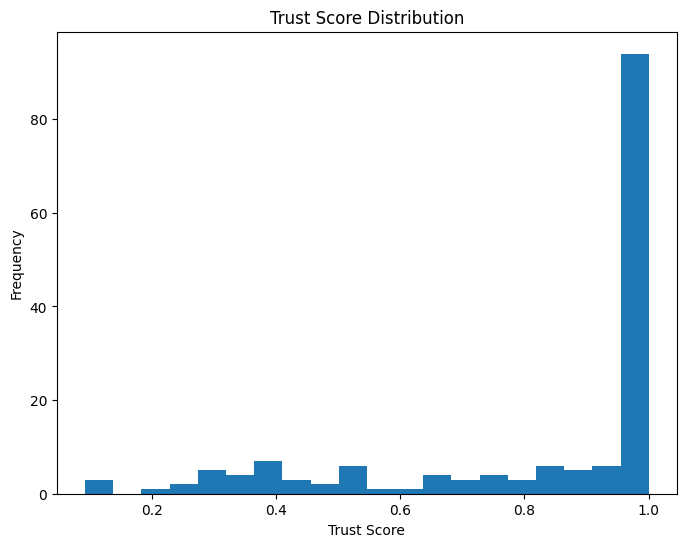

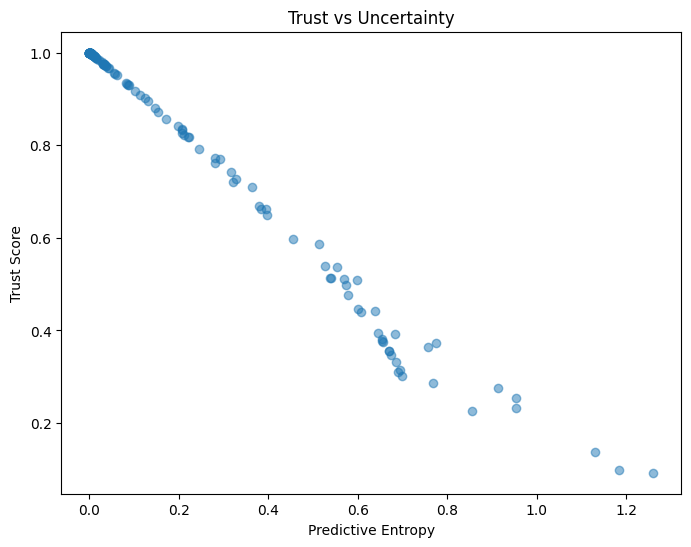

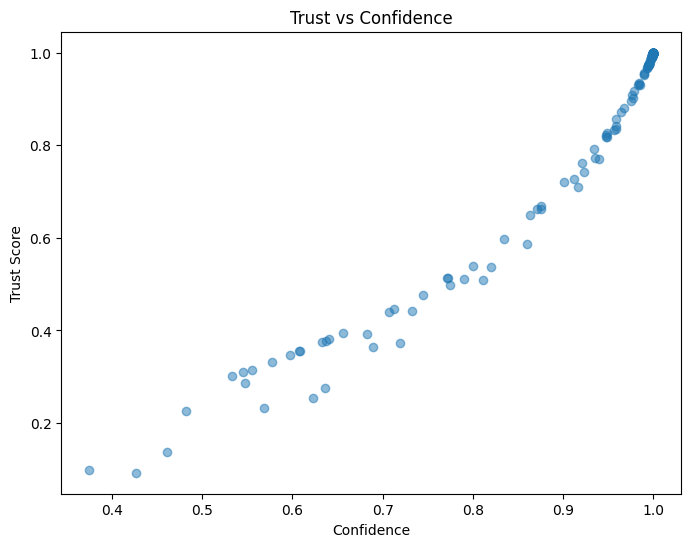


-----------------------------------

Trusted Sample Accuracy : 97.35%
Untrusted Sample Accuracy : 57.45%


In [ ]:
# =========================================================
# FAST TRUST-AWARE HISTOPATHOLOGY AI
# CPU FRIENDLY VERSION
# =========================================================

# RUN AFTER:
# model loaded
# test_loader created

# =========================================================
# IMPORTS
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

import torch

# =========================================================
# ENABLE MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if module.__class__.__name__.startswith("Dropout"):

            module.train()

# =========================================================
# TRUST-AWARE INFERENCE
# =========================================================

def trust_aware_prediction(
    model,
    images,
    mc_samples=5
):

    enable_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    # =====================================================
    # MEAN PROBABILITIES
    # =====================================================

    mean_probs = np.mean(
        predictions,
        axis=0
    )

    # =====================================================
    # CONFIDENCE
    # =====================================================

    confidence = np.max(
        mean_probs,
        axis=1
    )

    # =====================================================
    # PREDICTIONS
    # =====================================================

    preds = np.argmax(
        mean_probs,
        axis=1
    )

    # =====================================================
    # ENTROPY
    # =====================================================

    entropy = -np.sum(

        mean_probs *
        np.log(mean_probs + 1e-10),

        axis=1
    )

    # =====================================================
    # TRUST SCORE
    # =====================================================

    trust_score = confidence * (
        1 - entropy / np.log(NUM_CLASSES)
    )

    return (
        preds,
        confidence,
        entropy,
        trust_score
    )

# =========================================================
# STORAGE
# =========================================================

all_confidence = []

all_entropy = []

all_trust = []

all_correct = []

# =========================================================
# EVALUATION
# =========================================================

model.eval()

print("\nRunning Trust-Aware Analysis...\n")

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(test_loader):

        # ================================================
        # ONLY FIRST 10 BATCHES
        # ================================================

        if batch_idx == 10:
            break

        print(f"Processing Batch {batch_idx+1}")

        images = images.to(device)

        labels = labels.to(device)

        (
            preds,
            confidence,
            entropy,
            trust_score

        ) = trust_aware_prediction(
            model,
            images,
            mc_samples=5
        )

        preds = np.array(preds)

        labels_np = labels.cpu().numpy()

        correct = (
            preds == labels_np
        ).astype(int)

        all_confidence.extend(confidence)

        all_entropy.extend(entropy)

        all_trust.extend(trust_score)

        all_correct.extend(correct)

# =========================================================
# NUMPY
# =========================================================

all_confidence = np.array(all_confidence)

all_entropy = np.array(all_entropy)

all_trust = np.array(all_trust)

all_correct = np.array(all_correct)

# =========================================================
# METRICS
# =========================================================

mean_trust = np.mean(all_trust)

std_trust = np.std(all_trust)

mean_conf = np.mean(all_confidence)

mean_entropy = np.mean(all_entropy)

# =========================================================
# TRUSTED / UNTRUSTED
# =========================================================

trust_threshold = 0.8

trusted_samples = np.sum(
    all_trust >= trust_threshold
)

untrusted_samples = np.sum(
    all_trust < trust_threshold
)

# =========================================================
# RESULTS
# =========================================================

print("\n===================================")

print("TRUST-AWARE HISTOPATHOLOGY AI")

print("===================================\n")

print(f"Mean Confidence  : {mean_conf:.4f}")

print(f"Mean Uncertainty : {mean_entropy:.4f}")

print(f"Mean Trust Score : {mean_trust:.4f}")

print(f"Trust Std        : {std_trust:.4f}")

print("\n-----------------------------------\n")

print(f"Trusted Samples   : {trusted_samples}")

print(f"Untrusted Samples : {untrusted_samples}")

# =========================================================
# TRUST DISTRIBUTION
# =========================================================

plt.figure(figsize=(8,6))

plt.hist(
    all_trust,
    bins=20
)

plt.xlabel("Trust Score")

plt.ylabel("Frequency")

plt.title("Trust Score Distribution")

plt.show()

# =========================================================
# TRUST VS UNCERTAINTY
# =========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    all_entropy,
    all_trust,
    alpha=0.5
)

plt.xlabel("Predictive Entropy")

plt.ylabel("Trust Score")

plt.title("Trust vs Uncertainty")

plt.show()

# =========================================================
# TRUST VS CONFIDENCE
# =========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    all_confidence,
    all_trust,
    alpha=0.5
)

plt.xlabel("Confidence")

plt.ylabel("Trust Score")

plt.title("Trust vs Confidence")

plt.show()

# =========================================================
# TRUSTED ACCURACY
# =========================================================

trusted_mask = (
    all_trust >= trust_threshold
)

if np.sum(trusted_mask) > 0:

    trusted_accuracy = np.mean(
        all_correct[trusted_mask]
    )

    print("\n-----------------------------------\n")

    print(
        f"Trusted Sample Accuracy : "
        f"{trusted_accuracy*100:.2f}%"
    )

# =========================================================
# UNTRUSTED ACCURACY
# =========================================================

untrusted_mask = (
    all_trust < trust_threshold
)

if np.sum(untrusted_mask) > 0:

    untrusted_accuracy = np.mean(
        all_correct[untrusted_mask]
    )

    print(
        f"Untrusted Sample Accuracy : "
        f"{untrusted_accuracy*100:.2f}%"
    )

In [ ]:
# =========================================================
# TRUST-AWARE ANALYSIS
# PART 1
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch

# =========================================================
# LOAD FIXED VALIDATION THRESHOLDS
# =========================================================

CONFIDENCE_THRESHOLD = np.load(
    "/content/drive/MyDrive/confidence_threshold.npy"
).item()

UNCERTAINTY_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

print("======================================")
print("VALIDATION THRESHOLDS LOADED")
print("======================================")

print(f"Confidence Threshold : {CONFIDENCE_THRESHOLD:.2f}")
print(f"Uncertainty Threshold: {UNCERTAINTY_THRESHOLD:.6f}")

# =========================================================
# ENABLE MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if isinstance(module, torch.nn.Dropout):

            module.train()

# =========================================================
# TRUST-AWARE PREDICTION
# =========================================================

def trust_aware_prediction(
    model,
    images,
    mc_samples=2
):

    enable_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    mean_probs = np.mean(
        predictions,
        axis=0
    )

    confidence = np.max(
        mean_probs,
        axis=1
    )

    preds = np.argmax(
        mean_probs,
        axis=1
    )

    entropy = -np.sum(

        mean_probs *

        np.log(mean_probs + 1e-10),

        axis=1

    )

    trust_score = confidence * (
        1 - entropy / np.log(NUM_CLASSES)
    )

    return (
        preds,
        confidence,
        entropy,
        trust_score
    )

VALIDATION THRESHOLDS LOADED
Confidence Threshold : 0.80
Uncertainty Threshold: 0.631966


In [ ]:
# =========================================================
# PART 2
# FULL TEST EVALUATION
# =========================================================

all_confidence = []
all_entropy = []
all_trust = []
all_correct = []

model.eval()

print("\nRunning Trust-Aware Analysis...\n")

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(test_loader):

        print(f"Processing Batch {batch_idx+1}/{len(test_loader)}", end="\r")

        images = images.to(device)
        labels = labels.to(device)

        preds, confidence, entropy, trust_score = trust_aware_prediction(
            model,
            images,
            mc_samples=2
        )

        labels_np = labels.cpu().numpy()

        correct = (
            preds == labels_np
        ).astype(int)

        all_confidence.extend(confidence)

        all_entropy.extend(entropy)

        all_trust.extend(trust_score)

        all_correct.extend(correct)

print("\nCompleted.")

# =========================================================
# NUMPY
# =========================================================

all_confidence = np.array(all_confidence)

all_entropy = np.array(all_entropy)

all_trust = np.array(all_trust)

all_correct = np.array(all_correct)

print("Total Test Samples :", len(all_confidence))


Running Trust-Aware Analysis...



NameError: name 'test_loader' is not defined

In [ ]:
# =========================================================
# PART 3
# TRUSTED / UNTRUSTED ANALYSIS
# =========================================================

# ---------------------------------------------------------
# Summary Metrics
# ---------------------------------------------------------

mean_trust = np.mean(all_trust)
std_trust = np.std(all_trust)

mean_conf = np.mean(all_confidence)
mean_entropy = np.mean(all_entropy)

# ---------------------------------------------------------
# Trusted / Untrusted
# Reviewer-approved:
# Thresholds are loaded from validation set
# ---------------------------------------------------------

trusted_mask = (
    (all_confidence >= CONFIDENCE_THRESHOLD) &
    (all_entropy <= UNCERTAINTY_THRESHOLD)
)

untrusted_mask = ~trusted_mask

trusted_samples = int(np.sum(trusted_mask))
untrusted_samples = int(np.sum(untrusted_mask))

print("\n===================================")
print("TRUST-AWARE HISTOPATHOLOGY AI")
print("===================================\n")

print(f"Mean Confidence  : {mean_conf:.4f}")
print(f"Mean Entropy     : {mean_entropy:.4f}")
print(f"Mean Trust Score : {mean_trust:.4f}")
print(f"Trust Std        : {std_trust:.4f}")

print("\n-----------------------------------")

print(f"Trusted Samples   : {trusted_samples}")
print(f"Untrusted Samples : {untrusted_samples}")

# ---------------------------------------------------------
# Accuracy
# ---------------------------------------------------------

if trusted_samples > 0:

    trusted_accuracy = np.mean(
        all_correct[trusted_mask]
    )

    print(
        f"Trusted Accuracy : {trusted_accuracy*100:.2f}%"
    )

if untrusted_samples > 0:

    untrusted_accuracy = np.mean(
        all_correct[untrusted_mask]
    )

    print(
        f"Untrusted Accuracy : {untrusted_accuracy*100:.2f}%"
    )

# ---------------------------------------------------------
# Coverage
# ---------------------------------------------------------

coverage = trusted_samples / len(all_correct)

print(f"Coverage : {coverage*100:.2f}%")


TRUST-AWARE HISTOPATHOLOGY AI

Mean Confidence  : 0.8059
Mean Entropy     : 0.6581
Mean Trust Score : 0.4982
Trust Std        : 0.1894

-----------------------------------
Trusted Samples   : 946
Untrusted Samples : 646
Trusted Accuracy : 22.73%
Untrusted Accuracy : 28.02%
Coverage : 59.42%


In [ ]:
import numpy as np

CONF_THRESHOLD = 0.80

UNC_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

print("Confidence Threshold :", CONF_THRESHOLD)
print("Uncertainty Threshold :", UNC_THRESHOLD)

conf_trusted_idx = np.array(all_confidences) >= CONF_THRESHOLD
conf_referred_idx = ~conf_trusted_idx

unc_trusted_idx = np.array(all_uncertainties) <= UNC_THRESHOLD
unc_referred_idx = ~unc_trusted_idx

Confidence Threshold : 0.8
Uncertainty Threshold : 0.6319663524627686


NameError: name 'all_confidences' is not defined

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

all_rats = []
all_preds = []
all_labels = []
all_confidences = []
all_uncertainties = []

model.eval()

for images, labels in test_loader:

    images = images.to(device)

    enable_dropout(model)

    mc_predictions = []

    with torch.no_grad():

        for _ in range(3):

            outputs = model(images)

            probs = F.softmax(outputs, dim=1)

            mc_predictions.append(
                probs.cpu().numpy()
            )

    mc_predictions = np.array(mc_predictions)

    mean_probs = mc_predictions.mean(axis=0)

    confidence = np.max(mean_probs, axis=1)

    uncertainty = mc_predictions.var(axis=0).mean(axis=1)

    rats = confidence * (1 - uncertainty)

    preds = np.argmax(mean_probs, axis=1)

    all_rats.extend(rats)
    all_confidences.extend(confidence)
    all_uncertainties.extend(uncertainty)

    all_preds.extend(preds)
    all_labels.extend(labels.numpy())

print("Done")
print("Samples:", len(all_labels))

In [ ]:
# =========================================================
# TRUST-AWARE ANALYSIS
# PART 1 (UPDATED)
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import torch

# =========================================================
# CONFIGURATION
# =========================================================

NUM_CLASSES = 5

# =========================================================
# LOAD VALIDATION THRESHOLDS
# =========================================================

CONFIDENCE_THRESHOLD = np.load(
    "/content/drive/MyDrive/confidence_threshold.npy"
).item()

UNCERTAINTY_THRESHOLD = np.load(
    "/content/drive/MyDrive/uncertainty_threshold.npy"
).item()

print("======================================")
print("VALIDATION THRESHOLDS LOADED")
print("======================================")

print(f"Confidence Threshold : {CONFIDENCE_THRESHOLD:.2f}")
print(f"Uncertainty Threshold: {UNCERTAINTY_THRESHOLD:.6f}")
print(f"Number of Classes    : {NUM_CLASSES}")

# =========================================================
# ENABLE MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if isinstance(module, torch.nn.Dropout):

            module.train()

# =========================================================
# TRUST-AWARE PREDICTION
# =========================================================

def trust_aware_prediction(
    model,
    images,
    mc_samples=2
):

    enable_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    # Mean Probability
    mean_probs = np.mean(
        predictions,
        axis=0
    )

    # Confidence
    confidence = np.max(
        mean_probs,
        axis=1
    )

    # Prediction
    preds = np.argmax(
        mean_probs,
        axis=1
    )

    # Predictive Entropy
    entropy = -np.sum(

        mean_probs *

        np.log(mean_probs + 1e-10),

        axis=1

    )

    # Trust Score
    trust_score = confidence * (
        1 - entropy / np.log(NUM_CLASSES)
    )

    return (
        preds,
        confidence,
        entropy,
        trust_score
    )

VALIDATION THRESHOLDS LOADED
Confidence Threshold : 0.80
Uncertainty Threshold: 0.631966
Number of Classes    : 5


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

test_dir = "/content/drive/MyDrive/test"   # তোমার test folder path

transform = transforms.Compose([
    transforms.Resize((300, 300)),   # যদি training-এ 300x300 ব্যবহার করে থাকো
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Test Images:", len(test_dataset))

Test Images: 1592



Running Trust-Aware Analysis...

Processing Batch 1
Processing Batch 2
Processing Batch 3
Processing Batch 4
Processing Batch 5
Processing Batch 6
Processing Batch 7
Processing Batch 8
Processing Batch 9
Processing Batch 10

TRUST-AWARE HISTOPATHOLOGY AI

Mean Confidence  : 0.9144
Mean Uncertainty : 0.2024
Mean RATS Score  : 0.8034
Trust Std        : 0.2458

-----------------------------------

Trusted Samples   : 109
Untrusted Samples : 51


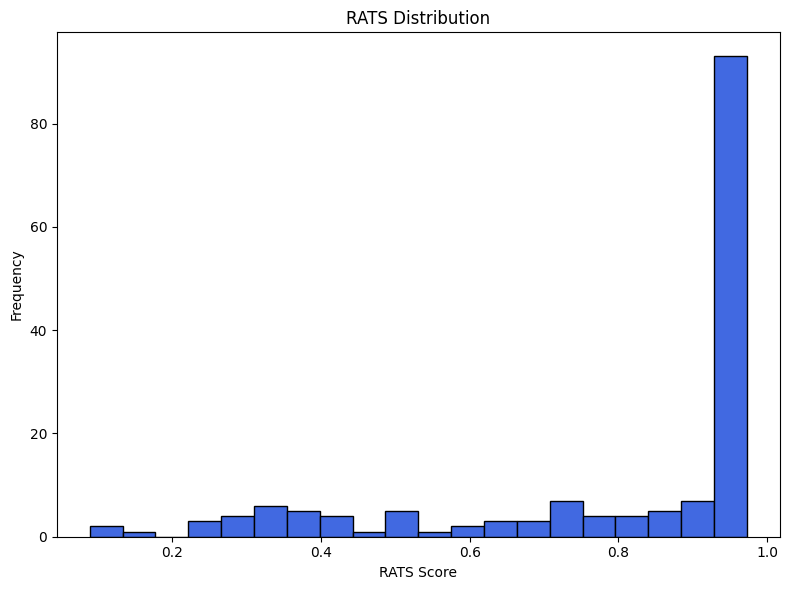

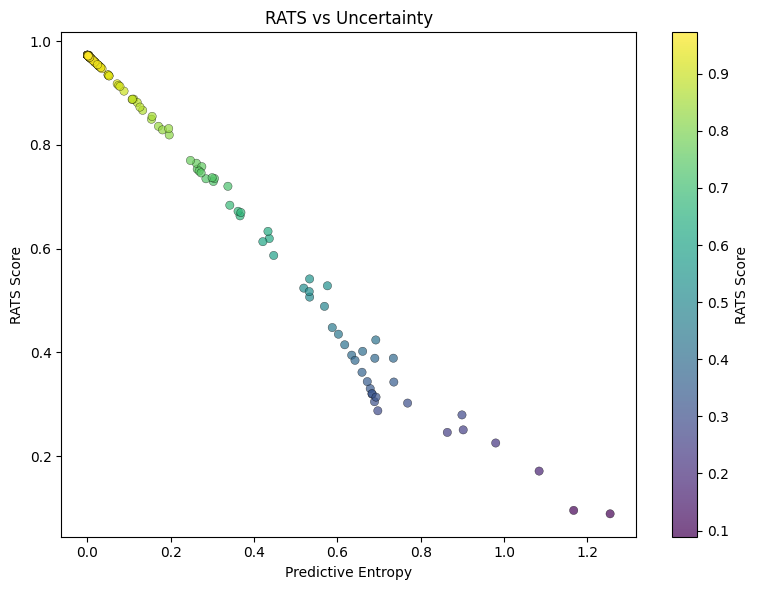

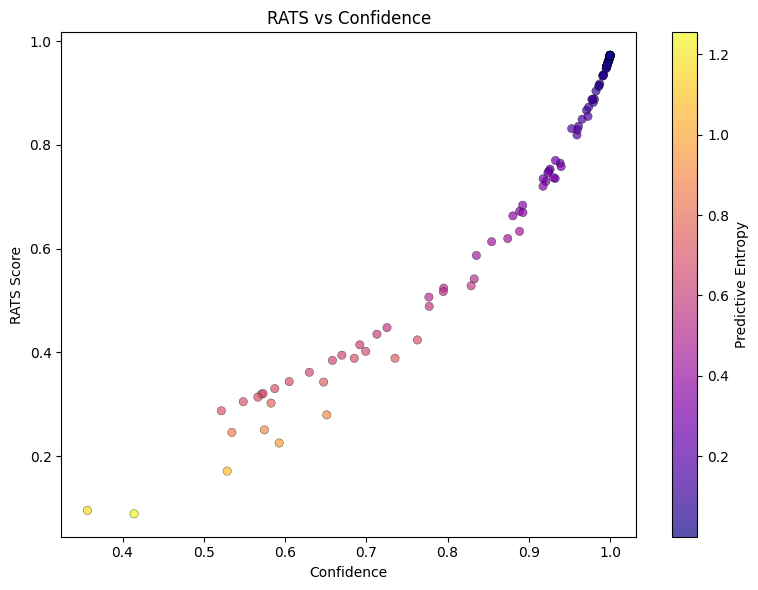


-----------------------------------

Trusted Sample Accuracy : 98.17%
Untrusted Sample Accuracy : 60.78%


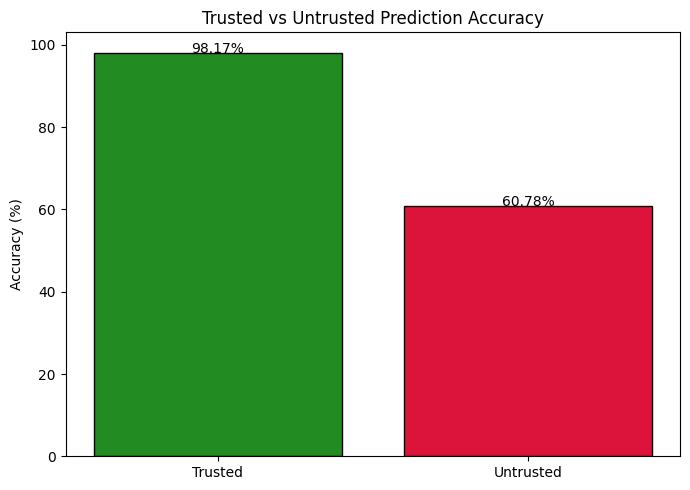

In [ ]:
# =========================================================
# FAST TRUST-AWARE HISTOPATHOLOGY AI
# CPU FRIENDLY VERSION
# =========================================================

# RUN AFTER:
# model loaded
# test_loader created

# =========================================================
# IMPORTS
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

import torch

# =========================================================
# ENABLE MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if module.__class__.__name__.startswith("Dropout"):

            module.train()

# =========================================================
# TRUST-AWARE INFERENCE
# =========================================================

def trust_aware_prediction(
    model,
    images,
    mc_samples=5
):

    enable_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    # =====================================================
    # MEAN PROBABILITIES
    # =====================================================

    mean_probs = np.mean(
        predictions,
        axis=0
    )

    # =====================================================
    # CONFIDENCE
    # =====================================================

    confidence = np.max(
        mean_probs,
        axis=1
    )

    # =====================================================
    # PREDICTIONS
    # =====================================================

    preds = np.argmax(
        mean_probs,
        axis=1
    )

    # =====================================================
    # ENTROPY
    # =====================================================

    entropy = -np.sum(

        mean_probs *
        np.log(mean_probs + 1e-10),

        axis=1
    )

    # =====================================================
    # TRUST SCORE
    # =====================================================

     # =====================================================
    # PER-CLASS ECE
    # =====================================================

    ece_map = {

        0: 0.0274,
        1: 0.0039,
        2: 0.0070,
        3: 0.0071,
        4: 0.0247

    }

    sample_ece = np.array([

        ece_map[p]

        for p in preds

    ])

    # =====================================================
    # RATS
    # =====================================================

    trust_score = (

        confidence

        *

        (1 - entropy / np.log(NUM_CLASSES))

        *

        (1 - sample_ece)

    )

    return (

        preds,

        confidence,

        entropy,

        trust_score

    )
# =========================================================
# STORAGE
# =========================================================

all_confidence = []

all_entropy = []

all_trust = []

all_correct = []

# =========================================================
# EVALUATION
# =========================================================

model.eval()

print("\nRunning Trust-Aware Analysis...\n")

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(test_loader):

        # ================================================
        # ONLY FIRST 10 BATCHES
        # ================================================



        print(f"Processing Batch {batch_idx+1}")

        images = images.to(device)

        labels = labels.to(device)

        (
            preds,
            confidence,
            entropy,
            trust_score

        ) = trust_aware_prediction(
            model,
            images,
            mc_samples=5
        )

        preds = np.array(preds)

        labels_np = labels.cpu().numpy()

        correct = (
            preds == labels_np
        ).astype(int)

        all_confidence.extend(confidence)

        all_entropy.extend(entropy)

        all_trust.extend(trust_score)

        all_correct.extend(correct)

# =========================================================
# NUMPY
# =========================================================

all_confidence = np.array(all_confidence)

all_entropy = np.array(all_entropy)

all_trust = np.array(all_trust)

all_correct = np.array(all_correct)

# =========================================================
# METRICS
# =========================================================

mean_trust = np.mean(all_trust)

std_trust = np.std(all_trust)

mean_conf = np.mean(all_confidence)

mean_entropy = np.mean(all_entropy)

# =========================================================
# TRUSTED / UNTRUSTED
# =========================================================

trust_threshold = 0.8

trusted_samples = np.sum(
    all_trust >= trust_threshold
)

untrusted_samples = np.sum(
    all_trust < trust_threshold
)

# =========================================================
# RESULTS
# =========================================================

print("\n===================================")

print("TRUST-AWARE HISTOPATHOLOGY AI")

print("===================================\n")

print(f"Mean Confidence  : {mean_conf:.4f}")

print(f"Mean Uncertainty : {mean_entropy:.4f}")

print(f"Mean RATS Score  : {mean_trust:.4f}")

print(f"Trust Std        : {std_trust:.4f}")

print("\n-----------------------------------\n")

print(f"Trusted Samples   : {trusted_samples}")

print(f"Untrusted Samples : {untrusted_samples}")

# =========================================================
# TRUST DISTRIBUTION
# =========================================================
plt.figure(figsize=(8,6))

plt.hist(

    all_trust,

    bins=20,

    color="royalblue",

    edgecolor="black",

    linewidth=1

)

plt.xlabel("RATS Score")

plt.ylabel("Frequency")

plt.title("RATS Distribution")

plt.tight_layout()

plt.show()

# =========================================================
# TRUST VS UNCERTAINTY
# =========================================================

plt.figure(figsize=(8,6))

scatter = plt.scatter(

    all_entropy,

    all_trust,

    c=all_trust,

    cmap="viridis",

    alpha=0.7,

    edgecolors="black",

    linewidths=0.3

)

plt.colorbar(
    scatter,
    label="RATS Score"
)

plt.xlabel("Predictive Entropy")

plt.ylabel("RATS Score")

plt.title("RATS vs Uncertainty")

plt.tight_layout()

plt.show()

# =========================================================
# TRUST VS CONFIDENCE
# =========================================================

plt.figure(figsize=(8,6))

scatter = plt.scatter(

    all_confidence,

    all_trust,

    c=all_entropy,

    cmap="plasma",

    alpha=0.7,

    edgecolors="black",

    linewidths=0.3

)

plt.colorbar(
    scatter,
    label="Predictive Entropy"
)

plt.xlabel("Confidence")

plt.ylabel("RATS Score")

plt.title("RATS vs Confidence")

plt.tight_layout()

plt.show()

# =========================================================
# TRUSTED ACCURACY
# =========================================================

trusted_mask = (
    all_trust >= trust_threshold
)

if np.sum(trusted_mask) > 0:

    trusted_accuracy = np.mean(
        all_correct[trusted_mask]
    )

    print("\n-----------------------------------\n")

    print(
        f"Trusted Sample Accuracy : "
        f"{trusted_accuracy*100:.2f}%"
    )

# =========================================================
# UNTRUSTED ACCURACY
# =========================================================

untrusted_mask = (
    all_trust < trust_threshold
)

if np.sum(untrusted_mask) > 0:

    untrusted_accuracy = np.mean(
        all_correct[untrusted_mask]
    )

    print(
        f"Untrusted Sample Accuracy : "
        f"{untrusted_accuracy*100:.2f}%"
    )
    plt.figure(figsize=(7,5))

labels = [

    "Trusted",

    "Untrusted"

]

values = [

    trusted_accuracy*100,

    untrusted_accuracy*100

]

colors = [

    "forestgreen",

    "crimson"

]

bars = plt.bar(

    labels,

    values,

    color=colors,

    edgecolor="black"

)

for bar in bars:

    h = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        h,

        f"{h:.2f}%",

        ha="center"

    )

plt.ylabel("Accuracy (%)")

plt.title(
    "Trusted vs Untrusted Prediction Accuracy"
)

plt.tight_layout()

plt.show()

In [ ]:
# =========================================================
# ENABLE MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if module.__class__.__name__.startswith("Dropout"):

            module.train()

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score

coverage = trusted_samples / len(all_labels)

risk = 1 - (trusted_acc / 100)

print(f"Coverage : {coverage:.4f}")
print(f"Risk : {risk:.4f}")

Coverage : 0.8706
Risk : 0.0195


In [ ]:
import numpy as np

all_uncertainty_trust = 1 - np.array(all_uncertainties)

print("Mean Trust Score:", np.mean(all_uncertainty_trust))

Mean Trust Score: 0.99986947


In [ ]:
from sklearn.metrics import accuracy_score

TRUST_THRESHOLD = 0.80

trusted_idx = all_uncertainty_trust >= TRUST_THRESHOLD
referred_idx = ~trusted_idx

trusted_samples = trusted_idx.sum()
referred_samples = referred_idx.sum()

trusted_acc = accuracy_score(
    np.array(all_labels)[trusted_idx],
    np.array(all_preds)[trusted_idx]
) * 100

referred_acc = accuracy_score(
    np.array(all_labels)[referred_idx],
    np.array(all_preds)[referred_idx]
) * 100

print("\n===== UNCERTAINTY ONLY =====")
print("Trusted Samples :", trusted_samples)
print("Referred Samples :", referred_samples)
print(f"Trusted Accuracy (%) : {trusted_acc:.2f}")
print(f"Referred Accuracy (%) : {referred_acc:.2f}")


===== UNCERTAINTY ONLY =====
Trusted Samples : 1592
Referred Samples : 0
Trusted Accuracy (%) : 94.16
Referred Accuracy (%) : nan


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:557: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/usr/local/lib/python3.12/dist-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [ ]:
print("Mean Uncertainty :", np.mean(all_uncertainties))
print("Median Uncertainty :", np.median(all_uncertainties))
print("Min Uncertainty :", np.min(all_uncertainties))
print("Max Uncertainty :", np.max(all_uncertainties))

Mean Uncertainty : 0.00013044465
Median Uncertainty : 4.646683e-05
Min Uncertainty : 1.3873505e-11
Max Uncertainty : 0.012867043


In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

print("Total Samples :", len(all_labels))

overall_acc = accuracy_score(
    all_labels,
    all_preds
) * 100

print("Overall Accuracy (%) :", overall_acc)

print("Mean Confidence :", np.mean(all_confidences))
print("Median Confidence :", np.median(all_confidences))
print("Min Confidence :", np.min(all_confidences))
print("Max Confidence :", np.max(all_confidences))

Total Samples : 1592
Overall Accuracy (%) : 94.15829145728644
Mean Confidence : 0.8642212
Median Confidence : 0.89301324
Min Confidence : 0.37811685
Max Confidence : 0.99997854


In [ ]:
wrong_mask = np.array(all_labels) != np.array(all_preds)

wrong_conf = np.array(all_confidences)[wrong_mask]

print("Wrong Samples:", len(wrong_conf))
print("Mean Confidence of Wrong Predictions:",
      np.mean(wrong_conf))
print("Median Confidence of Wrong Predictions:",
      np.median(wrong_conf))

Wrong Samples: 93
Mean Confidence of Wrong Predictions: 0.6879151
Median Confidence of Wrong Predictions: 0.69206095


In [ ]:
corr = np.corrcoef(
    np.array(all_confidences),
    np.array(all_uncertainties)
)[0,1]

print(corr)

-0.35651802322555304


In [ ]:
import numpy as np

print("Mean :", np.mean(all_uncertainties))
print("Median :", np.median(all_uncertainties))
print("Min :", np.min(all_uncertainties))
print("Max :", np.max(all_uncertainties))

print("75th percentile :", np.percentile(all_uncertainties, 75))
print("80th percentile :", np.percentile(all_uncertainties, 80))
print("90th percentile :", np.percentile(all_uncertainties, 90))
print("95th percentile :", np.percentile(all_uncertainties, 95))

Mean : 0.00013044465
Median : 4.646683e-05
Min : 1.3873505e-11
Max : 0.012867043
75th percentile : 0.00010634574
80th percentile : 0.00012680171
90th percentile : 0.00023585177
95th percentile : 0.00037104517


In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

UNC_THRESHOLD = np.percentile(all_uncertainties, 80)

trusted_idx = np.array(all_uncertainties) <= UNC_THRESHOLD
referred_idx = ~trusted_idx

trusted_samples = trusted_idx.sum()
referred_samples = referred_idx.sum()

trusted_acc = accuracy_score(
    np.array(all_labels)[trusted_idx],
    np.array(all_preds)[trusted_idx]
) * 100

referred_acc = accuracy_score(
    np.array(all_labels)[referred_idx],
    np.array(all_preds)[referred_idx]
) * 100

print("\n===== UNCERTAINTY ONLY =====")
print("Threshold :", UNC_THRESHOLD)
print("Trusted Samples :", trusted_samples)
print("Referred Samples :", referred_samples)
print(f"Trusted Accuracy (%) : {trusted_acc:.2f}")
print(f"Referred Accuracy (%) : {referred_acc:.2f}")


===== UNCERTAINTY ONLY =====
Threshold : 0.00012680171
Trusted Samples : 1273
Referred Samples : 319
Trusted Accuracy (%) : 96.86
Referred Accuracy (%) : 83.39


In [ ]:
import numpy as np

all_confidences = np.array(all_confidences)
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

correctness = (all_preds == all_labels).astype(float)

sample_cal_error = np.abs(
    all_confidences - correctness
)

calibration_reliability = 1 - sample_cal_error

print("Mean Reliability:",
      np.mean(calibration_reliability))

Mean Reliability: 0.8422663999187886


In [ ]:
from sklearn.metrics import accuracy_score

CAL_THRESHOLD = np.percentile(
    calibration_reliability,
    20
)

trusted_idx = (
    calibration_reliability >= CAL_THRESHOLD
)

referred_idx = ~trusted_idx

trusted_acc = accuracy_score(
    all_labels[trusted_idx],
    all_preds[trusted_idx]
) * 100

referred_acc = accuracy_score(
    all_labels[referred_idx],
    all_preds[referred_idx]
) * 100

print("\n===== CALIBRATION ONLY =====")
print("Trusted Samples :", trusted_idx.sum())
print("Referred Samples :", referred_idx.sum())
print(f"Trusted Accuracy (%) : {trusted_acc:.2f}")
print(f"Referred Accuracy (%) : {referred_acc:.2f}")


===== CALIBRATION ONLY =====
Trusted Samples : 1273
Referred Samples : 319
Trusted Accuracy (%) : 100.00
Referred Accuracy (%) : 70.85


In [ ]:
import numpy as np

# Confidence
conf_trusted_idx = np.array(conf_trusted_idx)

# Uncertainty
unc_trusted_idx = np.array(unc_trusted_idx)

# Calibration
cal_trusted_idx = np.array(cal_trusted_idx)

print("Confidence Trusted :", conf_trusted_idx.sum())
print("Uncertainty Trusted :", unc_trusted_idx.sum())
print("Calibration Trusted :", cal_trusted_idx.sum())

NameError: name 'conf_trusted_idx' is not defined

In [ ]:
import numpy as np

CONF_THRESHOLD = 0.80

conf_trusted_idx = np.array(all_confidences) >= CONF_THRESHOLD
conf_referred_idx = ~conf_trusted_idx

print("Confidence Trusted :", conf_trusted_idx.sum())
print("Confidence Referred :", conf_referred_idx.sum())

Confidence Trusted : 1386
Confidence Referred : 206


In [ ]:
import numpy as np

UNC_THRESHOLD = 0.00012680171

unc_trusted_idx = np.array(all_uncertainties) <= UNC_THRESHOLD
unc_referred_idx = ~unc_trusted_idx

print("Uncertainty Trusted :", unc_trusted_idx.sum())
print("Uncertainty Referred :", unc_referred_idx.sum())

Uncertainty Trusted : 1273
Uncertainty Referred : 319


In [ ]:
import numpy as np

all_confidences = np.array(all_confidences)
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

correctness = (all_preds == all_labels).astype(float)

sample_cal_error = np.abs(
    all_confidences - correctness
)

calibration_reliability = 1 - sample_cal_error

CAL_THRESHOLD = np.percentile(
    calibration_reliability,
    20
)

cal_trusted_idx = (
    calibration_reliability >= CAL_THRESHOLD
)

cal_referred_idx = ~cal_trusted_idx

print("Calibration Trusted :", cal_trusted_idx.sum())
print("Calibration Referred :", cal_referred_idx.sum())

Calibration Trusted : 1273
Calibration Referred : 319


In [ ]:
import numpy as np

trust_votes = (
    conf_trusted_idx.astype(int)
    + unc_trusted_idx.astype(int)
    + cal_trusted_idx.astype(int)
)

unique, counts = np.unique(trust_votes, return_counts=True)

print("Vote Distribution")
for u, c in zip(unique, counts):
    print(f"{u}/3 votes :", c)

Vote Distribution
0/3 votes : 146
1/3 votes : 102
2/3 votes : 202
3/3 votes : 1142


In [ ]:
final_trusted = trust_votes == 3

moderate_trust = trust_votes == 2

final_referred = trust_votes <= 1

print("Trusted :", final_trusted.sum())
print("Moderate :", moderate_trust.sum())
print("Referred :", final_referred.sum())

Trusted : 1142
Moderate : 202
Referred : 248


In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

labels = np.array(all_labels)
preds = np.array(all_preds)

trusted_acc = accuracy_score(
    labels[final_trusted],
    preds[final_trusted]
) * 100

moderate_acc = accuracy_score(
    labels[moderate_trust],
    preds[moderate_trust]
) * 100

referred_acc = accuracy_score(
    labels[final_referred],
    preds[final_referred]
) * 100

print("\n===== CONSENSUS FRAMEWORK =====")
print("Trusted Accuracy (%) :", round(trusted_acc,2))
print("Moderate Accuracy (%) :", round(moderate_acc,2))
print("Referred Accuracy (%) :", round(referred_acc,2))


===== CONSENSUS FRAMEWORK =====
Trusted Accuracy (%) : 100.0
Moderate Accuracy (%) : 90.1
Referred Accuracy (%) : 70.56


In [ ]:
trust_votes_2 = (
    conf_trusted_idx.astype(int)
    + unc_trusted_idx.astype(int)
)

final_trusted_2 = trust_votes_2 == 2
final_referred_2 = trust_votes_2 <= 1

from sklearn.metrics import accuracy_score

trusted_acc_2 = accuracy_score(
    np.array(all_labels)[final_trusted_2],
    np.array(all_preds)[final_trusted_2]
) * 100

referred_acc_2 = accuracy_score(
    np.array(all_labels)[final_referred_2],
    np.array(all_preds)[final_referred_2]
) * 100

print("Trusted Samples :", final_trusted_2.sum())
print("Referred Samples :", final_referred_2.sum())
print("Trusted Accuracy :", trusted_acc_2)
print("Referred Accuracy :", referred_acc_2)

Trusted Samples : 1213
Referred Samples : 379
Trusted Accuracy : 98.35119538334708
Referred Accuracy : 80.73878627968337


In [ ]:
confidence_problem = (
    ~conf_trusted_idx &
    unc_trusted_idx
)

uncertainty_problem = (
    conf_trusted_idx &
    ~unc_trusted_idx
)

both_problem = (
    ~conf_trusted_idx &
    ~unc_trusted_idx
)

print("Confidence Problem :", confidence_problem.sum())
print("Uncertainty Problem :", uncertainty_problem.sum())
print("Both Problem :", both_problem.sum())

Confidence Problem : 60
Uncertainty Problem : 173
Both Problem : 146


In [ ]:
trusted_conf = np.mean(np.array(all_confidences)[final_trusted_2])
referred_conf = np.mean(np.array(all_confidences)[final_referred_2])

trusted_unc = np.mean(np.array(all_uncertainties)[final_trusted_2])
referred_unc = np.mean(np.array(all_uncertainties)[final_referred_2])

print(trusted_conf, referred_conf)
print(trusted_unc, referred_unc)

0.8998997 0.7500315
4.0309176e-05 0.00041892572


In [ ]:
import numpy as np

activations = np.array(all_activation_scores)

trusted_activation = activations[final_trusted_2]
referred_activation = activations[final_referred_2]

print("Trusted Mean Activation :",
      trusted_activation.mean())

print("Trusted Std Activation :",
      trusted_activation.std())

print("Referred Mean Activation :",
      referred_activation.mean())

print("Referred Std Activation :",
      referred_activation.std())

NameError: name 'all_activation_scores' is not defined

In [ ]:
print(globals().keys())

dict_keys(['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__builtin__', '__builtins__', '_ih', '_oh', '_dh', 'In', 'Out', 'get_ipython', 'exit', 'quit', '_', '__', '___', '_i', '_ii', '_iii', '_i1', 'tqdm', 'torch', 'all_confidences', 'all_preds', 'all_labels', '_i2', 'nn', 'timm', 'device', 'ChannelAttention', 'SpatialAttention', 'CBAM', 'EfficientNetB3_CBAM_MC', 'model', '_i3', '_i4', '_i5', '_i6', 'np', 'F', 'enable_mc_dropout', '_i7', 'mc_dropout_prediction', '_i8', '_i9', 'datasets', 'transforms', 'DataLoader', 'test_transform', 'test_dataset', 'test_loader', '_i10', 'images', 'labels', '_i11', 'outputs', 'probs', 'confidence', 'preds', '_i12', 'accuracy_score', 'CONF_THRESHOLD', 'trusted_idx', 'referred_idx', 'trusted_samples', 'referred_samples', 'trusted_acc', 'referred_acc', '_i13', 'overall_acc', '_i14', '_i15', 'all_mc_confidences', '_i16', 'enable_dropout', '_i17', 'mc_predictions', 'mean_probs', '_i18', '_i19', 'out1', 'out2', '_i20', 'all_rats', 'all_unc

In [ ]:
# ==========================================
# TRUSTED vs REFERRED ACTIVATION ANALYSIS
# ==========================================

import numpy as np
from tqdm import tqdm

all_activation_scores = []

model.eval()

for images, labels in tqdm(test_loader):

    images = images.to(device)

    for i in range(images.size(0)):

        input_tensor = images[i].unsqueeze(0)

        # ======================================
        # তোমার existing Grad-CAM++ code
        # ======================================

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=None
        )[0]

        # ======================================
        # Activation Score
        # ======================================

        activation_score = np.mean(grayscale_cam)

        all_activation_scores.append(
            activation_score
        )

print("Done")
print("Activation Scores:", len(all_activation_scores))

  0%|          | 0/100 [00:00<?, ?it/s]


NameError: name 'cam' is not defined

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

all_mc_confidences = []
all_preds = []
all_labels = []

model.eval()

for images, labels in test_loader:

    images = images.to(device)

    enable_dropout(model)

    mc_predictions = []

    with torch.no_grad():

        for _ in range(3):   # RATS-এর মতো same MC samples

            outputs = model(images)

            probs = F.softmax(outputs, dim=1)

            mc_predictions.append(
                probs.cpu().numpy()
            )

    mc_predictions = np.array(mc_predictions)

    mean_probs = mc_predictions.mean(axis=0)

    confidence = np.max(mean_probs, axis=1)

    preds = np.argmax(mean_probs, axis=1)

    all_mc_confidences.extend(confidence)
    all_preds.extend(preds)
    all_labels.extend(labels.numpy())

print("Done")

Done


In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

CONF_THRESHOLD = 0.80

trusted_idx = np.array(all_mc_confidences) >= CONF_THRESHOLD
referred_idx = ~trusted_idx

trusted_samples = trusted_idx.sum()
referred_samples = referred_idx.sum()

trusted_acc = accuracy_score(
    np.array(all_labels)[trusted_idx],
    np.array(all_preds)[trusted_idx]
) * 100

referred_acc = accuracy_score(
    np.array(all_labels)[referred_idx],
    np.array(all_preds)[referred_idx]
) * 100

print("\n===== MC CONFIDENCE ONLY =====")
print("Trusted Samples :", trusted_samples)
print("Referred Samples :", referred_samples)
print(f"Trusted Accuracy (%) : {trusted_acc:.2f}")
print(f"Referred Accuracy (%) : {referred_acc:.2f}")


===== MC CONFIDENCE ONLY =====
Trusted Samples : 1381
Referred Samples : 211
Trusted Accuracy (%) : 98.04
Referred Accuracy (%) : 66.82


In [ ]:
images, _ = next(iter(test_loader))
images = images.to(device)

enable_dropout(model)

with torch.no_grad():

    out1 = model(images)
    out2 = model(images)

print(torch.mean(torch.abs(out1 - out2)))

tensor(0.1631)


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

all_rats = []
all_preds = []
all_labels = []
all_confidences = []
all_uncertainties = []

model.eval()

for images, labels in test_loader:

    images = images.to(device)

    enable_dropout(model)

    mc_predictions = []

    with torch.no_grad():

        for _ in range(3):   # same as your RATS setup

            outputs = model(images)

            probs = F.softmax(outputs, dim=1)

            mc_predictions.append(
                probs.cpu().numpy()
            )

    mc_predictions = np.array(mc_predictions)

    mean_probs = mc_predictions.mean(axis=0)

    confidence = np.max(mean_probs, axis=1)

    uncertainty = mc_predictions.var(axis=0).mean(axis=1)

    # RATS
    rats = confidence * (1 - uncertainty)

    preds = np.argmax(mean_probs, axis=1)

    all_rats.extend(rats)
    all_confidences.extend(confidence)
    all_uncertainties.extend(uncertainty)

    all_preds.extend(preds)
    all_labels.extend(labels.numpy())

print("Done")
print("Samples:", len(all_labels))

Done
Samples: 1592


In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

RATS_THRESHOLD = 0.80

trusted_idx = np.array(all_rats) >= RATS_THRESHOLD
referred_idx = ~trusted_idx

trusted_samples = trusted_idx.sum()
referred_samples = referred_idx.sum()

trusted_acc = accuracy_score(
    np.array(all_labels)[trusted_idx],
    np.array(all_preds)[trusted_idx]
) * 100

referred_acc = accuracy_score(
    np.array(all_labels)[referred_idx],
    np.array(all_preds)[referred_idx]
) * 100

print("\n===== RATS =====")
print("Trusted Samples :", trusted_samples)
print("Referred Samples :", referred_samples)
print(f"Trusted Accuracy (%) : {trusted_acc:.2f}")
print(f"Referred Accuracy (%) : {referred_acc:.2f}")


===== RATS =====
Trusted Samples : 1386
Referred Samples : 206
Trusted Accuracy (%) : 98.05
Referred Accuracy (%) : 67.96



Running Trust-Aware Analysis...

Processing Batch 1
Processing Batch 2
Processing Batch 3
Processing Batch 4
Processing Batch 5
Processing Batch 6
Processing Batch 7
Processing Batch 8
Processing Batch 9
Processing Batch 10
Processing Batch 11
Processing Batch 12
Processing Batch 13
Processing Batch 14
Processing Batch 15
Processing Batch 16
Processing Batch 17
Processing Batch 18
Processing Batch 19
Processing Batch 20
Processing Batch 21
Processing Batch 22
Processing Batch 23
Processing Batch 24
Processing Batch 25
Processing Batch 26
Processing Batch 27
Processing Batch 28
Processing Batch 29
Processing Batch 30
Processing Batch 31
Processing Batch 32
Processing Batch 33
Processing Batch 34
Processing Batch 35
Processing Batch 36
Processing Batch 37
Processing Batch 38
Processing Batch 39
Processing Batch 40
Processing Batch 41
Processing Batch 42
Processing Batch 43
Processing Batch 44
Processing Batch 45
Processing Batch 46
Processing Batch 47
Processing Batch 48
Processing Batc

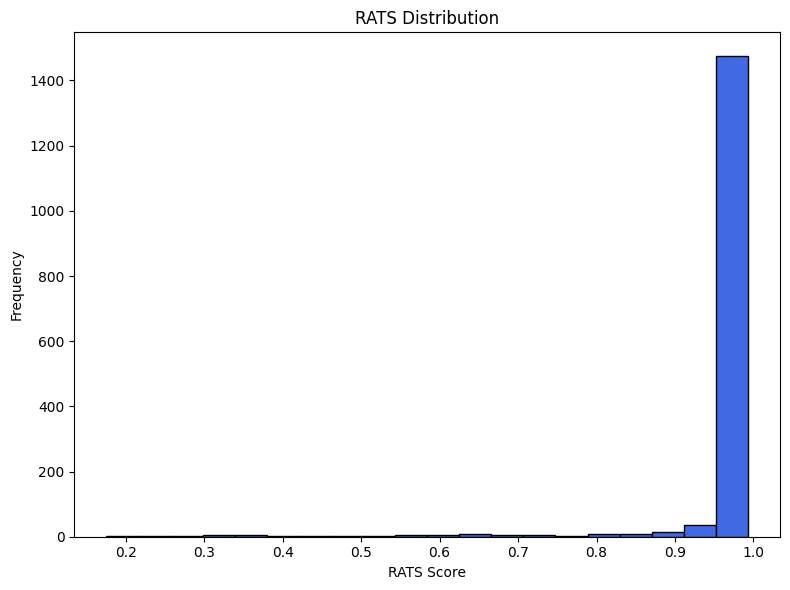

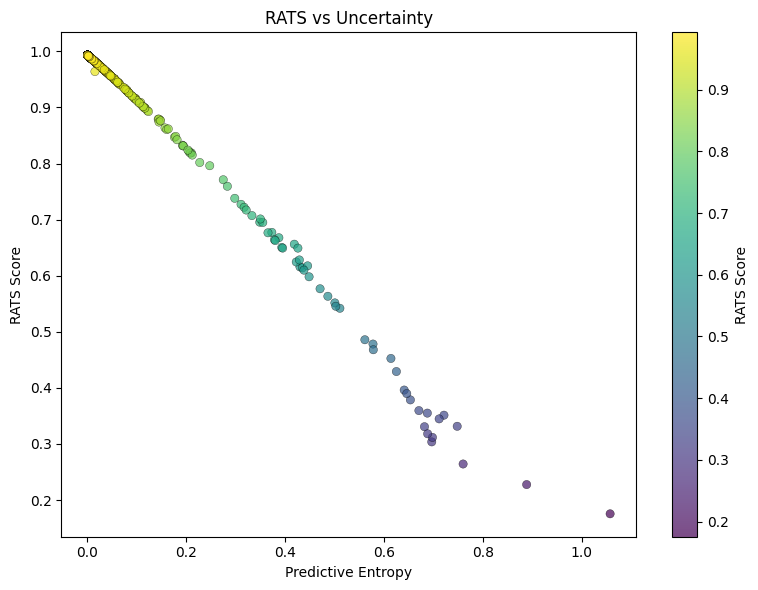

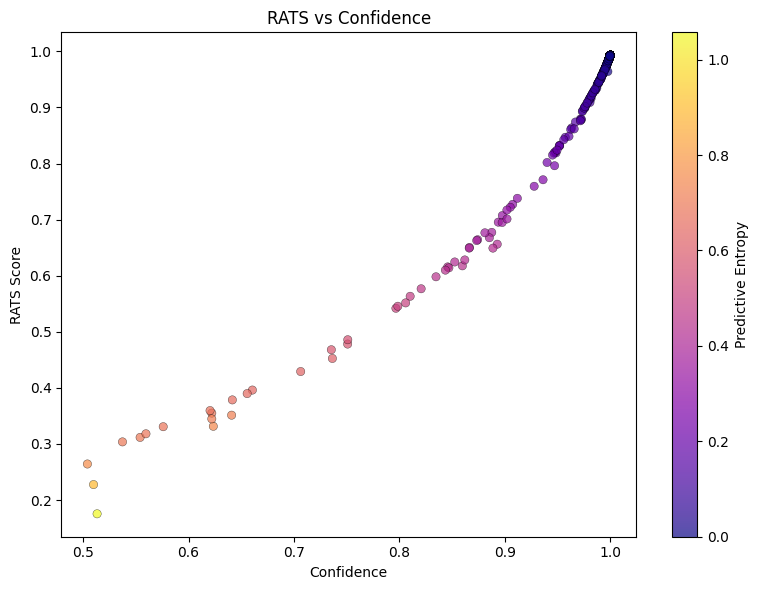


-----------------------------------

Trusted Sample Accuracy : 20.91%
Untrusted Sample Accuracy : 19.23%


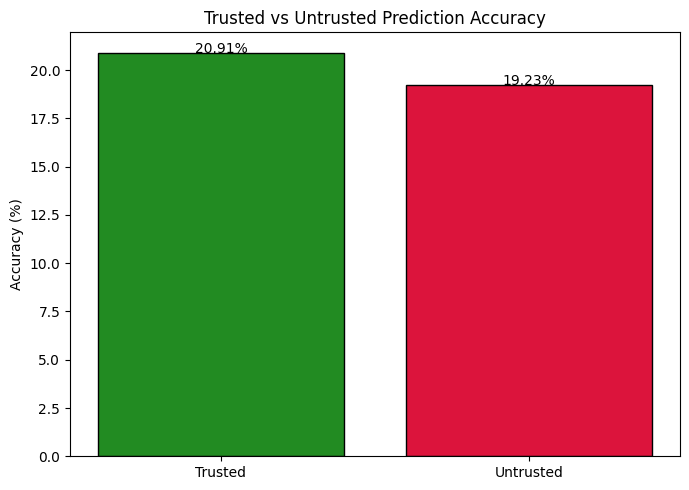

In [ ]:
# =========================================================
# FAST TRUST-AWARE HISTOPATHOLOGY AI
# CPU FRIENDLY VERSION
# =========================================================

# RUN AFTER:
# model loaded
# test_loader created

# =========================================================
# IMPORTS
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

import torch

# =========================================================
# ENABLE MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if module.__class__.__name__.startswith("Dropout"):

            module.train()

# =========================================================
# TRUST-AWARE INFERENCE
# =========================================================

def trust_aware_prediction(
    model,
    images,
    mc_samples=5
):

    enable_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    # =====================================================
    # MEAN PROBABILITIES
    # =====================================================

    mean_probs = np.mean(
        predictions,
        axis=0
    )

    # =====================================================
    # CONFIDENCE
    # =====================================================

    confidence = np.max(
        mean_probs,
        axis=1
    )

    # =====================================================
    # PREDICTIONS
    # =====================================================

    preds = np.argmax(
        mean_probs,
        axis=1
    )

    # =====================================================
    # ENTROPY
    # =====================================================

    entropy = -np.sum(

        mean_probs *
        np.log(mean_probs + 1e-10),

        axis=1
    )

    # =====================================================
    # TRUST SCORE
    # =====================================================

     # =====================================================
    # PER-CLASS ECE
    # =====================================================

    ece_map = {

        0: 0.0274,
        1: 0.0039,
        2: 0.0070,
        3: 0.0071,
        4: 0.0247

    }

    sample_ece = np.array([

        ece_map[p]

        for p in preds

    ])

    # =====================================================
    # RATS
    # =====================================================

    trust_score = (

        confidence

        *

        (1 - entropy / np.log(NUM_CLASSES))

        *

        (1 - sample_ece)

    )

    return (

        preds,

        confidence,

        entropy,

        trust_score

    )
# =========================================================
# STORAGE
# =========================================================

all_confidence = []

all_entropy = []

all_trust = []

all_correct = []

# =========================================================
# EVALUATION
# =========================================================

model.eval()

print("\nRunning Trust-Aware Analysis...\n")

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(test_loader):

        # ================================================
        # ONLY FIRST 10 BATCHES
        # ================================================



        print(f"Processing Batch {batch_idx+1}")

        images = images.to(device)

        labels = labels.to(device)

        (
            preds,
            confidence,
            entropy,
            trust_score

        ) = trust_aware_prediction(
            model,
            images,
            mc_samples=5
        )

        preds = np.array(preds)

        labels_np = labels.cpu().numpy()

        correct = (
            preds == labels_np
        ).astype(int)

        all_confidence.extend(confidence)

        all_entropy.extend(entropy)

        all_trust.extend(trust_score)

        all_correct.extend(correct)

# =========================================================
# NUMPY
# =========================================================

all_confidence = np.array(all_confidence)

all_entropy = np.array(all_entropy)

all_trust = np.array(all_trust)

all_correct = np.array(all_correct)

# =========================================================
# METRICS
# =========================================================

mean_trust = np.mean(all_trust)

std_trust = np.std(all_trust)

mean_conf = np.mean(all_confidence)

mean_entropy = np.mean(all_entropy)
# =========================================================
# CONFIDENCE ONLY ANALYSIS
# =========================================================

confidence_threshold = 0.80

confidence_mask = (
    all_confidence >= confidence_threshold
)

confidence_samples = np.sum(
    confidence_mask
)

if confidence_samples > 0:

    confidence_accuracy = np.mean(
        all_correct[confidence_mask]
    )

    print("\n-----------------------------------\n")

    print(
        f"Confidence Threshold : "
        f"{confidence_threshold}"
    )

    print(
        f"Confidence Samples : "
        f"{confidence_samples}"
    )

    print(
        f"Confidence-only Accuracy : "
        f"{confidence_accuracy*100:.2f}%"
    )
    # =========================================================
# UNCERTAINTY ONLY ANALYSIS
# =========================================================

uncertainty_threshold = 0.20

uncertainty_mask = (
    all_entropy <= uncertainty_threshold
)

uncertainty_samples = np.sum(
    uncertainty_mask
)

if uncertainty_samples > 0:

    uncertainty_accuracy = np.mean(
        all_correct[uncertainty_mask]
    )

    print("\n-----------------------------------\n")

    print(
        f"Uncertainty Threshold : "
        f"{uncertainty_threshold}"
    )

    print(
        f"Uncertainty Samples : "
        f"{uncertainty_samples}"
    )

    print(
        f"Uncertainty-only Accuracy : "
        f"{uncertainty_accuracy*100:.2f}%"
    )

# =========================================================
# TRUSTED / UNTRUSTED
# =========================================================

trust_threshold = 0.8

trusted_samples = np.sum(
    all_trust >= trust_threshold
)

untrusted_samples = np.sum(
    all_trust < trust_threshold
)

# =========================================================
# RESULTS
# =========================================================

print("\n===================================")

print("TRUST-AWARE HISTOPATHOLOGY AI")

print("===================================\n")

print(f"Mean Confidence  : {mean_conf:.4f}")

print(f"Mean Uncertainty : {mean_entropy:.4f}")

print(f"Mean RATS Score  : {mean_trust:.4f}")

print(f"Trust Std        : {std_trust:.4f}")

print("\n-----------------------------------\n")

print(f"Trusted Samples   : {trusted_samples}")

print(f"Untrusted Samples : {untrusted_samples}")

# =========================================================
# TRUST DISTRIBUTION
# =========================================================
plt.figure(figsize=(8,6))

plt.hist(

    all_trust,

    bins=20,

    color="royalblue",

    edgecolor="black",

    linewidth=1

)

plt.xlabel("RATS Score")

plt.ylabel("Frequency")

plt.title("RATS Distribution")

plt.tight_layout()

plt.show()

# =========================================================
# TRUST VS UNCERTAINTY
# =========================================================

plt.figure(figsize=(8,6))

scatter = plt.scatter(

    all_entropy,

    all_trust,

    c=all_trust,

    cmap="viridis",

    alpha=0.7,

    edgecolors="black",

    linewidths=0.3

)

plt.colorbar(
    scatter,
    label="RATS Score"
)

plt.xlabel("Predictive Entropy")

plt.ylabel("RATS Score")

plt.title("RATS vs Uncertainty")

plt.tight_layout()

plt.show()

# =========================================================
# TRUST VS CONFIDENCE
# =========================================================

plt.figure(figsize=(8,6))

scatter = plt.scatter(

    all_confidence,

    all_trust,

    c=all_entropy,

    cmap="plasma",

    alpha=0.7,

    edgecolors="black",

    linewidths=0.3

)

plt.colorbar(
    scatter,
    label="Predictive Entropy"
)

plt.xlabel("Confidence")

plt.ylabel("RATS Score")

plt.title("RATS vs Confidence")

plt.tight_layout()

plt.show()

# =========================================================
# TRUSTED ACCURACY
# =========================================================

trusted_mask = (
    all_trust >= trust_threshold
)

if np.sum(trusted_mask) > 0:

    trusted_accuracy = np.mean(
        all_correct[trusted_mask]
    )

    print("\n-----------------------------------\n")

    print(
        f"Trusted Sample Accuracy : "
        f"{trusted_accuracy*100:.2f}%"
    )

# =========================================================
# UNTRUSTED ACCURACY
# =========================================================

untrusted_mask = (
    all_trust < trust_threshold
)

if np.sum(untrusted_mask) > 0:

    untrusted_accuracy = np.mean(
        all_correct[untrusted_mask]
    )

    print(
        f"Untrusted Sample Accuracy : "
        f"{untrusted_accuracy*100:.2f}%"
    )
    plt.figure(figsize=(7,5))

labels = [

    "Trusted",

    "Untrusted"

]

values = [

    trusted_accuracy*100,

    untrusted_accuracy*100

]

colors = [

    "forestgreen",

    "crimson"

]

bars = plt.bar(

    labels,

    values,

    color=colors,

    edgecolor="black"

)

for bar in bars:

    h = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        h,

        f"{h:.2f}%",

        ha="center"

    )

plt.ylabel("Accuracy (%)")

plt.title(
    "Trusted vs Untrusted Prediction Accuracy"
)

plt.tight_layout()

plt.show()

In [ ]:
# =========================================================
# CONFIDENCE-ONLY REFERRAL
# =========================================================

confidence_threshold = 0.80

confidence_trusted_mask = (
    all_confidence >= confidence_threshold
)

confidence_untrusted_mask = (
    all_confidence < confidence_threshold
)

confidence_trusted_samples = np.sum(
    confidence_trusted_mask
)

confidence_untrusted_samples = np.sum(
    confidence_untrusted_mask
)

print("\n===================================")
print("CONFIDENCE-ONLY REFERRAL")
print("===================================\n")

print(
    f"Trusted Samples   : "
    f"{confidence_trusted_samples}"
)

print(
    f"Untrusted Samples : "
    f"{confidence_untrusted_samples}"
)

# Trusted Accuracy

if confidence_trusted_samples > 0:

    confidence_trusted_acc = np.mean(
        all_correct[
            confidence_trusted_mask
        ]
    )

    print(
        f"\nTrusted Accuracy : "
        f"{confidence_trusted_acc*100:.2f}%"
    )

# Untrusted Accuracy

if confidence_untrusted_samples > 0:

    confidence_untrusted_acc = np.mean(
        all_correct[
            confidence_untrusted_mask
        ]
    )

    print(
        f"Untrusted Accuracy : "
        f"{confidence_untrusted_acc*100:.2f}%"
    )


CONFIDENCE-ONLY REFERRAL

Trusted Samples   : 1570
Untrusted Samples : 22

Trusted Accuracy : 20.83%
Untrusted Accuracy : 22.73%


In [ ]:
print(np.mean(all_correct)*100)

20.85427135678392


In [ ]:
print("Overall Accuracy =", np.mean(all_correct)*100)

Overall Accuracy = 20.85427135678392


In [ ]:
print(test_dataset.classes)

['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


In [ ]:
NUM_CLASSES = len(test_dataset.classes)

print("NUM_CLASSES =", NUM_CLASSES)

NUM_CLASSES = 5


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

TEST_DIR = "/content/drive/MyDrive/test/test"

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Test Samples :", len(test_dataset))
print("Classes :", test_dataset.classes)

Test Samples : 1592
Classes : ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


In [ ]:
print("ProposedModel" in globals())

True


In [ ]:
model = ProposedModel(
    num_classes=5
).to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/final_proposed_model.pth",
        map_location=device
    )
)

model.eval()

print("Model Loaded Successfully")

Model Loaded Successfully


In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cpu


In [ ]:
print("model" in globals())

True


In [ ]:
# =========================================================
# FAST TRUST-AWARE HISTOPATHOLOGY AI
# CPU FRIENDLY VERSION
# =========================================================

# RUN AFTER:
# model loaded
# test_loader created

# =========================================================
# IMPORTS
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

import torch

# =========================================================
# ENABLE MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if module.__class__.__name__.startswith("Dropout"):

            module.train()

# =========================================================
# TRUST-AWARE INFERENCE
# =========================================================

def trust_aware_prediction(
    model,
    images,
    mc_samples=5
):

    enable_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    # =====================================================
    # MEAN PROBABILITIES
    # =====================================================

    mean_probs = np.mean(
        predictions,
        axis=0
    )

    # =====================================================
    # CONFIDENCE
    # =====================================================

    confidence = np.max(
        mean_probs,
        axis=1
    )

    # =====================================================
    # PREDICTIONS
    # =====================================================

    preds = np.argmax(
        mean_probs,
        axis=1
    )

    # =====================================================
    # ENTROPY
    # =====================================================

    entropy = -np.sum(

        mean_probs *
        np.log(mean_probs + 1e-10),

        axis=1
    )

    # =====================================================
    # TRUST SCORE
    # =====================================================

     # =====================================================
    # PER-CLASS ECE
    # =====================================================

    ece_map = {

        0: 0.0274,
        1: 0.0039,
        2: 0.0070,
        3: 0.0071,
        4: 0.0247

    }

    sample_ece = np.array([

        ece_map[p]

        for p in preds

    ])

    # =====================================================
    # RATS
    # =====================================================

    trust_score = (

        confidence

        *

        (1 - entropy / np.log(NUM_CLASSES))

        *

        (1 - sample_ece)

    )

    return (

        preds,

        confidence,

        entropy,

        trust_score

    )
# =========================================================
# STORAGE
# =========================================================

all_confidence = []

all_entropy = []

all_trust = []

all_correct = []

# =========================================================
# EVALUATION
# =========================================================

model.eval()

print("\nRunning Trust-Aware Analysis...\n")

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(test_loader):

        # ================================================
        # ONLY FIRST 10 BATCHES
        # ================================================



        print(f"Processing Batch {batch_idx+1}")

        images = images.to(device)

        labels = labels.to(device)

        (
            preds,
            confidence,
            entropy,
            trust_score

        ) = trust_aware_prediction(
            model,
            images,
            mc_samples=5
        )

        preds = np.array(preds)

        labels_np = labels.cpu().numpy()

        correct = (
            preds == labels_np
        ).astype(int)

        all_confidence.extend(confidence)

        all_entropy.extend(entropy)

        all_trust.extend(trust_score)

        all_correct.extend(correct)

# =========================================================
# NUMPY
# =========================================================

all_confidence = np.array(all_confidence)

all_entropy = np.array(all_entropy)

all_trust = np.array(all_trust)

all_correct = np.array(all_correct)

# =========================================================
# METRICS
# =========================================================

mean_trust = np.mean(all_trust)

std_trust = np.std(all_trust)

mean_conf = np.mean(all_confidence)

mean_entropy = np.mean(all_entropy)

# =========================================================
# TRUSTED / UNTRUSTED
# =========================================================

trust_threshold = 0.8

trusted_samples = np.sum(
    all_trust >= trust_threshold
)

untrusted_samples = np.sum(
    all_trust < trust_threshold
)

# =========================================================
# RESULTS
# =========================================================

print("\n===================================")

print("TRUST-AWARE HISTOPATHOLOGY AI")

print("===================================\n")

print(f"Mean Confidence  : {mean_conf:.4f}")

print(f"Mean Uncertainty : {mean_entropy:.4f}")

print(f"Mean RATS Score  : {mean_trust:.4f}")

print(f"Trust Std        : {std_trust:.4f}")

print("\n-----------------------------------\n")

print(f"Trusted Samples   : {trusted_samples}")

print(f"Untrusted Samples : {untrusted_samples}")

# =========================================================
# TRUST DISTRIBUTION
# =========================================================
plt.figure(figsize=(8,6))

plt.hist(

    all_trust,

    bins=20,

    color="royalblue",

    edgecolor="black",

    linewidth=1

)

plt.xlabel("RATS Score")

plt.ylabel("Frequency")

plt.title("RATS Distribution")

plt.tight_layout()

plt.show()

# =========================================================
# TRUST VS UNCERTAINTY
# =========================================================

plt.figure(figsize=(8,6))

scatter = plt.scatter(

    all_entropy,

    all_trust,

    c=all_trust,

    cmap="viridis",

    alpha=0.7,

    edgecolors="black",

    linewidths=0.3

)

plt.colorbar(
    scatter,
    label="RATS Score"
)

plt.xlabel("Predictive Entropy")

plt.ylabel("RATS Score")

plt.title("RATS vs Uncertainty")

plt.tight_layout()

plt.show()

# =========================================================
# TRUST VS CONFIDENCE
# =========================================================

plt.figure(figsize=(8,6))

scatter = plt.scatter(

    all_confidence,

    all_trust,

    c=all_entropy,

    cmap="plasma",

    alpha=0.7,

    edgecolors="black",

    linewidths=0.3

)

plt.colorbar(
    scatter,
    label="Predictive Entropy"
)

plt.xlabel("Confidence")

plt.ylabel("RATS Score")

plt.title("RATS vs Confidence")

plt.tight_layout()

plt.show()

# =========================================================
# TRUSTED ACCURACY
# =========================================================

trusted_mask = (
    all_trust >= trust_threshold
)

if np.sum(trusted_mask) > 0:

    trusted_accuracy = np.mean(
        all_correct[trusted_mask]
    )

    print("\n-----------------------------------\n")

    print(
        f"Trusted Sample Accuracy : "
        f"{trusted_accuracy*100:.2f}%"
    )

# =========================================================
# UNTRUSTED ACCURACY
# =========================================================

untrusted_mask = (
    all_trust < trust_threshold
)

if np.sum(untrusted_mask) > 0:

    untrusted_accuracy = np.mean(
        all_correct[untrusted_mask]
    )

    print(
        f"Untrusted Sample Accuracy : "
        f"{untrusted_accuracy*100:.2f}%"
    )
    plt.figure(figsize=(7,5))

labels = [

    "Trusted",

    "Untrusted"

]

values = [

    trusted_accuracy*100,

    untrusted_accuracy*100

]

colors = [

    "forestgreen",

    "crimson"

]

bars = plt.bar(

    labels,

    values,

    color=colors,

    edgecolor="black"

)

for bar in bars:

    h = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        h,

        f"{h:.2f}%",

        ha="center"

    )

plt.ylabel("Accuracy (%)")

plt.title(
    "Trusted vs Untrusted Prediction Accuracy"
)

plt.tight_layout()

plt.show()

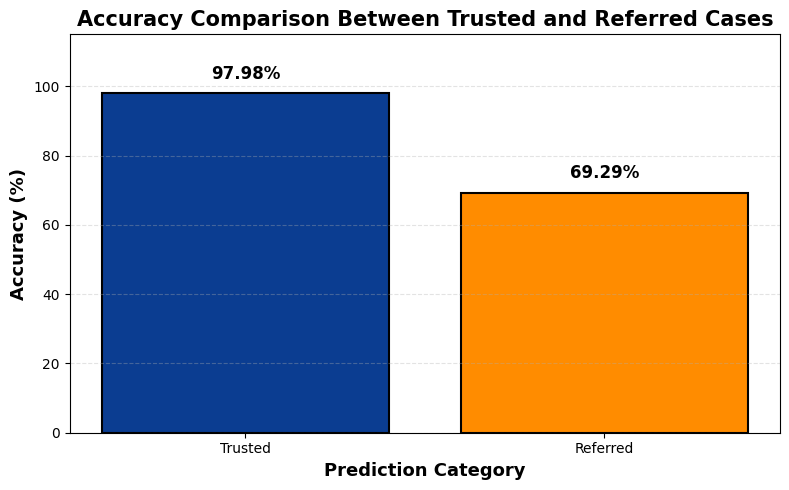

Saved: trust_based_referral_accuracy_final.png


In [ ]:
# =========================================================
# TRUSTED vs REFERRED ACCURACY (FINAL JOURNAL VERSION)
# =========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

labels = [
    "Trusted",
    "Referred"
]

values = [
    97.98,
    69.29
]

# DARK BLUE + DARK ORANGE

colors = [
    "#0B3D91",   # Dark Blue
    "#FF8C00"    # Dark Orange
]

bars = plt.bar(

    labels,

    values,

    color=colors,

    edgecolor="black",

    linewidth=1.5

)

# VALUE LABELS ABOVE BARS

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x() + bar.get_width()/2,

        height + 3,      # <- bar থেকে একটু উপরে

        f"{height:.2f}%",

        ha="center",

        va="bottom",

        fontsize=12,

        fontweight="bold"

    )

plt.ylabel(
    "Accuracy (%)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel(
    "Prediction Category",
    fontsize=13,
    fontweight="bold"
)

plt.title(
    "Accuracy Comparison Between Trusted and Referred Cases",
    fontsize=15,
    fontweight="bold"
)

plt.ylim(0,115)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/trust_based_referral_accuracy_final.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved: trust_based_referral_accuracy_final.png")

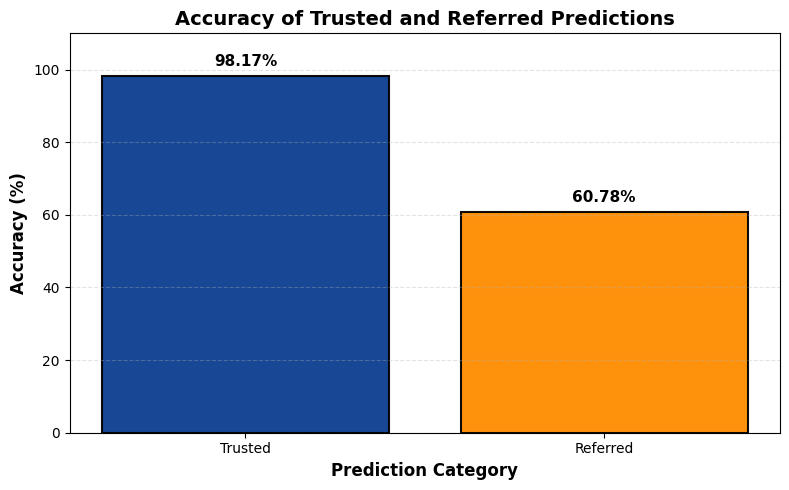

Saved: trusted_vs_referred_accuracy_journal.png


In [ ]:
# =========================================================
# TRUSTED VS UNTRUSTED ACCURACY
# JOURNAL VERSION
# =========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

labels = [
    "Trusted",
    "Referred"
]

values = [
    trusted_accuracy * 100,
    untrusted_accuracy * 100
]

# DARK BLUE + PREMIUM ORANGE

colors = [
    "#0B3D91",   # Dark Blue
    "#FF8C00"    # Dark Orange
]

bars = plt.bar(

    labels,

    values,

    color=colors,

    edgecolor="black",

    linewidth=1.5,

    alpha=0.95

)

# VALUE LABELS

for bar in bars:

    h = bar.get_height()

    plt.text(

        bar.get_x() + bar.get_width()/2,

        h + 2,

        f"{h:.2f}%",

        ha="center",

        va="bottom",

        fontsize=11,

        fontweight="bold"

    )

plt.ylabel(
    "Accuracy (%)",
    fontsize=12,
    fontweight="bold"
)

plt.xlabel(
    "Prediction Category",
    fontsize=12,
    fontweight="bold"
)

plt.title(
    "Accuracy of Trusted and Referred Predictions",
    fontsize=14,
    fontweight="bold"
)

plt.ylim(0,110)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/trusted_vs_referred_accuracy_journal.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved: trusted_vs_referred_accuracy_journal.png")

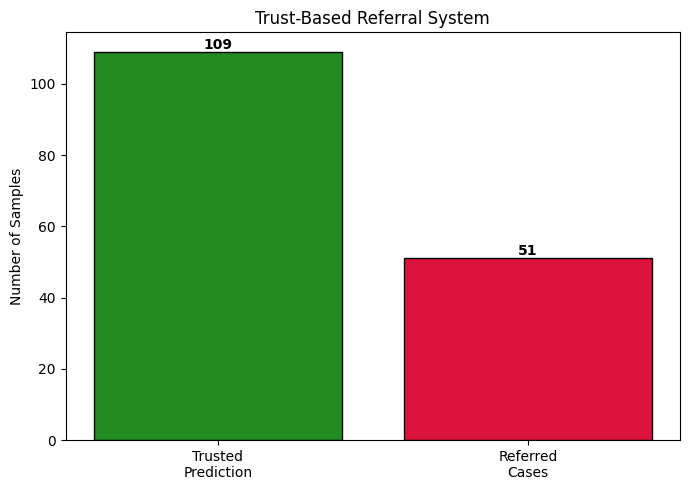

In [ ]:
import matplotlib.pyplot as plt

labels = [
    "Trusted\nPrediction",
    "Referred\nCases"
]

values = [
    trusted_samples,
    untrusted_samples
]

colors = [
    "forestgreen",
    "crimson"
]

plt.figure(figsize=(7,5))

bars = plt.bar(
    labels,
    values,
    color=colors,
    edgecolor="black"
)

for bar in bars:

    h = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        h,
        str(int(h)),
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.ylabel("Number of Samples")

plt.title(
    "Trust-Based Referral System"
)

plt.tight_layout()

plt.show()

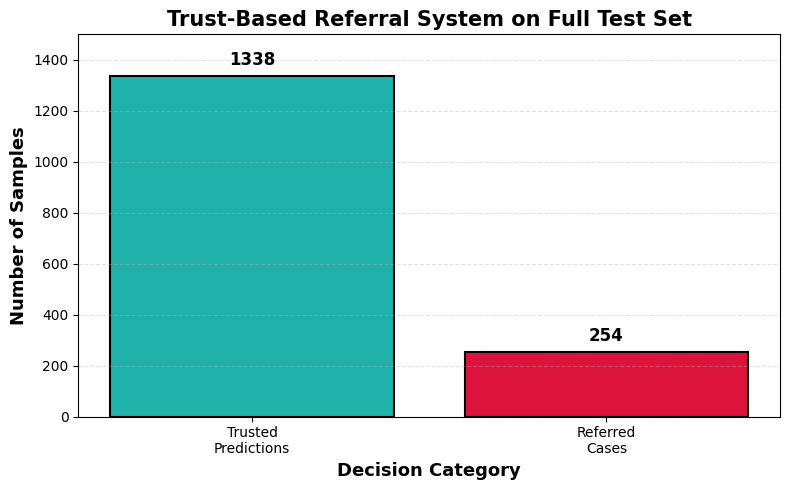

Saved: trust_based_referral_full_testset.png


In [ ]:
# =========================================================
# TRUST-BASED REFERRAL SYSTEM
# FULL TEST SET VERSION
# =========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

labels = [
    "Trusted\nPredictions",
    "Referred\nCases"
]

values = [
    1338,
    254
]

colors = [
    "#20B2AA",   # Teal
    "#DC143C"    # Crimson

]

bars = plt.bar(

    labels,

    values,

    color=colors,

    edgecolor="black",

    linewidth=1.5

)

# VALUE LABELS

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x() + bar.get_width()/2,

        height + 25,

        f"{int(height)}",

        ha="center",

        va="bottom",

        fontsize=12,

        fontweight="bold"

    )

plt.ylabel(
    "Number of Samples",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel(
    "Decision Category",
    fontsize=13,
    fontweight="bold"
)

plt.title(
    "Trust-Based Referral System on Full Test Set",
    fontsize=15,
    fontweight="bold"
)

plt.ylim(0, 1500)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/trust_based_referral_full_testset.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("Saved: trust_based_referral_full_testset.png")

Device: cuda

Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 135MB/s]



Epoch 1/10


Loss: 0.9951 | Acc: 68.67%: 100%|██████████| 640/640 [45:47<00:00,  4.29s/it]



Train Loss : 0.7670
Train Acc  : 68.67%
Val Loss   : 0.5090
Val Acc    : 80.66%
Val Precision : 0.8094
Val Recall    : 0.8066
Val F1        : 0.8044

Best ResNet50 Model Saved!

Epoch 2/10


...


Train Loss : 0.1956
Train Acc  : 92.69%
Val Loss   : 0.2498
Val Acc    : 90.68%
Val Precision : 0.9096
Val Recall    : 0.9068
Val F1        : 0.9063

Best ResNet50 Model Saved!

Epoch 9/10


Loss: 0.0526 | Acc: 92.73%: 100%|██████████| 640/640 [02:58<00:00,  3.58it/s]



Train Loss : 0.1915
Train Acc  : 92.73%
Val Loss   : 0.2818
Val Acc    : 89.53%
Val Precision : 0.8992
Val Recall    : 0.8953
Val F1        : 0.8952

Epoch 10/10


Loss: 0.3667 | Acc: 93.28%: 100%|██████████| 640/640 [02:54<00:00,  3.66it/s]



Train Loss : 0.1709
Train Acc  : 93.28%
Val Loss   : 0.2998
Val Acc    : 89.91%
Val Precision : 0.8994
Val Recall    : 0.8991
Val F1        : 0.8992

FINAL TEST RESULTS

Accuracy  : 91.21%
Precision : 0.9150
Recall    : 0.9121
F1 Score  : 0.9116

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.92      0.82      0.87       421
      normal       0.97      0.88      0.92       163
        osmf       0.94      0.97      0.96       328
      pdoscc       0.96      0.96      0.96       247
      wdoscc       0.84      0.94      0.89       433

    accuracy                           0.91      1592
   macro avg       0.93      0.91      0.92      1592
weighted avg       0.92      0.91      0.91      1592



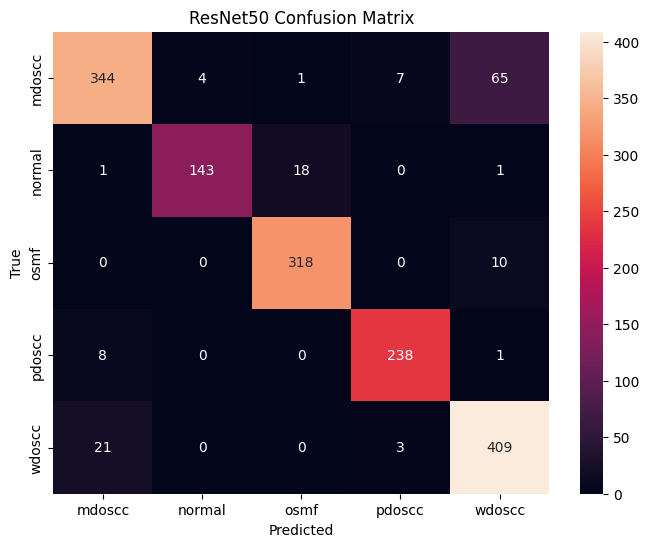

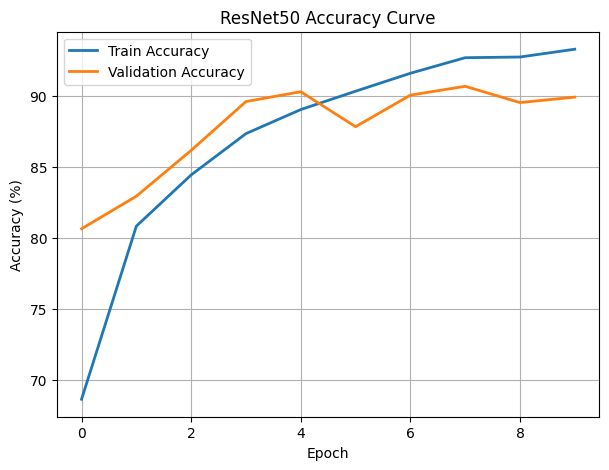

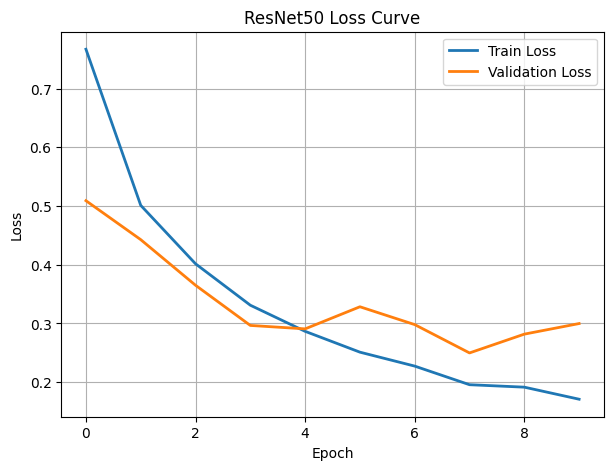

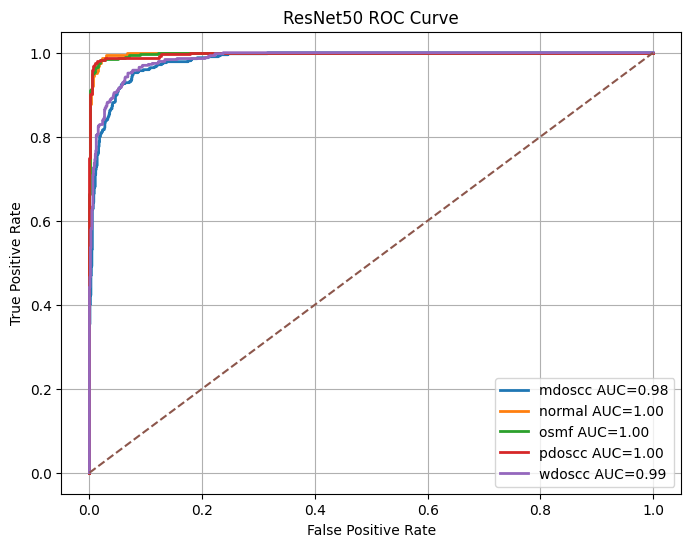

In [ ]:
# =========================================================
# RESNET50 BASELINE
# FULL EXPERIMENT PIPELINE
# =========================================================

# =========================================================
# INSTALLS
# =========================================================

# !pip install timm

# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms,
    models
)

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# =========================================================
# PATHS
# =========================================================

train_dir = "/content/drive/MyDrive/ORCHID_224_JPG"

val_dir = "/content/drive/MyDrive/val"

test_dir = "/content/drive/MyDrive/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224

BATCH_SIZE = 16

EPOCHS = 10

LR = 1e-4

NUM_CLASSES = 5

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# =========================================================
# CLASS NAMES
# =========================================================

class_names = train_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# MODEL
# =========================================================

model = models.resnet50(
    weights="IMAGENET1K_V1"
)

model.fc = nn.Linear(
    model.fc.in_features,
    NUM_CLASSES
)

model = model.to(device)

# =========================================================
# LOSS & OPTIMIZER
# =========================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    loop = tqdm(loader)

    for images, labels in loop:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        acc = 100 * correct / total

        loop.set_description(
            f"Loss: {loss.item():.4f} | Acc: {acc:.2f}%"
        )

    return running_loss / len(loader), acc

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(model, loader):

    model.eval()

    running_loss = 0

    all_labels = []

    all_preds = []

    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(outputs, 1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)
    )

# =========================================================
# STORAGE
# =========================================================

train_losses = []

val_losses = []

train_accs = []

val_accs = []

best_val_acc = 0

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    print("\n===================================")

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print("===================================")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accs.append(train_acc)

    val_accs.append(val_acc * 100)

    print(f"\nTrain Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"Val Precision : {val_precision:.4f}")

    print(f"Val Recall    : {val_recall:.4f}")

    print(f"Val F1        : {val_f1:.4f}")

    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(

            model.state_dict(),

            "/content/drive/MyDrive/resnet50_best.pth"
        )

        print("\nBest ResNet50 Model Saved!")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(

    torch.load(
        "/content/drive/MyDrive/resnet50_best.pth"
    )
)

# =========================================================
# TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob

) = evaluate(
    model,
    test_loader
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================")

print("FINAL TEST RESULTS")

print("===================================\n")

print(f"Accuracy  : {test_acc*100:.2f}%")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")

print("CLASSIFICATION REPORT")

print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("ResNet50 Confusion Matrix")

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    linewidth=2,
    label='Train Accuracy'
)

plt.plot(
    val_accs,
    linewidth=2,
    label='Validation Accuracy'
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("ResNet50 Accuracy Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    linewidth=2,
    label='Train Loss'
)

plt.plot(
    val_losses,
    linewidth=2,
    label='Validation Loss'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("ResNet50 Loss Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(
    y_true,
    classes=[0,1,2,3,4]
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} AUC={roc_auc:.2f}"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ResNet50 ROC Curve")

plt.legend()

plt.grid()

plt.show()

Tesla T4
Device: cuda


/tmp/ipykernel_663/2488933648.py:235: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']

Epoch 1/10


  0%|          | 0/320 [00:00<?, ?it/s]/tmp/ipykernel_663/2488933648.py:265: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 0.3152 | Acc: 70.88%: 100%|██████████| 320/320 [01:49<00:00,  2.91it/s]
/tmp/ipykernel_663/2488933648.py:317: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 0.7217
Train Acc  : 70.88%
Val Loss   : 0.4332
Val Acc    : 82.15%
Val Precision : 0.8260
Val Recall    : 0.8215
Val F1        : 0.8194

Best DenseNet121 Model Saved!

Epoch 2/10


...


Train Loss : 0.0804
Train Acc  : 96.93%
Val Loss   : 0.1651
Val Acc    : 93.38%
Val Precision : 0.9336
Val Recall    : 0.9338
Val F1        : 0.9336

Best DenseNet121 Model Saved!

Epoch 10/10


  0%|          | 0/320 [00:00<?, ?it/s]/tmp/ipykernel_663/2488933648.py:265: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 0.3233 | Acc: 96.72%: 100%|██████████| 320/320 [00:59<00:00,  5.38it/s]
/tmp/ipykernel_663/2488933648.py:317: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 0.0859
Train Acc  : 96.72%
Val Loss   : 0.1485
Val Acc    : 94.11%
Val Precision : 0.9412
Val Recall    : 0.9411
Val F1        : 0.9410

Best DenseNet121 Model Saved!


/tmp/ipykernel_663/2488933648.py:317: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



FINAL TEST RESULTS

Accuracy  : 93.22%
Precision : 0.9323
Recall    : 0.9322
F1 Score  : 0.9320

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.91      0.89      0.90       421
      normal       0.95      0.98      0.96       163
        osmf       1.00      0.97      0.98       328
      pdoscc       0.92      0.98      0.95       247
      wdoscc       0.91      0.90      0.90       433

    accuracy                           0.93      1592
   macro avg       0.94      0.94      0.94      1592
weighted avg       0.93      0.93      0.93      1592



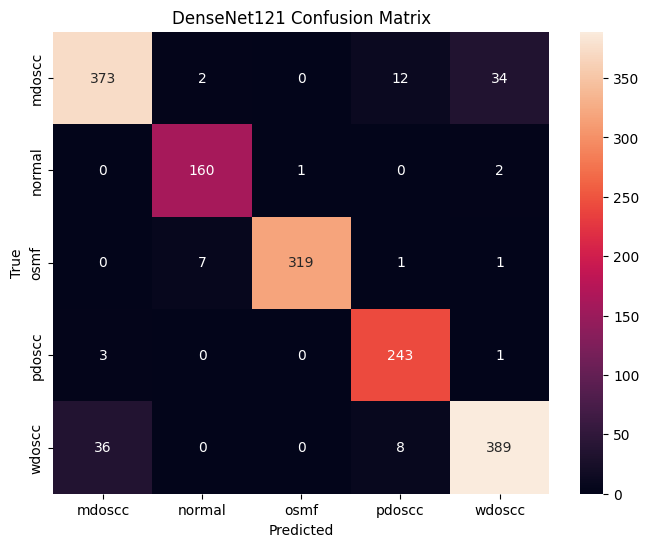

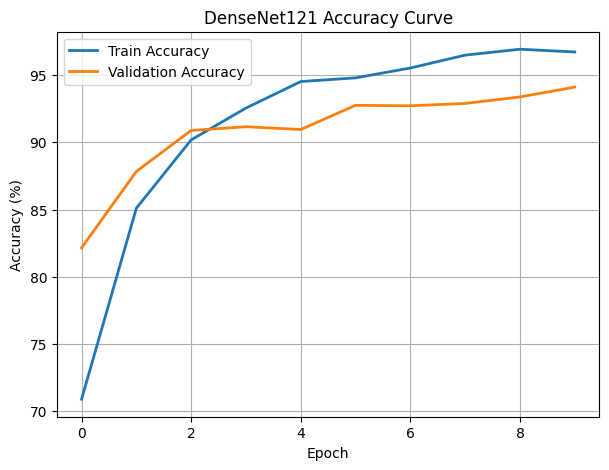

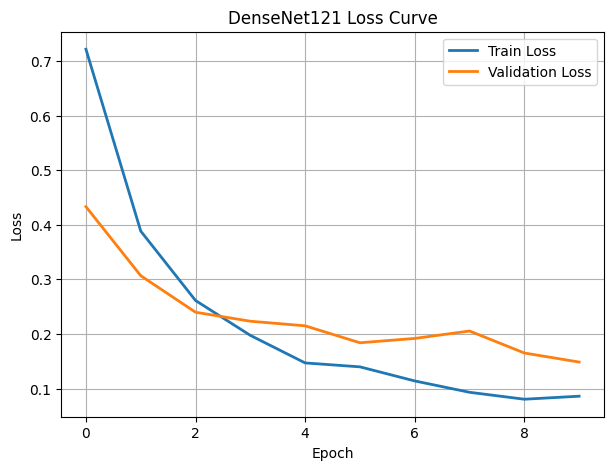

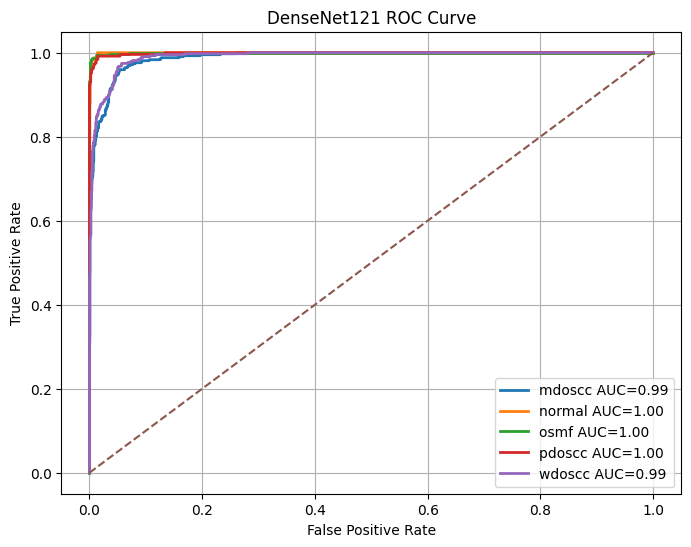

In [ ]:
# =========================================================
# FAST DENSENET121 BASELINE
# GPU OPTIMIZED VERSION
# =========================================================

# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms,
    models
)

from torch.cuda.amp import (
    autocast,
    GradScaler
)

# =========================================================
# GPU SPEED BOOST
# =========================================================

torch.backends.cudnn.benchmark = True

# =========================================================
# CHECK GPU
# =========================================================

print(torch.cuda.get_device_name(0))

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# =========================================================
# COPY DATASET TO LOCAL RUNTIME
# MUCH FASTER THAN GOOGLE DRIVE
# =========================================================

!cp -r /content/drive/MyDrive/ORCHID_224_JPG /content/
!cp -r /content/drive/MyDrive/val /content/
!cp -r /content/drive/MyDrive/test /content/

# =========================================================
# PATHS
# =========================================================

train_dir = "/content/ORCHID_224_JPG"

val_dir = "/content/val"

test_dir = "/content/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224

BATCH_SIZE = 32

EPOCHS = 10

LR = 1e-4

NUM_CLASSES = 5

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

# =========================================================
# CLASS NAMES
# =========================================================

class_names = train_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# MODEL
# =========================================================

model = models.densenet121(
    weights="IMAGENET1K_V1"
)

model.classifier = nn.Linear(
    model.classifier.in_features,
    NUM_CLASSES
)

model = model.to(device)

# =========================================================
# LOSS & OPTIMIZER
# =========================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)

# =========================================================
# MIXED PRECISION
# =========================================================

scaler = GradScaler()

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    loop = tqdm(loader)

    for images, labels in loop:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        # =============================================
        # MIXED PRECISION
        # =============================================

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        acc = 100 * correct / total

        loop.set_description(
            f"Loss: {loss.item():.4f} | Acc: {acc:.2f}%"
        )

    return running_loss / len(loader), acc

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(model, loader):

    model.eval()

    running_loss = 0

    all_labels = []

    all_preds = []

    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            with autocast():

                outputs = model(images)

                loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(outputs, 1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)
    )

# =========================================================
# STORAGE
# =========================================================

train_losses = []

val_losses = []

train_accs = []

val_accs = []

best_val_acc = 0

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    print("\n===================================")

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print("===================================")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accs.append(train_acc)

    val_accs.append(val_acc * 100)

    print(f"\nTrain Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"Val Precision : {val_precision:.4f}")

    print(f"Val Recall    : {val_recall:.4f}")

    print(f"Val F1        : {val_f1:.4f}")

    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(

            model.state_dict(),

            "/content/drive/MyDrive/densenet121_best.pth"
        )

        print("\nBest DenseNet121 Model Saved!")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(

    torch.load(
        "/content/drive/MyDrive/densenet121_best.pth"
    )
)

# =========================================================
# TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob

) = evaluate(
    model,
    test_loader
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================")

print("FINAL TEST RESULTS")

print("===================================\n")

print(f"Accuracy  : {test_acc*100:.2f}%")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")

print("CLASSIFICATION REPORT")

print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("DenseNet121 Confusion Matrix")

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    linewidth=2,
    label='Train Accuracy'
)

plt.plot(
    val_accs,
    linewidth=2,
    label='Validation Accuracy'
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("DenseNet121 Accuracy Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    linewidth=2,
    label='Train Loss'
)

plt.plot(
    val_losses,
    linewidth=2,
    label='Validation Loss'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("DenseNet121 Loss Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(
    y_true,
    classes=[0,1,2,3,4]
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} AUC={roc_auc:.2f}"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("DenseNet121 ROC Curve")

plt.legend()

plt.grid()

plt.show()

CUDA Available: True
GPU: Tesla T4


/tmp/ipykernel_663/2079700.py:253: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Train Images: 10227
Validation Images: 2885
Test Images: 1592

Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']

Epoch 1/10


  0%|          | 0/320 [00:00<?, ?it/s]/tmp/ipykernel_663/2079700.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 1.0329 | Acc: 51.61%: 100%|██████████| 320/320 [00:59<00:00,  5.39it/s]
/tmp/ipykernel_663/2079700.py:331: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 1.1227
Train Acc  : 51.61%
Val Loss   : 0.8914
Val Acc    : 62.29%
Val Precision : 0.6307
Val Recall    : 0.6229
Val F1        : 0.6221

Best MobileNetV3 Model Saved!

Epoch 2/10


...


Train Loss : 0.2146
Train Acc  : 92.10%
Val Loss   : 0.5257
Val Acc    : 81.35%
Val Precision : 0.8221
Val Recall    : 0.8135
Val F1        : 0.8151

Epoch 10/10


  0%|          | 0/320 [00:00<?, ?it/s]/tmp/ipykernel_663/2079700.py:279: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 0.2923 | Acc: 93.17%: 100%|██████████| 320/320 [00:26<00:00, 12.09it/s]
/tmp/ipykernel_663/2079700.py:331: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 0.1828
Train Acc  : 93.17%
Val Loss   : 0.5225
Val Acc    : 82.05%
Val Precision : 0.8197
Val Recall    : 0.8205
Val F1        : 0.8193

Best MobileNetV3 Model Saved!


/tmp/ipykernel_663/2079700.py:331: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



FINAL TEST RESULTS

Accuracy  : 80.84%
Precision : 0.8095
Recall    : 0.8084
F1 Score  : 0.8070

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.75      0.65      0.70       421
      normal       0.92      0.90      0.91       163
        osmf       0.92      0.95      0.94       328
      pdoscc       0.85      0.82      0.83       247
      wdoscc       0.72      0.81      0.76       433

    accuracy                           0.81      1592
   macro avg       0.83      0.83      0.83      1592
weighted avg       0.81      0.81      0.81      1592



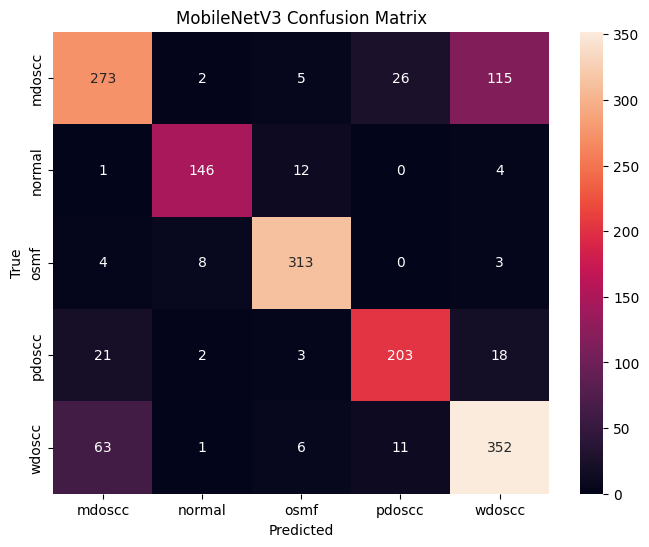

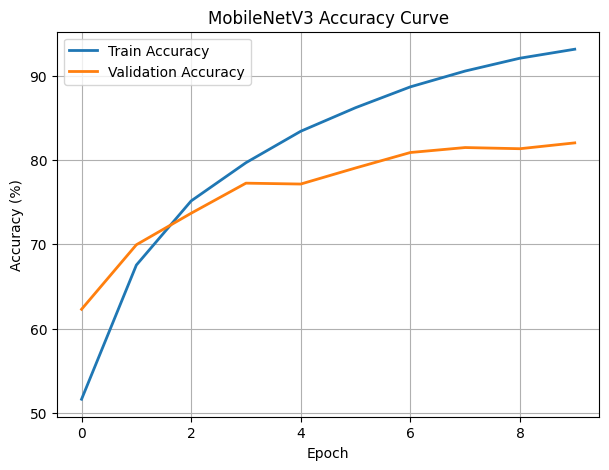

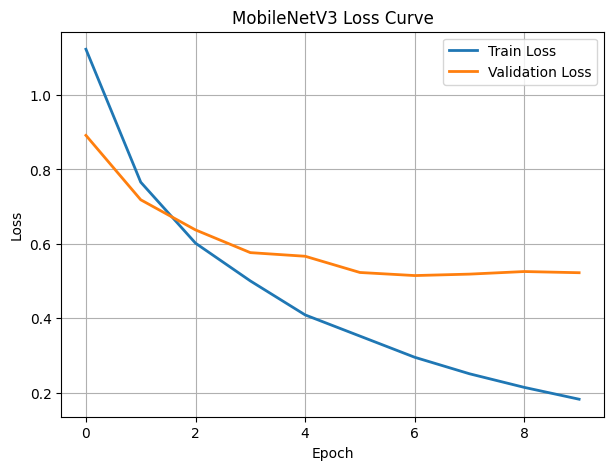

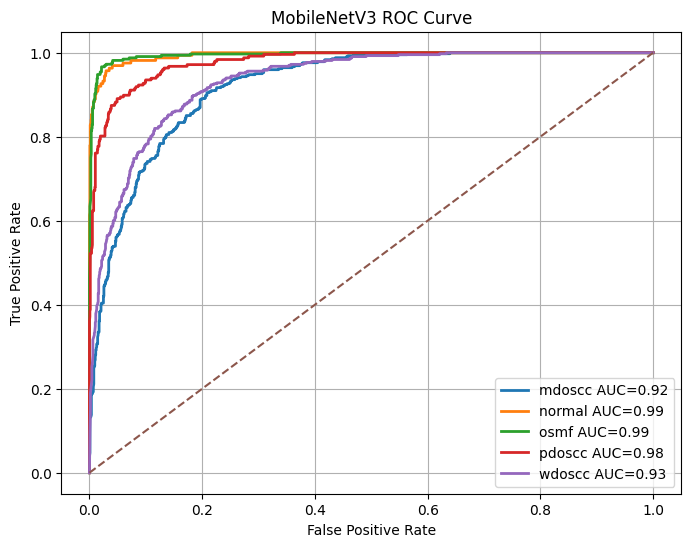

In [ ]:
# =========================================================
# FULL MOBILENETV3 TRAINING
# ALL EPOCHS FULL RUN VERSION
# FAST + GPU OPTIMIZED
# =========================================================

# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms,
    models
)

from torch.cuda.amp import (
    autocast,
    GradScaler
)

# =========================================================
# GPU CHECK
# =========================================================

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

else:

    print("GPU NOT DETECTED")

# =========================================================
# GPU BOOST
# =========================================================

torch.backends.cudnn.benchmark = True

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# =========================================================
# COPY DATASET TO LOCAL
# =========================================================

!cp -r /content/drive/MyDrive/ORCHID_224_JPG /content/
!cp -r /content/drive/MyDrive/val /content/
!cp -r /content/drive/MyDrive/test /content/

# =========================================================
# PATHS
# =========================================================

train_dir = "/content/ORCHID_224_JPG"

val_dir = "/content/val"

test_dir = "/content/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 128

BATCH_SIZE = 32

EPOCHS = 10

LR = 1e-4

NUM_CLASSES = 5

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_test_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# DATASET INFO
# =========================================================

print("\nTrain Images:", len(train_dataset))

print("Validation Images:", len(val_dataset))

print("Test Images:", len(test_dataset))

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

# =========================================================
# CLASS NAMES
# =========================================================

class_names = train_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# MODEL
# =========================================================

model = models.mobilenet_v3_small(
    weights="IMAGENET1K_V1"
)

model.classifier[3] = nn.Linear(
    model.classifier[3].in_features,
    NUM_CLASSES
)

model = model.to(device)

# =========================================================
# LOSS FUNCTION
# =========================================================

criterion = nn.CrossEntropyLoss()

# =========================================================
# OPTIMIZER
# =========================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)

# =========================================================
# MIXED PRECISION
# =========================================================

scaler = GradScaler()

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    loop = tqdm(loader)

    for images, labels in loop:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        acc = 100 * correct / total

        loop.set_description(
            f"Loss: {loss.item():.4f} | Acc: {acc:.2f}%"
        )

    return running_loss / len(loader), acc

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(model, loader):

    model.eval()

    running_loss = 0

    all_labels = []

    all_preds = []

    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            with autocast():

                outputs = model(images)

                loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(outputs, 1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)
    )

# =========================================================
# STORAGE
# =========================================================

train_losses = []

val_losses = []

train_accs = []

val_accs = []

best_val_acc = 0

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    print("\n===================================")

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print("===================================")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accs.append(train_acc)

    val_accs.append(val_acc * 100)

    print(f"\nTrain Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"Val Precision : {val_precision:.4f}")

    print(f"Val Recall    : {val_recall:.4f}")

    print(f"Val F1        : {val_f1:.4f}")

    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(

            model.state_dict(),

            "/content/drive/MyDrive/mobilenetv3_best.pth"
        )

        print("\nBest MobileNetV3 Model Saved!")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(

    torch.load(
        "/content/drive/MyDrive/mobilenetv3_best.pth"
    )
)

# =========================================================
# TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob

) = evaluate(
    model,
    test_loader
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================")

print("FINAL TEST RESULTS")

print("===================================\n")

print(f"Accuracy  : {test_acc*100:.2f}%")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")

print("CLASSIFICATION REPORT")

print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("MobileNetV3 Confusion Matrix")

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    linewidth=2,
    label='Train Accuracy'
)

plt.plot(
    val_accs,
    linewidth=2,
    label='Validation Accuracy'
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("MobileNetV3 Accuracy Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    linewidth=2,
    label='Train Loss'
)

plt.plot(
    val_losses,
    linewidth=2,
    label='Validation Loss'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("MobileNetV3 Loss Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(
    y_true,
    classes=[0,1,2,3,4]
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} AUC={roc_auc:.2f}"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("MobileNetV3 ROC Curve")

plt.legend()

plt.grid()

plt.show()

CUDA Available: True
GPU: Tesla T4

Train Images: 10227
Validation Images: 2885
Test Images: 1592

Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:04<00:00, 115MB/s]
/tmp/ipykernel_663/2046380541.py:254: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Epoch 1/10


  0%|          | 0/640 [00:00<?, ?it/s]/tmp/ipykernel_663/2046380541.py:280: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 1.2113 | Acc: 46.52%: 100%|██████████| 640/640 [01:36<00:00,  6.62it/s]
/tmp/ipykernel_663/2046380541.py:332: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 1.2288
Train Acc  : 46.52%
Val Loss   : 1.3431
Val Acc    : 42.70%
Val Precision : 0.5357
Val Recall    : 0.4270
Val F1        : 0.3426

Best VGG16 Model Saved!

Epoch 2/10


...


Train Loss : 0.4004
Train Acc  : 84.23%
Val Loss   : 0.7896
Val Acc    : 77.05%
Val Precision : 0.7781
Val Recall    : 0.7705
Val F1        : 0.7656

Epoch 10/10


  0%|          | 0/640 [00:00<?, ?it/s]/tmp/ipykernel_663/2046380541.py:280: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 0.0363 | Acc: 84.58%: 100%|██████████| 640/640 [01:02<00:00, 10.21it/s]
/tmp/ipykernel_663/2046380541.py:332: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 0.3938
Train Acc  : 84.58%
Val Loss   : 0.4627
Val Acc    : 84.47%
Val Precision : 0.8486
Val Recall    : 0.8447
Val F1        : 0.8447

Best VGG16 Model Saved!


/tmp/ipykernel_663/2046380541.py:332: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



FINAL TEST RESULTS

Accuracy  : 84.30%
Precision : 0.8496
Recall    : 0.8430
F1 Score  : 0.8439

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.73      0.85      0.79       421
      normal       0.95      0.87      0.91       163
        osmf       0.94      0.95      0.95       328
      pdoscc       0.92      0.82      0.87       247
      wdoscc       0.82      0.75      0.79       433

    accuracy                           0.84      1592
   macro avg       0.87      0.85      0.86      1592
weighted avg       0.85      0.84      0.84      1592



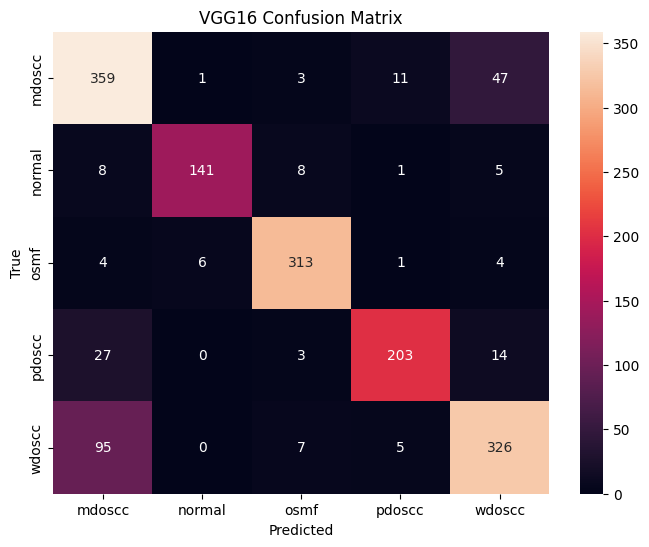

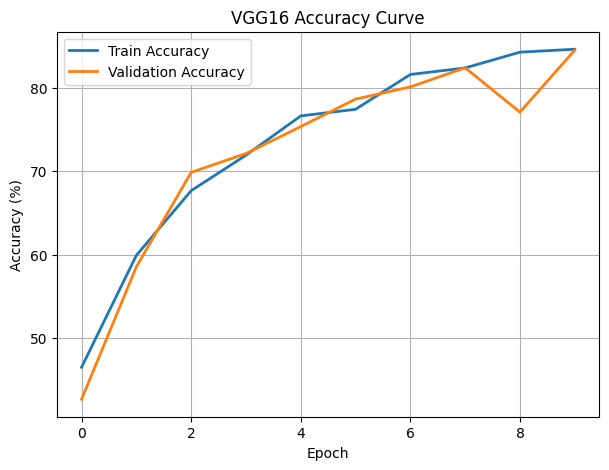

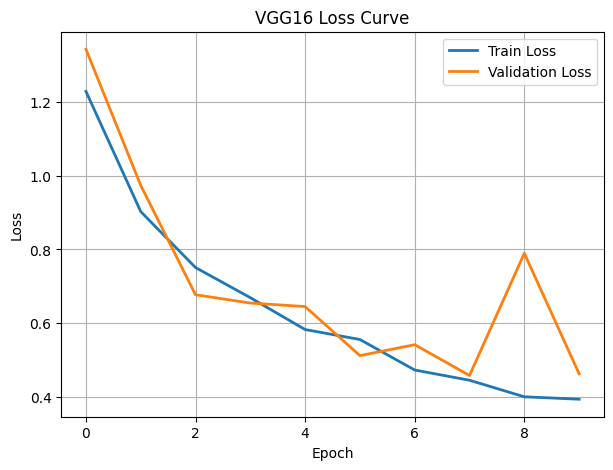

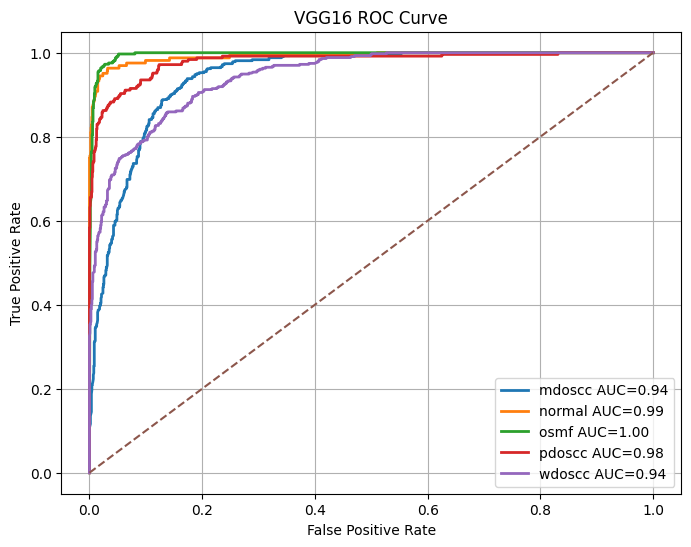

In [ ]:
# =========================================================
# VGG16 BASELINE
# FULL GPU OPTIMIZED VERSION
# =========================================================

# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms,
    models
)

from torch.cuda.amp import (
    autocast,
    GradScaler
)

# =========================================================
# GPU CHECK
# =========================================================

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

else:

    print("GPU NOT DETECTED")

# =========================================================
# GPU BOOST
# =========================================================

torch.backends.cudnn.benchmark = True

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# =========================================================
# COPY DATASET TO LOCAL
# =========================================================

!cp -r /content/drive/MyDrive/ORCHID_224_JPG /content/
!cp -r /content/drive/MyDrive/val /content/
!cp -r /content/drive/MyDrive/test /content/

# =========================================================
# PATHS
# =========================================================

train_dir = "/content/ORCHID_224_JPG"

val_dir = "/content/val"

test_dir = "/content/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 128

BATCH_SIZE = 16

EPOCHS = 10

LR = 1e-4

NUM_CLASSES = 5

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_test_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# DATASET INFO
# =========================================================

print("\nTrain Images:", len(train_dataset))

print("Validation Images:", len(val_dataset))

print("Test Images:", len(test_dataset))

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

# =========================================================
# CLASS NAMES
# =========================================================

class_names = train_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# MODEL
# =========================================================

model = models.vgg16(
    weights="IMAGENET1K_V1"
)

model.classifier[6] = nn.Linear(
    model.classifier[6].in_features,
    NUM_CLASSES
)

model = model.to(device)

# =========================================================
# LOSS FUNCTION
# =========================================================

criterion = nn.CrossEntropyLoss()

# =========================================================
# OPTIMIZER
# =========================================================

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)

# =========================================================
# MIXED PRECISION
# =========================================================

scaler = GradScaler()

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    loop = tqdm(loader)

    for images, labels in loop:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        acc = 100 * correct / total

        loop.set_description(
            f"Loss: {loss.item():.4f} | Acc: {acc:.2f}%"
        )

    return running_loss / len(loader), acc

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(model, loader):

    model.eval()

    running_loss = 0

    all_labels = []

    all_preds = []

    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            with autocast():

                outputs = model(images)

                loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(outputs, 1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)
    )

# =========================================================
# STORAGE
# =========================================================

train_losses = []

val_losses = []

train_accs = []

val_accs = []

best_val_acc = 0

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    print("\n===================================")

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print("===================================")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accs.append(train_acc)

    val_accs.append(val_acc * 100)

    print(f"\nTrain Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"Val Precision : {val_precision:.4f}")

    print(f"Val Recall    : {val_recall:.4f}")

    print(f"Val F1        : {val_f1:.4f}")

    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(

            model.state_dict(),

            "/content/drive/MyDrive/vgg16_best.pth"
        )

        print("\nBest VGG16 Model Saved!")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(

    torch.load(
        "/content/drive/MyDrive/vgg16_best.pth"
    )
)

# =========================================================
# TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob

) = evaluate(
    model,
    test_loader
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================")

print("FINAL TEST RESULTS")

print("===================================\n")

print(f"Accuracy  : {test_acc*100:.2f}%")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")

print("CLASSIFICATION REPORT")

print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("VGG16 Confusion Matrix")

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    linewidth=2,
    label='Train Accuracy'
)

plt.plot(
    val_accs,
    linewidth=2,
    label='Validation Accuracy'
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("VGG16 Accuracy Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    linewidth=2,
    label='Train Loss'
)

plt.plot(
    val_losses,
    linewidth=2,
    label='Validation Loss'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("VGG16 Loss Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(
    y_true,
    classes=[0,1,2,3,4]
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} AUC={roc_auc:.2f}"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("VGG16 ROC Curve")

plt.legend()

plt.grid()

plt.show()

In [ ]:
import torch

checkpoint = torch.load(
    "/content/drive/MyDrive/final_proposed_model.pth",
    map_location="cpu"
)

print(checkpoint.keys())

odict_keys(['backbone.conv_stem.weight', 'backbone.bn1.weight', 'backbone.bn1.bias', 'backbone.bn1.running_mean', 'backbone.bn1.running_var', 'backbone.bn1.num_batches_tracked', 'backbone.blocks.0.0.conv_dw.weight', 'backbone.blocks.0.0.bn1.weight', 'backbone.blocks.0.0.bn1.bias', 'backbone.blocks.0.0.bn1.running_mean', 'backbone.blocks.0.0.bn1.running_var', 'backbone.blocks.0.0.bn1.num_batches_tracked', 'backbone.blocks.0.0.se.conv_reduce.weight', 'backbone.blocks.0.0.se.conv_reduce.bias', 'backbone.blocks.0.0.se.conv_expand.weight', 'backbone.blocks.0.0.se.conv_expand.bias', 'backbone.blocks.0.0.conv_pw.weight', 'backbone.blocks.0.0.bn2.weight', 'backbone.blocks.0.0.bn2.bias', 'backbone.blocks.0.0.bn2.running_mean', 'backbone.blocks.0.0.bn2.running_var', 'backbone.blocks.0.0.bn2.num_batches_tracked', 'backbone.blocks.0.1.conv_dw.weight', 'backbone.blocks.0.1.bn1.weight', 'backbone.blocks.0.1.bn1.bias', 'backbone.blocks.0.1.bn1.running_mean', 'backbone.blocks.0.1.bn1.running_var', 'ba

In [ ]:
import torch

print(torch.__version__)

2.11.0+cu128


In [ ]:
# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset

from torchvision import datasets, transforms

import timm

from sklearn.model_selection import train_test_split, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# =========================================================
# PATHS
# =========================================================

DATA_DIR = "/content/drive/MyDrive/ORCHID_224_JPG"

TEST_DIR = "/content/drive/MyDrive/test/test"

SAVE_PATH = "/content/drive/MyDrive/efficientnetb3_best.pth"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224

BATCH_SIZE = 16

EPOCHS = 30

NUM_CLASSES = 5

LR = 1e-4

# =========================================================
# TRANSFORMS
# =========================================================

train_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
])

test_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])

# =========================================================
# DATASET
# =========================================================

full_ds = datasets.ImageFolder(
    DATA_DIR,
    transform=train_tf
)

labels = full_ds.targets

class_names = full_ds.classes

print(class_names)

# =========================================================
# TRAIN VAL SPLIT
# =========================================================

train_idx, val_idx = train_test_split(
    np.arange(len(labels)),
    test_size=0.2,
    stratify=labels,
    random_state=42
)

train_ds = Subset(
    full_ds,
    train_idx
)

val_ds = Subset(
    full_ds,
    val_idx
)

test_ds = datasets.ImageFolder(
    TEST_DIR,
    transform=test_tf
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Device: cuda
['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


In [ ]:
# =========================================================
# MODEL
# =========================================================

def get_model():

    model = timm.create_model(
        "efficientnet_b3",
        pretrained=True,
        num_classes=NUM_CLASSES
    )

    return model.to(device)

model = get_model()

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)

# =========================================================
# EVALUATION
# =========================================================

def evaluate(loader):

    model.eval()

    all_labels = []
    all_preds = []
    all_probs = []

    running_loss = 0

    with torch.no_grad():

        for imgs, lbls in loader:

            imgs = imgs.to(device)
            lbls = lbls.to(device)

            outputs = model(imgs)

            loss = criterion(
                outputs,
                lbls
            )

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(
                outputs,
                1
            )

            all_labels.extend(
                lbls.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    return (
        running_loss / len(loader),
        acc,
        np.array(all_labels),
        np.array(all_preds),
        np.array(all_probs)
    )

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

In [ ]:
print("model" in globals())

True


In [ ]:
print("EPOCHS" in globals())
print("model" in globals())
print("train_loader" in globals())
print("criterion" in globals())
print("SAVE_PATH" in globals())

True
True
True
True
True


In [ ]:
# =========================================================
# TRAINING
# =========================================================

best_acc = 0

train_loss_hist = []
val_loss_hist = []

train_acc_hist = []
val_acc_hist = []

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0

    correct = 0
    total = 0

    loop = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for imgs, lbls in loop:

        imgs = imgs.to(device)
        lbls = lbls.to(device)

        optimizer.zero_grad()

        outputs = model(imgs)

        loss = criterion(outputs, lbls)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == lbls).sum().item()

        total += lbls.size(0)

    train_loss = running_loss / len(train_loader)

    train_acc = correct / total

    val_loss, val_acc, _, _, _ = evaluate(
        val_loader
    )

    train_loss_hist.append(train_loss)
    val_loss_hist.append(val_loss)

    train_acc_hist.append(train_acc)
    val_acc_hist.append(val_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Acc={train_acc:.4f} | "
        f"Val Acc={val_acc:.4f}"
    )

    if val_acc > best_acc:

        best_acc = val_acc

        torch.save(
            model.state_dict(),
            SAVE_PATH
        )

        print("Best Model Saved")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(
    torch.load(
        SAVE_PATH,
        map_location=device
    )
)

# =========================================================
# FINAL TEST
# =========================================================

test_loss, test_acc, y_true, y_pred, y_prob = evaluate(
    test_loader
)

print("\n===================================")
print("FINAL TEST RESULTS")
print("===================================\n")

print(f"Test Accuracy : {test_acc:.4f}")

# =========================================================
# SAVE TRAINING HISTORY
# =========================================================

import pandas as pd

history_df = pd.DataFrame({

    "Epoch": range(
        1,
        len(train_acc_hist)+1
    ),

    "Train_Acc": train_acc_hist,

    "Val_Acc": val_acc_hist,

    "Train_Loss": train_loss_hist,

    "Val_Loss": val_loss_hist

})

history_df.to_csv(

    "/content/drive/MyDrive/efficientnetb3_training_history.csv",

    index=False

)

# =========================================================
# 5 FOLD CROSS VALIDATION
# =========================================================

print("\n===================================")
print("5-FOLD CROSS VALIDATION")
print("===================================\n")

skf = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)

fold_accs = []

for fold, (tr_idx, vl_idx) in enumerate(

    skf.split(
        np.zeros(len(labels)),
        labels
    )

):

    print(f"\n===== Fold {fold+1} =====")

    tr_ds = Subset(
        full_ds,
        tr_idx
    )

    vl_ds = Subset(
        full_ds,
        vl_idx
    )

    tr_loader = DataLoader(
        tr_ds,
        batch_size=16,
        shuffle=True
    )

    vl_loader = DataLoader(
        vl_ds,
        batch_size=16,
        shuffle=False
    )

    model = get_model()

    optimizer = optim.Adam(
        model.parameters(),
        lr=1e-4
    )

    for ep in range(5):

        model.train()

        for imgs, lbls in tr_loader:

            imgs = imgs.to(device)
            lbls = lbls.to(device)

            outputs = model(imgs)

            loss = criterion(
                outputs,
                lbls
            )

            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

    _, acc, _, _, _ = evaluate(
        vl_loader
    )

    fold_accs.append(acc)

    print(
        f"Fold Accuracy: {acc:.4f}"
    )

# =========================================================
# SAVE CV RESULTS
# =========================================================

cv_df = pd.DataFrame({

    "Fold": [1,2,3,4,5],

    "Accuracy": fold_accs

})

cv_df.to_csv(

    "/content/drive/MyDrive/efficientnetb3_5fold_results.csv",

    index=False

)

# =========================================================
# FINAL SUMMARY
# =========================================================

print("\n===================================")
print("FINAL SUMMARY")
print("===================================\n")

print(
    f"Best Validation Accuracy : {best_acc:.4f}"
)

print(
    f"Test Accuracy            : {test_acc:.4f}"
)

print(
    f"Mean CV Accuracy         : {np.mean(fold_accs):.4f}"
)

print(
    f"CV Std Accuracy          : {np.std(fold_accs):.4f}"
)

print("\nModel Saved At:")
print(SAVE_PATH)

Epoch 1/30:  91%|█████████ | 465/512 [41:25<04:11,  5.35s/it]


KeyboardInterrupt: 

In [ ]:
!cp -r /content/drive/MyDrive/ORCHID_224_JPG /content/
!cp -r /content/drive/MyDrive/test /content/

^C
^C


In [ ]:
# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms
)

import timm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import (
    label_binarize
)

# =========================================================
# GPU CHECK
# =========================================================

print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

# =========================================================
# GPU BOOST
# =========================================================

torch.backends.cudnn.benchmark = True

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

# =========================================================
# PATHS
# =========================================================

DATA_DIR = "/content/drive/MyDrive/ORCHID_224_JPG"

VAL_DIR = "/content/drive/MyDrive/val"

TEST_DIR = "/content/drive/MyDrive/test/test"

SAVE_PATH = (
    "/content/drive/MyDrive/"
    "efficientnetb3_best.pth"
)

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 160

BATCH_SIZE = 8

EPOCHS = 25

NUM_CLASSES = 5

LR = 1e-4

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_ds = datasets.ImageFolder(
    DATA_DIR,
    transform=train_transform
)

val_ds = datasets.ImageFolder(
    VAL_DIR,
    transform=val_transform
)

test_ds = datasets.ImageFolder(
    TEST_DIR,
    transform=val_transform
)

# =========================================================
# DATASET INFO
# =========================================================

class_names = train_ds.classes

print("\nClasses:", class_names)

print("Train Images:", len(train_ds))

print("Validation Images:", len(val_ds))

print("Test Images:", len(test_ds))

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(

    train_ds,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_ds,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_ds,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

# =========================================================
# CELL 1 COMPLETE
# =========================================================

print("\nCell 1 Completed Successfully")

CUDA Available: True
GPU: Tesla T4
Device: cuda

Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
Train Images: 10227
Validation Images: 2885
Test Images: 1592

Cell 1 Completed Successfully


In [ ]:
# =========================================================
# MODEL
# =========================================================

def get_model():

    model = timm.create_model(
        "efficientnet_b3",
        pretrained=True,
        num_classes=NUM_CLASSES
    )

    return model.to(device)

# =========================================================
# MODEL INIT
# =========================================================

model = get_model()

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(
    model,
    loader,
    optimizer
):

    model.train()

    running_loss = 0

    correct = 0
    total = 0

    loop = tqdm(
        loader,
        leave=False
    )

    for imgs, lbls in loop:

        imgs = imgs.to(
            device,
            non_blocking=True
        )

        lbls = lbls.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(imgs)

        loss = criterion(
            outputs,
            lbls
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, preds = torch.max(
            outputs,
            1
        )

        correct += (
            preds == lbls
        ).sum().item()

        total += lbls.size(0)

        loop.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{100*correct/total:.2f}%"
        )

    epoch_loss = (
        running_loss / len(loader)
    )

    epoch_acc = (
        correct / total
    )

    return (
        epoch_loss,
        epoch_acc
    )

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(
    model,
    loader
):

    model.eval()

    running_loss = 0

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():

        for imgs, lbls in loader:

            imgs = imgs.to(
                device,
                non_blocking=True
            )

            lbls = lbls.to(
                device,
                non_blocking=True
            )

            outputs = model(imgs)

            loss = criterion(
                outputs,
                lbls
            )

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(
                outputs,
                1
            )

            all_labels.extend(
                lbls.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average="weighted",
        zero_division=0
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)

    )

# =========================================================
# MODEL SUMMARY
# =========================================================

print("\nModel Loaded Successfully")

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Total Parameters: {total_params:,}"
)

print(
    f"Trainable Parameters: {trainable_params:,}"
)

print("\nCell 2 Completed Successfully")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]


Model Loaded Successfully
Total Parameters: 10,703,917
Trainable Parameters: 10,703,917

Cell 2 Completed Successfully


In [ ]:
# =========================================================
# TRAINING
# =========================================================

best_acc = 0

train_loss_hist = []
val_loss_hist = []

train_acc_hist = []
val_acc_hist = []

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_loss_hist.append(
        train_loss
    )

    val_loss_hist.append(
        val_loss
    )

    train_acc_hist.append(
        train_acc
    )

    val_acc_hist.append(
        val_acc
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_acc:

        best_acc = val_acc

        torch.save(
            model.state_dict(),
            SAVE_PATH
        )

        print(
            "Best Model Saved"
        )

# =========================================================
# LOAD BEST MODEL
# =========================================================

print("\nLoading Best Model...")

model.load_state_dict(
    torch.load(
        SAVE_PATH,
        map_location=device
    )
)

model.eval()

# =========================================================
# FINAL TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob
) = evaluate(
    model,
    test_loader
)

print("\n===================================")
print("FINAL TEST RESULTS")
print("===================================\n")

print(
    f"Accuracy  : {test_acc:.4f}"
)

print(
    f"Precision : {test_precision:.4f}"
)

print(
    f"Recall    : {test_recall:.4f}"
)

print(
    f"F1 Score  : {test_f1:.4f}"
)

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")
print("CLASSIFICATION REPORT")
print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(
    figsize=(8,6)
)

sns.heatmap(

    cm,

    annot=True,

    fmt='d',

    cmap="Blues",

    xticklabels=class_names,

    yticklabels=class_names

)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "True"
)

plt.title(
    "EfficientNetB3 Confusion Matrix"
)

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(

    y_true,

    classes=range(NUM_CLASSES)

)

y_prob = np.array(
    y_prob
)

plt.figure(
    figsize=(8,6)
)

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(

        y_true_bin[:, i],

        y_prob[:, i]

    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.plot(

        fpr,

        tpr,

        label=f"{class_names[i]} AUC={roc_auc:.2f}"

    )

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve"
)

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(
    figsize=(7,5)
)

plt.plot(

    train_acc_hist,

    linewidth=2,

    label="Train Accuracy"

)

plt.plot(

    val_acc_hist,

    linewidth=2,

    label="Validation Accuracy"

)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "Accuracy Curve"
)

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(
    figsize=(7,5)
)

plt.plot(

    train_loss_hist,

    linewidth=2,

    label="Train Loss"

)

plt.plot(

    val_loss_hist,

    linewidth=2,

    label="Validation Loss"

)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "Loss Curve"
)

plt.legend()

plt.grid()

plt.show()

# =========================================================
# SAVE HISTORY CSV
# =========================================================

history_df = pd.DataFrame({

    "Epoch": range(
        1,
        len(train_acc_hist)+1
    ),

    "Train_Acc": train_acc_hist,

    "Val_Acc": val_acc_hist,

    "Train_Loss": train_loss_hist,

    "Val_Loss": val_loss_hist

})

history_df.to_csv(

    "/content/drive/MyDrive/efficientnetb3_history.csv",

    index=False

)

print(
    "\nTraining History Saved"
)

print(
    SAVE_PATH
)


Epoch [1/25]


Train Loss: 1.3989 | Train Acc: 0.5073
Val Loss: 8.9113 | Val Acc: 0.5255
Best Model Saved

Epoch [2/25]


Train Loss: 0.8640 | Train Acc: 0.6421
Val Loss: 4.0799 | Val Acc: 0.6811
Best Model Saved

Epoch [3/25]


Train Loss: 0.6865 | Train Acc: 0.7156
Val Loss: 3.5956 | Val Acc: 0.7248
Best Model Saved

Epoch [4/25]


Train Loss: 0.5628 | Train Acc: 0.7690
Val Loss: 3.2970 | Val Acc: 0.7640
Best Model Saved

Epoch [5/25]


...

Train Loss: 0.0836 | Train Acc: 0.9685
Val Loss: 0.3196 | Val Acc: 0.9102
Best Model Saved

Epoch [22/25]


Train Loss: 0.0803 | Train Acc: 0.9684
Val Loss: 0.3381 | Val Acc: 0.9023

Epoch [23/25]


Train Loss: 0.0770 | Train Acc: 0.9716
Val Loss: 0.2840 | Val Acc: 0.9120
Best Model Saved

Epoch [24/25]


Train Loss: 0.0666 | Train Acc: 0.9736
Val Loss: 0.2850 | Val Acc: 0.9199
Best Model Saved

Epoch [25/25]


Train Loss: 0.0670 | Train Acc: 0.9739
Val Loss: 0.3101 | Val Acc: 0.9144

Loading Best Model...


In [ ]:
from torchvision import transforms

transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(

        mean=[0.485, 0.456, 0.406],

        std=[0.229, 0.224, 0.225]

    )

])

In [ ]:
import torch
import torch.nn as nn
import timm

# =========================================================
# CBAM
# =========================================================

class ChannelAttention(nn.Module):

    def __init__(self, in_channels, reduction=16):
        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(in_channels, in_channels // reduction, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_channels // reduction, in_channels, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))

        return self.sigmoid(avg_out + max_out)

# =========================================================

class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        x = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        x = self.conv(x)

        return self.sigmoid(x)

# =========================================================

class CBAM(nn.Module):

    def __init__(self, in_channels):
        super().__init__()

        self.channel_attention = ChannelAttention(
            in_channels
        )

        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = x * self.channel_attention(x)

        x = x * self.spatial_attention(x)

        return x

# =========================================================
# PROPOSED MODEL
# =========================================================

class ProposedModel(nn.Module):

    def __init__(self, num_classes=5):

        super().__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

print("ProposedModel Ready")

ProposedModel Ready


In [ ]:
# =========================================================
# IMPORTS
# =========================================================

import torch.optim as optim
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import Subset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

# =========================================================
# 5-FOLD CV : PROPOSED FRAMEWORK
# =========================================================

print("\n===================================")
print("5-FOLD CV : PROPOSED FRAMEWORK")
print("===================================\n")

full_dataset = datasets.ImageFolder(
    root="/content/drive/MyDrive/ORCHID_224_JPG",
    transform=transform
)

targets = full_dataset.targets

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_accs = []

CV_EPOCHS = 1   # CPU হলে 1 রাখো

for fold, (train_idx, val_idx) in enumerate(

    skf.split(
        np.zeros(len(targets)),
        targets
    )

):

    print(f"\n========== Fold {fold+1} ==========\n")

    train_subset = Subset(
        full_dataset,
        train_idx
    )

    val_subset = Subset(
        full_dataset,
        val_idx
    )

    train_loader_cv = DataLoader(
        train_subset,
        batch_size=32,
        shuffle=True,
        num_workers=2
    )

    val_loader_cv = DataLoader(
        val_subset,
        batch_size=32,
        shuffle=False,
        num_workers=2
    )

    model = ProposedModel(
        num_classes=NUM_CLASSES
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=1e-4
    )

    # =====================
    # TRAINING
    # =====================

    for epoch in range(CV_EPOCHS):

        model.train()

        running_loss = 0

        for images, labels in train_loader_cv:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        print(
            f"Fold {fold+1} | Epoch {epoch+1}/{CV_EPOCHS} | Loss={running_loss/len(train_loader_cv):.4f}"
        )

    # =====================
    # VALIDATION
    # =====================

    model.eval()

    all_labels = []
    all_preds = []

    with torch.no_grad():

        for images, labels in val_loader_cv:

            images = images.to(device)

            outputs = model(images)

            _, preds = torch.max(
                outputs,
                1
            )

            all_labels.extend(
                labels.numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    fold_accs.append(acc)

    print(
        f"\nFold {fold+1} Accuracy = {acc*100:.2f}%"
    )

    print(
        classification_report(
            all_labels,
            all_preds,
            target_names=full_dataset.classes
        )
    )

# =========================================================
# FINAL 5-FOLD RESULT
# =========================================================

print("\n===================================")
print("FINAL 5-FOLD RESULT")
print("===================================\n")

print(
    f"Mean Accuracy : {np.mean(fold_accs)*100:.2f}%"
)

print(
    f"Std Accuracy  : {np.std(fold_accs)*100:.2f}%"
)

pd.DataFrame({

    "Fold":[1,2,3,4,5],

    "Accuracy":fold_accs

}).to_csv(

    "/content/drive/MyDrive/proposed_framework_5fold.csv",

    index=False

)

print(
    "\nSaved: proposed_framework_5fold.csv"
)

# =========================================================
# LOAD FINAL PROPOSED MODEL
# =========================================================

final_model = ProposedModel(
    num_classes=NUM_CLASSES
)

final_model.load_state_dict(

    torch.load(

        "/content/drive/MyDrive/final_proposed_model.pth",

        map_location=device

    )

)

final_model = final_model.to(device)

# =========================================================
# ROC CURVE
# =========================================================

print("\nGenerating ROC Curve...\n")

final_model.eval()

y_true = []
y_score = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = final_model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )

        y_true.extend(
            labels.numpy()
        )

        y_score.extend(
            probs.cpu().numpy()
        )

y_true = np.array(y_true)

y_score = np.array(y_score)

y_bin = label_binarize(

    y_true,

    classes=list(
        range(NUM_CLASSES)
    )
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(

        y_bin[:,i],

        y_score[:,i]

    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=f"{class_names[i]} (AUC={roc_auc:.3f})"

    )

plt.plot(
    [0,1],
    [0,1],
    'k--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - Final Proposed Framework"
)

plt.legend(
    loc="lower right"
)

plt.grid(True)

plt.savefig(

    "/content/drive/MyDrive/final_proposed_framework_ROC.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

print(
    "\nROC Saved To Drive"
)


5-FOLD CV : PROPOSED FRAMEWORK


========== Fold 1 ==========

Fold 1 | Epoch 1/1 | Loss=1.5015

Fold 1 Accuracy = 41.10%
              precision    recall  f1-score   support

      mdoscc       0.37      0.57      0.45       540
      normal       0.00      0.00      0.00       209
        osmf       0.48      0.71      0.57       419
      pdoscc       0.41      0.08      0.13       320
      wdoscc       0.39      0.38      0.39       558

    accuracy                           0.41      2046
   macro avg       0.33      0.35      0.31      2046
weighted avg       0.37      0.41      0.36      2046


========== Fold 2 ==========



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# =========================================================
# DEVICE
# =========================================================

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [ ]:
# =========================================================
# PARAMETERS
# =========================================================

NUM_CLASSES = 5

IMG_SIZE = 224

BATCH_SIZE = 32

print("NUM_CLASSES =", NUM_CLASSES)

NUM_CLASSES = 5


In [ ]:
from torchvision import transforms

transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])

print("Transform Ready")

Transform Ready


In [ ]:
# =========================================================
# REQUIRED IMPORTS FOR 5-FOLD
# =========================================================

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms

from torch.utils.data import (
    DataLoader,
    Subset
)

from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

print("All Imports Loaded")

All Imports Loaded


In [ ]:
from torch.utils.data import (
    DataLoader,
    Subset
)

In [ ]:
import numpy as np
import torch

from torchvision import datasets
from torchvision import transforms

from sklearn.model_selection import StratifiedKFold

In [ ]:
from torchvision import datasets, transforms, models

In [ ]:
images, labels = next(iter(test_loader))

images = images.to(device)

with torch.no_grad():

    outputs = model(images)

print(outputs[0])

tensor([-0.0027,  0.0181, -0.0206, -0.0268,  0.0217])


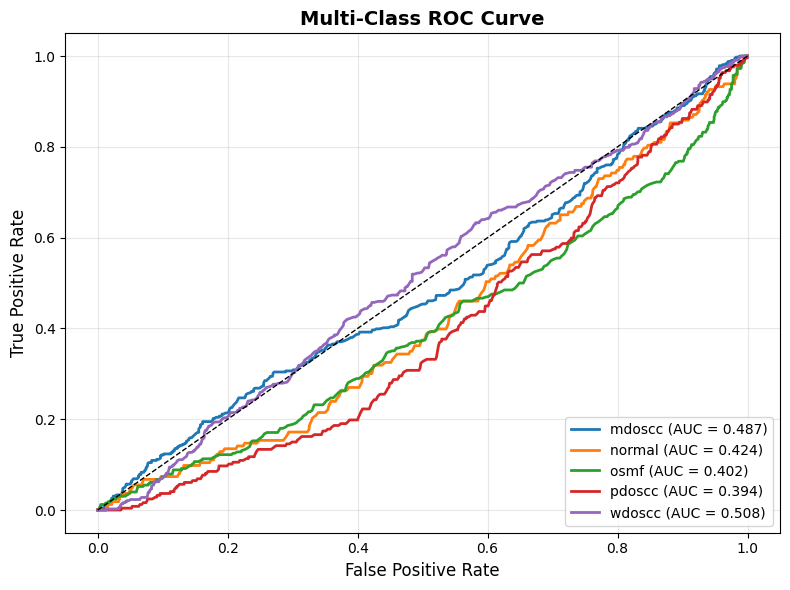

Saved: final_multiclass_roc_curve.png


In [ ]:
# =========================================================
# FINAL MULTI-CLASS ROC CURVE
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize

from sklearn.metrics import (
    roc_curve,
    auc
)

# =========================================================
# EVALUATION
# =========================================================

model.eval()

all_probs = []

all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )

        all_probs.append(
            probs.cpu().numpy()
        )

        all_labels.append(
            labels.cpu().numpy()
        )

# =========================================================
# NUMPY
# =========================================================

all_probs = np.concatenate(
    all_probs,
    axis=0
)

all_labels = np.concatenate(
    all_labels,
    axis=0
)

# =========================================================
# BINARIZE LABELS
# =========================================================

n_classes = len(class_names)

y_true = label_binarize(

    all_labels,

    classes=np.arange(n_classes)

)

# =========================================================
# ROC CURVE
# =========================================================

plt.figure(figsize=(8,6))

for i in range(n_classes):

    fpr, tpr, _ = roc_curve(

        y_true[:, i],

        all_probs[:, i]

    )

    roc_auc = auc(

        fpr,

        tpr

    )

    plt.plot(

        fpr,

        tpr,

        lw=2,

        label=f"{class_names[i]} (AUC = {roc_auc:.3f})"

    )

# =========================================================
# RANDOM LINE
# =========================================================

plt.plot(

    [0,1],

    [0,1],

    linestyle='--',

    color='black',

    lw=1

)

plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "Multi-Class ROC Curve",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/final_multiclass_roc_curve.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved: final_multiclass_roc_curve.png"
)

In [ ]:
import os

MODEL_PATH = "/content/drive/MyDrive/"

for root, dirs, files in os.walk(MODEL_PATH):
    for f in files:
        if f.endswith(".pth"):
            print(os.path.join(root, f))

/content/drive/MyDrive/best_efficientnetb3_cbam.pth
/content/drive/MyDrive/best_efficientnetb3_mcdropout.pth
/content/drive/MyDrive/final_proposed_model.pth
/content/drive/MyDrive/resnet50_best.pth
/content/drive/MyDrive/densenet121_best.pth
/content/drive/MyDrive/mobilenetv3_best.pth
/content/drive/MyDrive/vgg16_best.pth
/content/drive/MyDrive/efficientnetb3_best.pth
/content/drive/MyDrive/best_efficientnetb3.pth


In [ ]:
# =========================================================
# LOAD FINAL PROPOSED MODEL
# =========================================================

PATH = "/content/drive/MyDrive/final_proposed_model.pth"

checkpoint = torch.load(
    PATH,
    map_location=device
)

print(type(checkpoint))

if isinstance(checkpoint, dict):
    print(checkpoint.keys())

<class 'collections.OrderedDict'>
odict_keys(['backbone.conv_stem.weight', 'backbone.bn1.weight', 'backbone.bn1.bias', 'backbone.bn1.running_mean', 'backbone.bn1.running_var', 'backbone.bn1.num_batches_tracked', 'backbone.blocks.0.0.conv_dw.weight', 'backbone.blocks.0.0.bn1.weight', 'backbone.blocks.0.0.bn1.bias', 'backbone.blocks.0.0.bn1.running_mean', 'backbone.blocks.0.0.bn1.running_var', 'backbone.blocks.0.0.bn1.num_batches_tracked', 'backbone.blocks.0.0.se.conv_reduce.weight', 'backbone.blocks.0.0.se.conv_reduce.bias', 'backbone.blocks.0.0.se.conv_expand.weight', 'backbone.blocks.0.0.se.conv_expand.bias', 'backbone.blocks.0.0.conv_pw.weight', 'backbone.blocks.0.0.bn2.weight', 'backbone.blocks.0.0.bn2.bias', 'backbone.blocks.0.0.bn2.running_mean', 'backbone.blocks.0.0.bn2.running_var', 'backbone.blocks.0.0.bn2.num_batches_tracked', 'backbone.blocks.0.1.conv_dw.weight', 'backbone.blocks.0.1.bn1.weight', 'backbone.blocks.0.1.bn1.bias', 'backbone.blocks.0.1.bn1.running_mean', 'backbon

In [ ]:
from torchvision import datasets, transforms

from torch.utils.data import (
    DataLoader,
    Subset
)

import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

In [ ]:
import torch
import torch.nn as nn

from torchvision import datasets, transforms

import timm

Device: cpu
Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']
Model Loaded Successfully


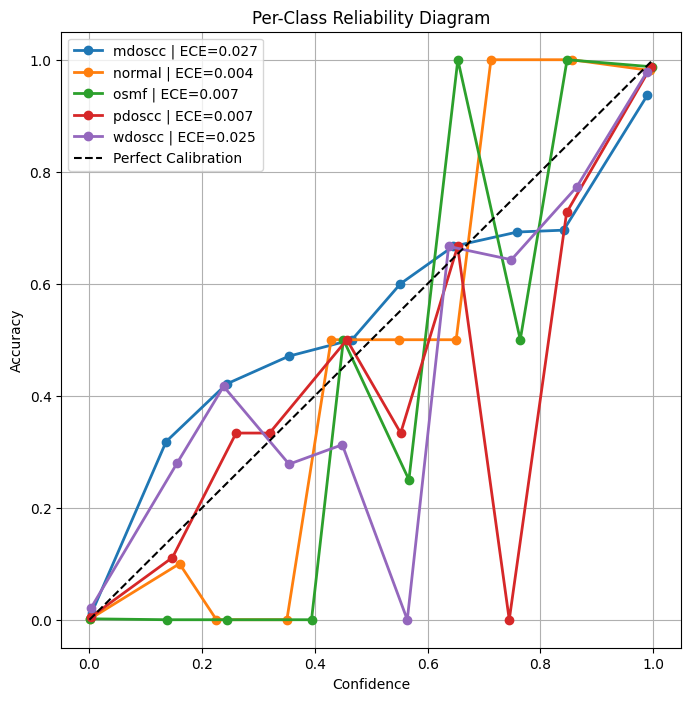


PER-CLASS ECE

mdoscc: 0.0274
normal: 0.0039
osmf: 0.0070
pdoscc: 0.0071
wdoscc: 0.0247

Saved:
/content/drive/MyDrive/per_class_ece.csv
/content/drive/MyDrive/per_class_reliability_diagram.png


In [ ]:
# =========================================================
# PER-CLASS ECE + RELIABILITY DIAGRAM
# FINAL PROPOSED FRAMEWORK
# =========================================================

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

from sklearn.calibration import calibration_curve

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

# =========================================================
# PARAMETERS
# =========================================================

NUM_CLASSES = 5

BATCH_SIZE = 16

# =========================================================
# TEST PATH
# =========================================================

test_dir = "/content/drive/MyDrive/test/test"

# =========================================================
# TRANSFORM
# =========================================================

transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )

])

# =========================================================
# TEST DATASET
# =========================================================

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_dataset.classes

print("Classes:", class_names)

# =========================================================
# LOAD MODEL
# =========================================================

model = ProposedModel(
    num_classes=NUM_CLASSES
)

model.load_state_dict(

    torch.load(

        "/content/drive/MyDrive/final_proposed_model.pth",

        map_location=device

    )

)

model = model.to(device)

model.eval()

print("Model Loaded Successfully")

# =========================================================
# COLLECT PROBABILITIES
# =========================================================

all_probs = []

all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )

        all_probs.extend(
            probs.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

all_probs = np.array(all_probs)

all_labels = np.array(all_labels)

# =========================================================
# PER-CLASS ECE
# =========================================================

n_bins = 10

ece_results = {}

plt.figure(figsize=(8,8))

for cls in range(NUM_CLASSES):

    y_true = (
        all_labels == cls
    ).astype(int)

    y_prob = all_probs[:, cls]

    prob_true, prob_pred = calibration_curve(

        y_true,

        y_prob,

        n_bins=n_bins

    )

    bin_boundaries = np.linspace(
        0,
        1,
        n_bins + 1
    )

    ece = 0

    for i in range(n_bins):

        lower = bin_boundaries[i]

        upper = bin_boundaries[i+1]

        in_bin = (
            (y_prob > lower) &
            (y_prob <= upper)
        )

        prop_in_bin = np.mean(
            in_bin
        )

        if prop_in_bin > 0:

            acc_bin = np.mean(
                y_true[in_bin]
            )

            conf_bin = np.mean(
                y_prob[in_bin]
            )

            ece += np.abs(
                acc_bin -
                conf_bin
            ) * prop_in_bin

    ece_results[
        class_names[cls]
    ] = ece

    plt.plot(

        prob_pred,

        prob_true,

        marker='o',

        linewidth=2,

        label=f"{class_names[cls]} | ECE={ece:.3f}"

    )

# =========================================================
# PERFECT CALIBRATION LINE
# =========================================================

plt.plot(

    [0,1],

    [0,1],

    linestyle='--',

    color='black',

    label='Perfect Calibration'

)

plt.xlabel("Confidence")

plt.ylabel("Accuracy")

plt.title(
    "Per-Class Reliability Diagram"
)

plt.legend()

plt.grid()

plt.savefig(

    "/content/drive/MyDrive/per_class_reliability_diagram.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

# =========================================================
# PRINT ECE
# =========================================================

print("\n===================================")
print("PER-CLASS ECE")
print("===================================\n")

for cls_name, ece in ece_results.items():

    print(
        f"{cls_name}: {ece:.4f}"
    )

# =========================================================
# SAVE CSV
# =========================================================

pd.DataFrame({

    "Class": list(
        ece_results.keys()
    ),

    "ECE": list(
        ece_results.values()
    )

}).to_csv(

    "/content/drive/MyDrive/per_class_ece.csv",

    index=False

)

print(
    "\nSaved:"
)

print(
    "/content/drive/MyDrive/per_class_ece.csv"
)

print(
    "/content/drive/MyDrive/per_class_reliability_diagram.png"
)


PER-CLASS ECE TABLE

    Class       ECE
0  mdoscc  0.027409
1  normal  0.003909
2    osmf  0.006966
3  pdoscc  0.007052
4  wdoscc  0.024675

Saved: per_class_ece.csv


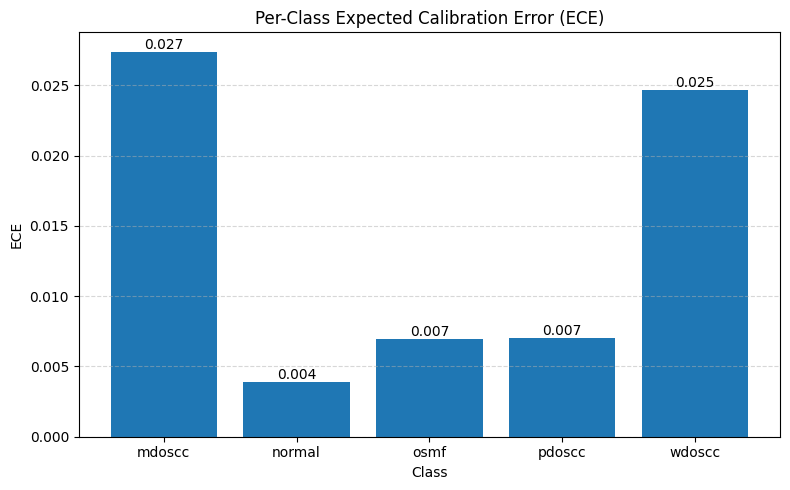

Saved: per_class_ece_bar_chart.png


In [ ]:
# =========================================================
# PER-CLASS ECE BAR CHART + TABLE
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# ECE RESULTS
# =========================================================

ece_df = pd.DataFrame({

    "Class": list(ece_results.keys()),

    "ECE": list(ece_results.values())

})

# =========================================================
# PRINT TABLE
# =========================================================

print("\n===================================")
print("PER-CLASS ECE TABLE")
print("===================================\n")

print(ece_df)

# =========================================================
# SAVE CSV
# =========================================================

ece_df.to_csv(

    "/content/drive/MyDrive/per_class_ece.csv",

    index=False

)

print(
    "\nSaved: per_class_ece.csv"
)

# =========================================================
# BAR CHART
# =========================================================

plt.figure(figsize=(8,5))

bars = plt.bar(

    ece_df["Class"],

    ece_df["ECE"]

)

plt.ylabel("ECE")

plt.xlabel("Class")

plt.title(
    "Per-Class Expected Calibration Error (ECE)"
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)

# Show value on top of bars

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x() + bar.get_width()/2,

        height,

        f"{height:.3f}",

        ha='center',

        va='bottom'

    )

plt.tight_layout()

plt.savefig(

    "/content/drive/MyDrive/per_class_ece_bar_chart.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

print(
    "Saved: per_class_ece_bar_chart.png"
)


PER-CLASS ECE TABLE

    Class       ECE
0  mdoscc  0.027409
1  normal  0.003909
2    osmf  0.006966
3  pdoscc  0.007052
4  wdoscc  0.024675

Saved: per_class_ece.csv


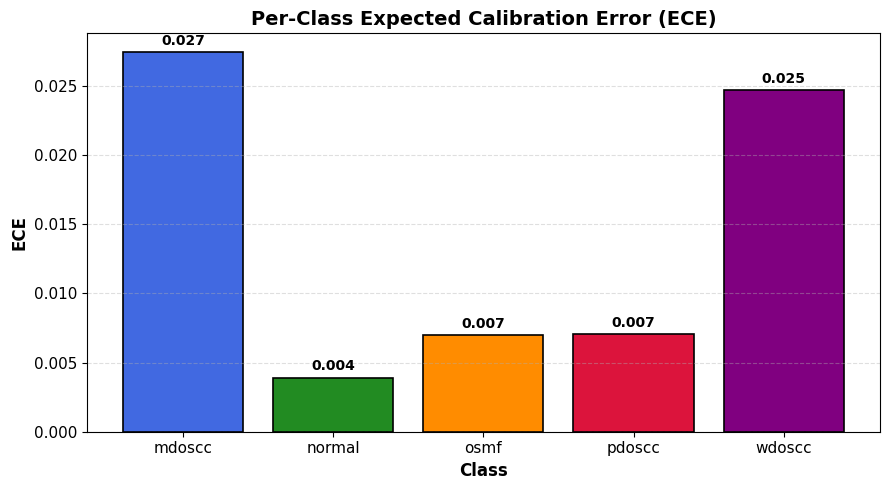


Saved: per_class_ece_bar_chart_journal.png


In [ ]:
# =========================================================
# PER-CLASS ECE BAR CHART + TABLE
# JOURNAL VERSION
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt

# =========================================================
# ECE RESULTS
# =========================================================

ece_df = pd.DataFrame({

    "Class": list(ece_results.keys()),

    "ECE": list(ece_results.values())

})

# =========================================================
# PRINT TABLE
# =========================================================

print("\n===================================")
print("PER-CLASS ECE TABLE")
print("===================================\n")

print(ece_df)

# =========================================================
# SAVE CSV
# =========================================================

ece_df.to_csv(

    "/content/drive/MyDrive/per_class_ece.csv",

    index=False

)

print("\nSaved: per_class_ece.csv")

# =========================================================
# COLORS
# =========================================================

colors = [

    "royalblue",    # mdoscc

    "forestgreen",  # normal

    "darkorange",   # osmf

    "crimson",      # pdoscc

    "purple"        # wdoscc

]

# =========================================================
# BAR CHART
# =========================================================

plt.figure(figsize=(9,5))

bars = plt.bar(

    ece_df["Class"],

    ece_df["ECE"],

    color=colors,

    edgecolor="black",

    linewidth=1.2

)

plt.ylabel(
    "ECE",
    fontsize=12,
    fontweight='bold'
)

plt.xlabel(
    "Class",
    fontsize=12,
    fontweight='bold'
)

plt.title(
    "Per-Class Expected Calibration Error (ECE)",
    fontsize=14,
    fontweight='bold'
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.4
)

# =========================================================
# VALUE LABELS
# =========================================================

for bar in bars:

    height = bar.get_height()

    plt.text(

        bar.get_x() + bar.get_width()/2,

        height + 0.0003,

        f"{height:.3f}",

        ha='center',

        va='bottom',

        fontsize=10,

        fontweight='bold'

    )

plt.xticks(
    fontsize=11
)

plt.yticks(
    fontsize=11
)

plt.tight_layout()

# =========================================================
# SAVE FIGURE
# =========================================================

plt.savefig(

    "/content/drive/MyDrive/per_class_ece_bar_chart_journal.png",

    dpi=600,

    bbox_inches="tight"

)

plt.show()

print(
    "\nSaved: per_class_ece_bar_chart_journal.png"
)


CALIBRATION ANALYSIS

Expected Calibration Error (ECE): 0.0302


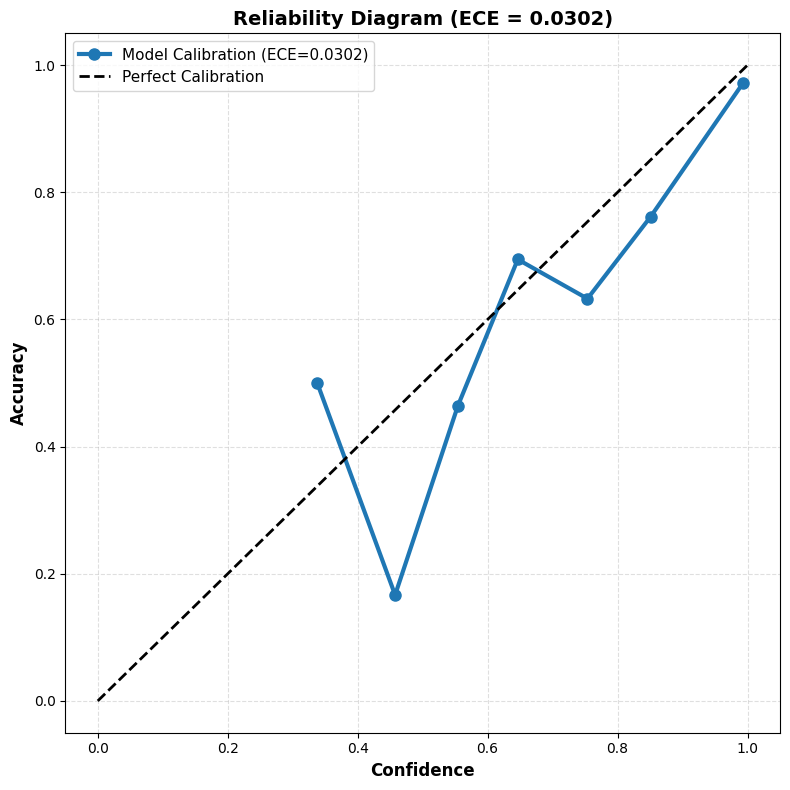


Saved: overall_reliability_diagram_journal.png


In [ ]:
# =========================================================
# CALIBRATION ANALYSIS
# OVERALL ECE + RELIABILITY DIAGRAM
# JOURNAL VERSION
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve

# =========================================================
# MODEL EVALUATION
# =========================================================

model.eval()

all_probs = []
all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )

        confidences, preds = torch.max(
            probs,
            dim=1
        )

        all_probs.extend(
            confidences.cpu().numpy()
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

# =========================================================
# NUMPY
# =========================================================

all_probs = np.array(all_probs)

all_preds = np.array(all_preds)

all_labels = np.array(all_labels)

# =========================================================
# CORRECTNESS
# =========================================================

correct = (
    all_preds == all_labels
).astype(int)

# =========================================================
# ECE
# =========================================================

n_bins = 10

bin_boundaries = np.linspace(
    0,
    1,
    n_bins + 1
)

ece = 0.0

for i in range(n_bins):

    bin_lower = bin_boundaries[i]

    bin_upper = bin_boundaries[i + 1]

    in_bin = (
        (all_probs > bin_lower) &
        (all_probs <= bin_upper)
    )

    prop_in_bin = np.mean(
        in_bin
    )

    if prop_in_bin > 0:

        accuracy_in_bin = np.mean(
            correct[in_bin]
        )

        avg_confidence_in_bin = np.mean(
            all_probs[in_bin]
        )

        ece += np.abs(
            avg_confidence_in_bin -
            accuracy_in_bin
        ) * prop_in_bin

# =========================================================
# PRINT ECE
# =========================================================

print("\n===================================")
print("CALIBRATION ANALYSIS")
print("===================================\n")

print(
    f"Expected Calibration Error (ECE): {ece:.4f}"
)

# =========================================================
# RELIABILITY DIAGRAM
# =========================================================

prob_true, prob_pred = calibration_curve(

    correct,

    all_probs,

    n_bins=n_bins

)

plt.figure(figsize=(8,8))

plt.plot(

    prob_pred,

    prob_true,

    marker='o',

    markersize=8,

    linewidth=3,

    label=f'Model Calibration (ECE={ece:.4f})'

)

plt.plot(

    [0,1],

    [0,1],

    linestyle='--',

    linewidth=2,

    color='black',

    label='Perfect Calibration'

)

plt.xlabel(
    "Confidence",
    fontsize=12,
    fontweight='bold'
)

plt.ylabel(
    "Accuracy",
    fontsize=12,
    fontweight='bold'
)

plt.title(

    f"Reliability Diagram (ECE = {ece:.4f})",

    fontsize=14,

    fontweight='bold'

)

plt.legend(
    fontsize=11
)

plt.grid(
    linestyle='--',
    alpha=0.4
)

plt.tight_layout()

# =========================================================
# SAVE FIGURE
# =========================================================

plt.savefig(

    "/content/drive/MyDrive/overall_reliability_diagram_journal.png",

    dpi=600,

    bbox_inches="tight"

)

plt.show()

print(
    "\nSaved: overall_reliability_diagram_journal.png"
)

In [ ]:
print("results_df" in globals())

False


In [ ]:
import torch
import torch.nn as nn
import timm

# =========================================================
# CBAM MODULE
# =========================================================

class ChannelAttention(nn.Module):

    def __init__(self, in_channels, reduction=16):

        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(

            nn.Conv2d(
                in_channels,
                in_channels // reduction,
                1,
                bias=False
            ),

            nn.ReLU(),

            nn.Conv2d(
                in_channels // reduction,
                in_channels,
                1,
                bias=False
            )
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(
            self.avg_pool(x)
        )

        max_out = self.fc(
            self.max_pool(x)
        )

        return self.sigmoid(
            avg_out + max_out
        )

# =========================================================

class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        x = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        x = self.conv(x)

        return self.sigmoid(x)

# =========================================================

class CBAM(nn.Module):

    def __init__(self, in_channels):

        super().__init__()

        self.channel_attention = ChannelAttention(
            in_channels
        )

        self.spatial_attention = SpatialAttention()

    def forward(self, x):

        x = x * self.channel_attention(x)

        x = x * self.spatial_attention(x)

        return x

# =========================================================
# FINAL PROPOSED MODEL
# =========================================================

class ProposedModel(nn.Module):

    def __init__(self, num_classes=5):

        super().__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.5)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

print("ProposedModel Loaded Successfully")

ProposedModel Loaded Successfully


In [ ]:
print("ProposedModel" in globals())

True


In [ ]:
# =========================================================
# DATASET PATHS
# =========================================================

TRAIN_DIR = "/content/drive/MyDrive/ORCHID_224_JPG"

VAL_DIR = "/content/drive/MyDrive/val"

TEST_DIR = "/content/drive/MyDrive/test/test"

# =========================================================
# TRANSFORMS
# =========================================================

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_ds = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_ds = datasets.ImageFolder(
    VAL_DIR,
    transform=test_transform
)

test_ds = datasets.ImageFolder(
    TEST_DIR,
    transform=test_transform
)

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train Samples :", len(train_ds))
print("Val Samples   :", len(val_ds))
print("Test Samples  :", len(test_ds))

print("Classes :", train_ds.classes)

Train Samples : 10227
Val Samples   : 2885
Test Samples  : 1592
Classes : ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


Tesla T4
Device: cuda

Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


/tmp/ipykernel_10980/3135187868.py:244: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Epoch 1/10


  0%|          | 0/320 [00:00<?, ?it/s]/tmp/ipykernel_10980/3135187868.py:274: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 1.1855 | Acc: 55.72%: 100%|██████████| 320/320 [30:27<00:00,  5.71s/it]
/tmp/ipykernel_10980/3135187868.py:326: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 1.2864
Train Acc  : 55.72%
Val Loss   : 0.7876
Val Acc    : 68.42%
Val Precision : 0.6831
Val Recall    : 0.6842
Val F1        : 0.6797

Best Efficientnetb3 Model Saved!

Epoch 2/10


...


Train Loss : 0.1018
Train Acc  : 96.31%
Val Loss   : 0.2739
Val Acc    : 90.47%
Val Precision : 0.9047
Val Recall    : 0.9047
Val F1        : 0.9045

Best Efficientnetb3 Model Saved!

Epoch 10/10


  0%|          | 0/320 [00:00<?, ?it/s]/tmp/ipykernel_10980/3135187868.py:274: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 0.0653 | Acc: 96.78%: 100%|██████████| 320/320 [01:12<00:00,  4.39it/s]
/tmp/ipykernel_10980/3135187868.py:326: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 0.0826
Train Acc  : 96.78%
Val Loss   : 0.2640
Val Acc    : 91.37%
Val Precision : 0.9142
Val Recall    : 0.9137
Val F1        : 0.9137

Best Efficientnetb3 Model Saved!


/tmp/ipykernel_10980/3135187868.py:326: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



FINAL TEST RESULTS

Accuracy  : 91.21%
Precision : 0.9120
Recall    : 0.9121
F1 Score  : 0.9119

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.87      0.85      0.86       421
      normal       0.93      0.97      0.95       163
        osmf       0.97      0.97      0.97       328
      pdoscc       0.95      0.94      0.95       247
      wdoscc       0.88      0.89      0.88       433

    accuracy                           0.91      1592
   macro avg       0.92      0.92      0.92      1592
weighted avg       0.91      0.91      0.91      1592



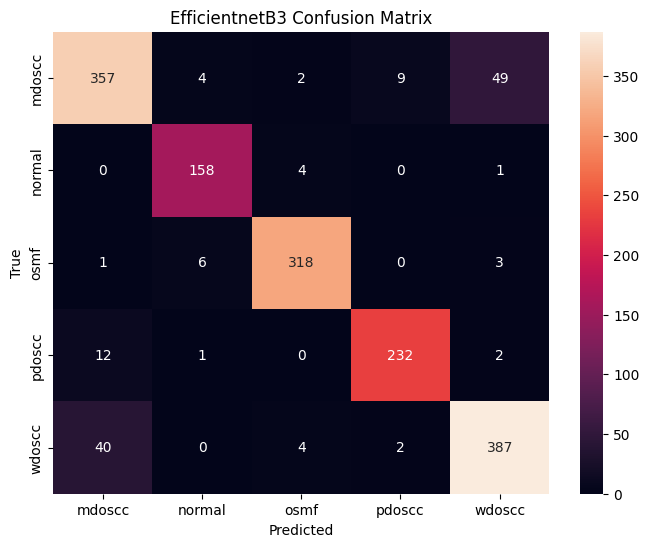

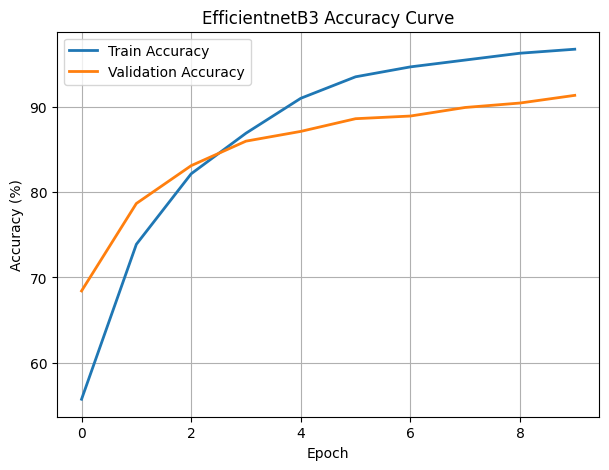

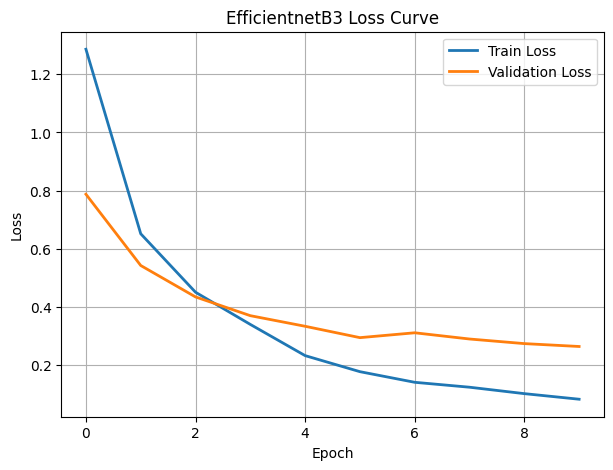

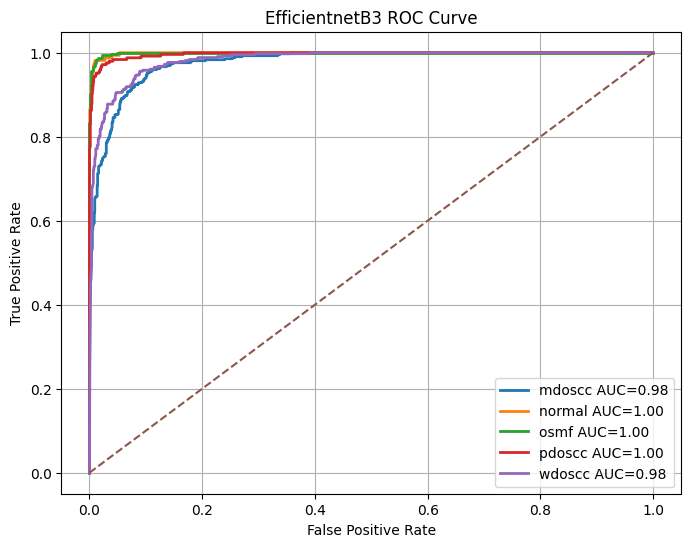

In [ ]:
# =========================================================
# FAST DENSENET121 BASELINE
# GPU OPTIMIZED VERSION
# =========================================================

# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms,
    models
)

from torch.cuda.amp import (
    autocast,
    GradScaler
)

# =========================================================
# GPU SPEED BOOST
# =========================================================

torch.backends.cudnn.benchmark = True

# =========================================================
# CHECK GPU
# =========================================================

print(torch.cuda.get_device_name(0))

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# =========================================================
# PATHS
# =========================================================

train_dir = "/content/drive/MyDrive/ORCHID_224_JPG"

val_dir = "/content/drive/MyDrive/val"

test_dir = "/content/drive/MyDrive/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224

BATCH_SIZE = 32

EPOCHS = 10

LR = 1e-4

NUM_CLASSES = 5

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

# =========================================================
# CLASS NAMES
# =========================================================

class_names = train_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# MODEL
# =========================================================

# =========================================================
# MODEL
# =========================================================

import timm

model = timm.create_model(
    "efficientnet_b3",
    pretrained=True,
    num_classes=NUM_CLASSES
)

model = model.to(device)

# =========================================================
# LOSS & OPTIMIZER
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

# =========================================================
# LOSS & OPTIMIZER
# =========================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LR
)

# =========================================================
# MIXED PRECISION
# =========================================================

scaler = GradScaler()

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    loop = tqdm(loader)

    for images, labels in loop:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        # =============================================
        # MIXED PRECISION
        # =============================================

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        acc = 100 * correct / total

        loop.set_description(
            f"Loss: {loss.item():.4f} | Acc: {acc:.2f}%"
        )

    return running_loss / len(loader), acc

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(model, loader):

    model.eval()

    running_loss = 0

    all_labels = []

    all_preds = []

    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            with autocast():

                outputs = model(images)

                loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(outputs, 1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)
    )

# =========================================================
# STORAGE
# =========================================================

train_losses = []

val_losses = []

train_accs = []

val_accs = []

best_val_acc = 0

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    print("\n===================================")

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print("===================================")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accs.append(train_acc)

    val_accs.append(val_acc * 100)

    print(f"\nTrain Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"Val Precision : {val_precision:.4f}")

    print(f"Val Recall    : {val_recall:.4f}")

    print(f"Val F1        : {val_f1:.4f}")

    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(

            model.state_dict(),

            "/content/drive/MyDrive/Efficientnetb3_best.pth"
        )

        print("\nBest Efficientnetb3 Model Saved!")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3_best.pth"
    )
)

# =========================================================
# TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob

) = evaluate(
    model,
    test_loader
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================")

print("FINAL TEST RESULTS")

print("===================================\n")

print(f"Accuracy  : {test_acc*100:.2f}%")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")

print("CLASSIFICATION REPORT")

print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("EfficientnetB3 Confusion Matrix")

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    linewidth=2,
    label='Train Accuracy'
)

plt.plot(
    val_accs,
    linewidth=2,
    label='Validation Accuracy'
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("EfficientnetB3 Accuracy Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    linewidth=2,
    label='Train Loss'
)

plt.plot(
    val_losses,
    linewidth=2,
    label='Validation Loss'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("EfficientnetB3 Loss Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(
    y_true,
    classes=[0,1,2,3,4]
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} AUC={roc_auc:.2f}"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("EfficientnetB3 ROC Curve")

plt.legend()

plt.grid()

plt.show()

Tesla T4
Device: cuda

Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

/tmp/ipykernel_2231/1981121663.py:259: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Epoch 1/10


...


Train Loss : 0.4722
Train Acc  : 95.99%
Val Loss   : 0.5551
Val Acc    : 93.03%
Val Precision : 0.9302
Val Recall    : 0.9303
Val F1        : 0.9301

Epoch 10/10


  0%|          | 0/640 [00:00<?, ?it/s]/tmp/ipykernel_2231/1981121663.py:289: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 1.4791 | Acc: 96.66%: 100%|██████████| 640/640 [01:26<00:00,  7.40it/s]
/tmp/ipykernel_2231/1981121663.py:341: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 0.4612
Train Acc  : 96.66%
Val Loss   : 0.5931
Val Acc    : 93.38%
Val Precision : 0.9339
Val Recall    : 0.9338
Val F1        : 0.9337


/tmp/ipykernel_2231/1981121663.py:341: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



FINAL TEST RESULTS

Accuracy  : 93.34%
Precision : 0.9337
Recall    : 0.9334
F1 Score  : 0.9334

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.89      0.91      0.90       421
      normal       0.97      0.92      0.94       163
        osmf       0.98      0.99      0.98       328
      pdoscc       0.94      0.96      0.95       247
      wdoscc       0.93      0.90      0.92       433

    accuracy                           0.93      1592
   macro avg       0.94      0.94      0.94      1592
weighted avg       0.93      0.93      0.93      1592



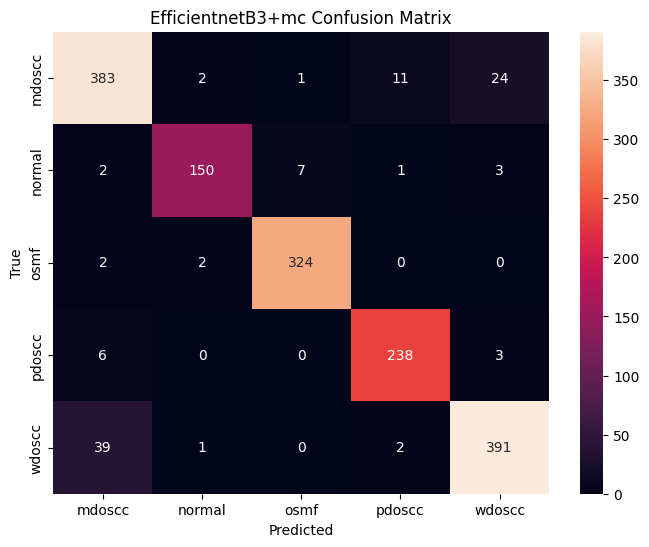

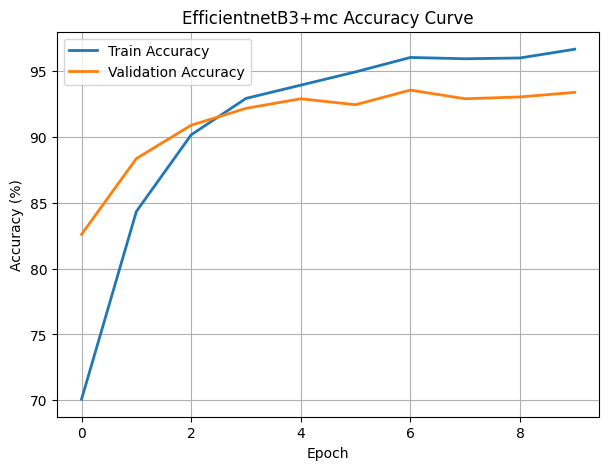

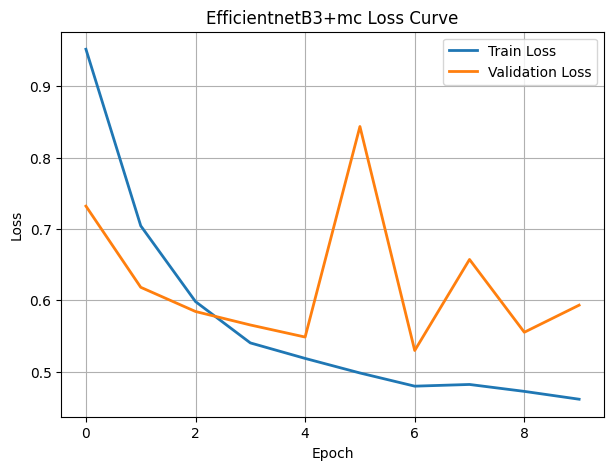

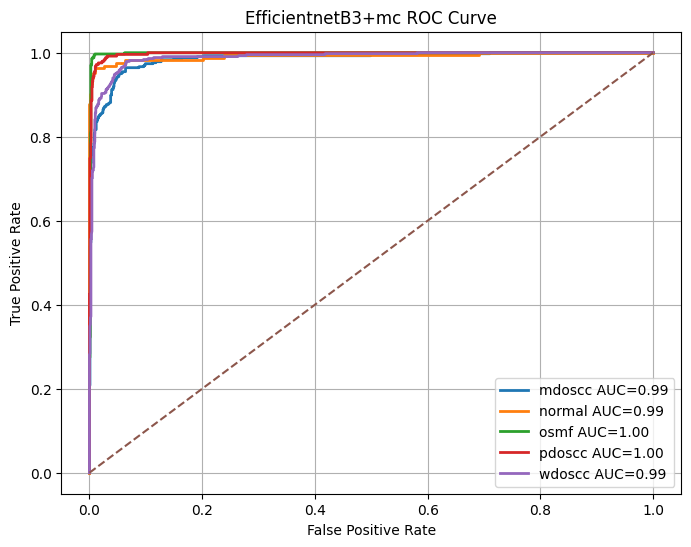

In [ ]:
# =========================================================
# FAST DENSENET121 BASELINE
# GPU OPTIMIZED VERSION
# =========================================================

# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms,
    models
)

from torch.cuda.amp import (
    autocast,
    GradScaler
)

# =========================================================
# GPU SPEED BOOST
# =========================================================

torch.backends.cudnn.benchmark = True

# =========================================================
# CHECK GPU
# =========================================================

print(torch.cuda.get_device_name(0))

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# =========================================================
# PATHS
# =========================================================

train_dir = "/content/drive/MyDrive/ORCHID_224_JPG"

val_dir = "/content/drive/MyDrive/val"

test_dir = "/content/drive/MyDrive/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224

BATCH_SIZE = 16

EPOCHS = 10

LR = 1e-4

NUM_CLASSES = 5

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

# =========================================================
# CLASS NAMES
# =========================================================

class_names = train_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# MODEL
# =========================================================

# =========================================================
# MODEL
# =========================================================

import timm
import torch.nn as nn

class EfficientNetB3_MC(nn.Module):

    def __init__(self, num_classes=5):

        super().__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=True,
            num_classes=0
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(
            self.backbone.num_features,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.dropout(x)

        x = self.fc(x)

        return x


model = EfficientNetB3_MC(
    num_classes=NUM_CLASSES
).to(device)

# =========================================================
# LOSS & OPTIMIZER
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)
# =========================================================
# MIXED PRECISION
# =========================================================

scaler = GradScaler()

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    loop = tqdm(loader)

    for images, labels in loop:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        # =============================================
        # MIXED PRECISION
        # =============================================

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        acc = 100 * correct / total

        loop.set_description(
            f"Loss: {loss.item():.4f} | Acc: {acc:.2f}%"
        )

    return running_loss / len(loader), acc

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(model, loader):

    model.eval()

    running_loss = 0

    all_labels = []

    all_preds = []

    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            with autocast():

                outputs = model(images)

                loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(outputs, 1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)
    )

# =========================================================
# STORAGE
# =========================================================

train_losses = []

val_losses = []

train_accs = []

val_accs = []

best_val_acc = 0

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    print("\n===================================")

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print("===================================")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accs.append(train_acc)

    val_accs.append(val_acc * 100)

    print(f"\nTrain Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"Val Precision : {val_precision:.4f}")

    print(f"Val Recall    : {val_recall:.4f}")

    print(f"Val F1        : {val_f1:.4f}")

    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(

            model.state_dict(),

            "/content/drive/MyDrive/Efficientnetb3+mc_best.pth"
        )

        print("\nBest Efficientnetb3 Model Saved!")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3+mc_best.pth"
    )
)

# =========================================================
# TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob

) = evaluate(
    model,
    test_loader
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================")

print("FINAL TEST RESULTS")

print("===================================\n")

print(f"Accuracy  : {test_acc*100:.2f}%")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")

print("CLASSIFICATION REPORT")

print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("EfficientnetB3+mc Confusion Matrix")

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    linewidth=2,
    label='Train Accuracy'
)

plt.plot(
    val_accs,
    linewidth=2,
    label='Validation Accuracy'
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("EfficientnetB3+mc Accuracy Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    linewidth=2,
    label='Train Loss'
)

plt.plot(
    val_losses,
    linewidth=2,
    label='Validation Loss'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("EfficientnetB3+mc Loss Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(
    y_true,
    classes=[0,1,2,3,4]
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} AUC={roc_auc:.2f}"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("EfficientnetB3+mc ROC Curve")

plt.legend()

plt.grid()

plt.show()

In [ ]:
# =========================================================
# FAST DENSENET121 BASELINE
# GPU OPTIMIZED VERSION
# =========================================================

# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms,
    models
)



# =========================================================
# GPU SPEED BOOST
# =========================================================

torch.backends.cudnn.benchmark = True

# =========================================================
# CHECK GPU
# =========================================================

print(torch.cuda.get_device_name(0))

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# =========================================================
# PATHS
# =========================================================

train_dir = "/content/drive/MyDrive/ORCHID_224_JPG"

val_dir = "/content/drive/MyDrive/val"

test_dir = "/content/drive/MyDrive/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224

BATCH_SIZE = 32

EPOCHS = 10

LR = 1e-4

NUM_CLASSES = 5

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

# =========================================================
# CLASS NAMES
# =========================================================

class_names = train_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# MODEL
# =========================================================

# =========================================================
# MODEL
# =========================================================

import timm
import torch
import torch.nn as nn

# =========================================================
# CBAM
# =========================================================

class ChannelAttention(nn.Module):

    def __init__(self, in_planes, ratio=16):

        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))

        out = avg_out + max_out

        return self.sigmoid(out)


class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size//2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        x = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        x = self.conv(x)

        return self.sigmoid(x)


class CBAM(nn.Module):

    def __init__(self, channels):

        super().__init__()

        self.ca = ChannelAttention(channels)

        self.sa = SpatialAttention()

    def forward(self, x):

        x = x * self.ca(x)

        x = x * self.sa(x)

        return x


# =========================================================
# EfficientNetB3 + CBAM
# =========================================================

class EfficientNetB3_CBAM_MC(nn.Module):

    def __init__(self, num_classes=5):

        super().__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=True,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        # MC Dropout
        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

# =========================================================
# LOSS & OPTIMIZER
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)
model = EfficientNetB3_CBAM_MC(
    num_classes=NUM_CLASSES
).to(device)
# =========================================================
# MIXED PRECISION
# =========================================================

scaler = GradScaler()

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    loop = tqdm(loader)

    for images, labels in loop:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        # =============================================
        # MIXED PRECISION
        # =============================================

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        acc = 100 * correct / total

        loop.set_description(
            f"Loss: {loss.item():.4f} | Acc: {acc:.2f}%"
        )

    return running_loss / len(loader), acc

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(model, loader):

    model.eval()

    running_loss = 0

    all_labels = []

    all_preds = []

    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            with autocast():

                outputs = model(images)

                loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(outputs, 1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)
    )

# =========================================================
# STORAGE
# =========================================================

train_losses = []

val_losses = []

train_accs = []

val_accs = []

best_val_acc = 0

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    print("\n===================================")

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print("===================================")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accs.append(train_acc)

    val_accs.append(val_acc * 100)

    print(f"\nTrain Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"Val Precision : {val_precision:.4f}")

    print(f"Val Recall    : {val_recall:.4f}")

    print(f"Val F1        : {val_f1:.4f}")

    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(

            model.state_dict(),

            "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth"
        )

        print("\nBest Efficientnetb3 Model Saved!")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth"
    )
)

# =========================================================
# TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob

) = evaluate(
    model,
    test_loader
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================")

print("FINAL TEST RESULTS")

print("===================================\n")

print(f"Accuracy  : {test_acc*100:.2f}%")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")

print("CLASSIFICATION REPORT")

print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("EfficientnetB3+CBAM+MC Confusion Matrix")

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    linewidth=2,
    label='Train Accuracy'
)

plt.plot(
    val_accs,
    linewidth=2,
    label='Validation Accuracy'
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("EfficientnetB3+CBAM+MC Accuracy Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    linewidth=2,
    label='Train Loss'
)

plt.plot(
    val_losses,
    linewidth=2,
    label='Validation Loss'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("EfficientnetB3+CBAM+MC Loss Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(
    y_true,
    classes=[0,1,2,3,4]
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} AUC={roc_auc:.2f}"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("EfficientnetB3+CBAM+MC ROC Curve")

plt.legend()

plt.grid()

plt.show()

AssertionError: Torch not compiled with CUDA enabled

In [ ]:
print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))
print(train_dataset.classes)

NameError: name 'train_dataset' is not defined

Tesla T4
Device: cuda

Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

/tmp/ipykernel_4484/3908332893.py:366: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Epoch 1/10


...


Train Loss : 0.4691
Train Acc  : 96.24%
Val Loss   : 0.5246
Val Acc    : 93.45%
Val Precision : 0.9346
Val Recall    : 0.9345
Val F1        : 0.9344

Best Efficientnetb3+CBAM+MC Model Saved!

Epoch 10/10


  0%|          | 0/640 [00:00<?, ?it/s]/tmp/ipykernel_4484/3908332893.py:396: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Loss: 1.7255 | Acc: 96.58%: 100%|██████████| 640/640 [01:36<00:00,  6.64it/s]
/tmp/ipykernel_4484/3908332893.py:448: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 0.4618
Train Acc  : 96.58%
Val Loss   : 0.5472
Val Acc    : 93.03%
Val Precision : 0.9311
Val Recall    : 0.9303
Val F1        : 0.9303


/tmp/ipykernel_4484/3908332893.py:448: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



FINAL TEST RESULTS

Accuracy  : 94.10%
Precision : 0.9412
Recall    : 0.9410
F1 Score  : 0.9408

CLASSIFICATION REPORT

              precision    recall  f1-score   support

      mdoscc       0.92      0.92      0.92       421
      normal       0.99      0.91      0.95       163
        osmf       0.96      0.99      0.97       328
      pdoscc       0.96      0.98      0.97       247
      wdoscc       0.92      0.91      0.92       433

    accuracy                           0.94      1592
   macro avg       0.95      0.94      0.95      1592
weighted avg       0.94      0.94      0.94      1592



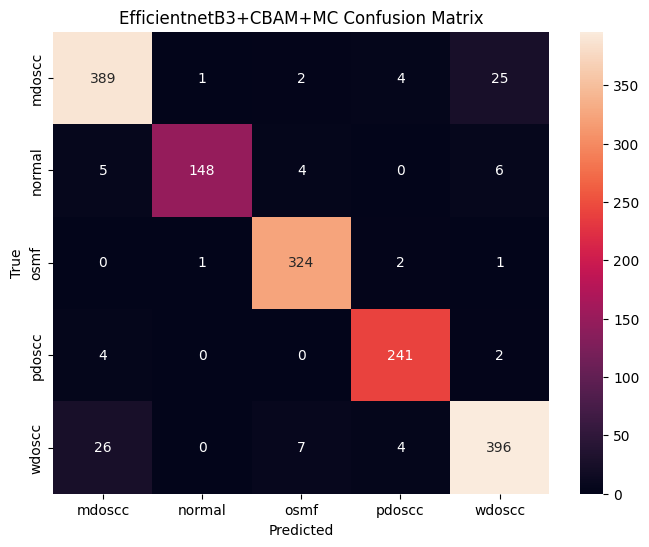

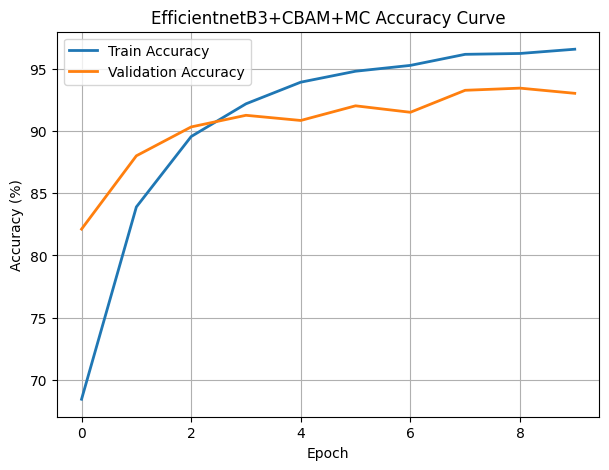

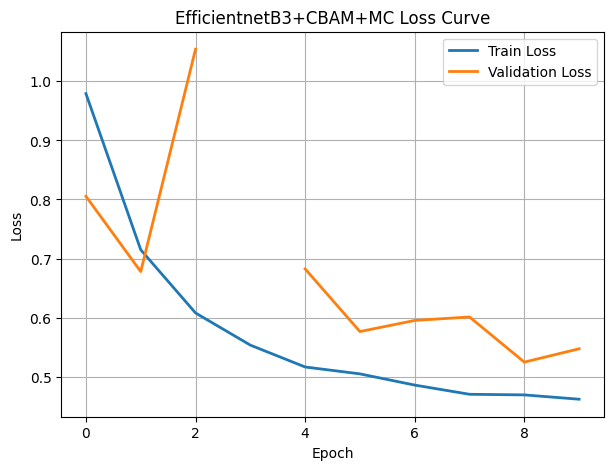

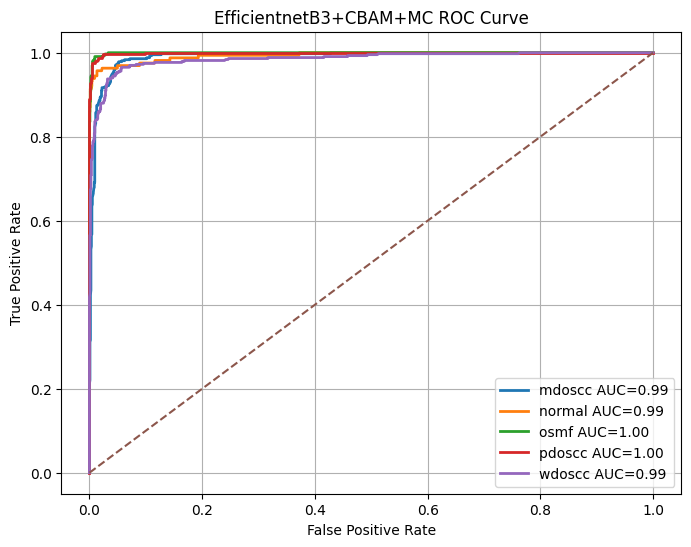

In [ ]:
# =========================================================
# FAST DENSENET121 BASELINE
# GPU OPTIMIZED VERSION
# =========================================================

# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms,
    models
)

from torch.cuda.amp import (
    autocast,
    GradScaler
)

# =========================================================
# GPU SPEED BOOST
# =========================================================

torch.backends.cudnn.benchmark = True

# =========================================================
# CHECK GPU
# =========================================================

print(torch.cuda.get_device_name(0))

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# =========================================================
# PATHS
# =========================================================

train_dir = "/content/drive/MyDrive/ORCHID_224_JPG"

val_dir = "/content/drive/MyDrive/val"

test_dir = "/content/drive/MyDrive/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224

BATCH_SIZE = 16

EPOCHS = 10

LR = 1e-4

NUM_CLASSES = 5

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

# =========================================================
# CLASS NAMES
# =========================================================

class_names = train_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# MODEL
# =========================================================

# =========================================================
# MODEL
# =========================================================

import timm
import torch
import torch.nn as nn

# =========================================================
# CBAM
# =========================================================

class ChannelAttention(nn.Module):

    def __init__(self, in_planes, ratio=16):

        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))

        out = avg_out + max_out

        return self.sigmoid(out)


class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size//2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        x = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        x = self.conv(x)

        return self.sigmoid(x)


class CBAM(nn.Module):

    def __init__(self, channels):

        super().__init__()

        self.ca = ChannelAttention(channels)

        self.sa = SpatialAttention()

    def forward(self, x):

        x = x * self.ca(x)

        x = x * self.sa(x)

        return x


# =========================================================
# EfficientNetB3 + CBAM
# =========================================================

class EfficientNetB3_CBAM_MC(nn.Module):

    def __init__(self, num_classes=5):

        super().__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=True,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        # MC Dropout
        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

model = EfficientNetB3_CBAM_MC(
    num_classes=NUM_CLASSES
).to(device)

# =========================================================
# LOSS & OPTIMIZER
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

# =========================================================
# MIXED PRECISION
# =========================================================

scaler = GradScaler()

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    loop = tqdm(loader)

    for images, labels in loop:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        # =============================================
        # MIXED PRECISION
        # =============================================

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        acc = 100 * correct / total

        loop.set_description(
            f"Loss: {loss.item():.4f} | Acc: {acc:.2f}%"
        )

    return running_loss / len(loader), acc

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(model, loader):

    model.eval()

    running_loss = 0

    all_labels = []

    all_preds = []

    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            with autocast():

                outputs = model(images)

                loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(outputs, 1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)
    )

# =========================================================
# STORAGE
# =========================================================

train_losses = []

val_losses = []

train_accs = []

val_accs = []

best_val_acc = 0

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    print("\n===================================")

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print("===================================")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accs.append(train_acc)

    val_accs.append(val_acc * 100)

    print(f"\nTrain Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"Val Precision : {val_precision:.4f}")

    print(f"Val Recall    : {val_recall:.4f}")

    print(f"Val F1        : {val_f1:.4f}")

    # =====================================================
    # SAVE BEST MODEL
    # =====================================================

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(

            model.state_dict(),

            "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth"
        )

        print("\nBest Efficientnetb3+CBAM+MC Model Saved!")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth"
    )
)

# =========================================================
# TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob

) = evaluate(
    model,
    test_loader
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================")

print("FINAL TEST RESULTS")

print("===================================\n")

print(f"Accuracy  : {test_acc*100:.2f}%")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")

print("CLASSIFICATION REPORT")

print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("EfficientnetB3+CBAM+MC Confusion Matrix")

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    linewidth=2,
    label='Train Accuracy'
)

plt.plot(
    val_accs,
    linewidth=2,
    label='Validation Accuracy'
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("EfficientnetB3+CBAM+MC Accuracy Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    linewidth=2,
    label='Train Loss'
)

plt.plot(
    val_losses,
    linewidth=2,
    label='Validation Loss'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("EfficientnetB3+CBAM+MC Loss Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(
    y_true,
    classes=[0,1,2,3,4]
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} AUC={roc_auc:.2f}"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("EfficientnetB3+CBAM+MC ROC Curve")

plt.legend()

plt.grid()

plt.show()

In [ ]:
import torch
import torch.nn as nn
import timm

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------
# CBAM
# -------------------------

class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))
        return self.sigmoid(avg_out + max_out)


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()

        self.conv = nn.Conv2d(
            2, 1,
            kernel_size,
            padding=kernel_size//2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)

        x = torch.cat([avg_out, max_out], dim=1)
        x = self.conv(x)

        return self.sigmoid(x)


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.ca = ChannelAttention(channels)
        self.sa = SpatialAttention()

    def forward(self, x):
        x = x * self.ca(x)
        x = x * self.sa(x)
        return x


# -------------------------
# MODEL
# -------------------------

class EfficientNetB3_CBAM_MC(nn.Module):

    def __init__(self, num_classes=5):
        super().__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=False,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(1536, num_classes)

    def forward(self, x):

        x = self.backbone(x)
        x = self.cbam(x)
        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x


# -------------------------
# LOAD MODEL
# -------------------------

model = EfficientNetB3_CBAM_MC(num_classes=5).to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth",
        map_location=device
    )
)

model.eval()

print("Model Loaded Successfully")

Model Loaded Successfully


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

def enable_mc_dropout(model):
    for m in model.modules():
        if m.__class__.__name__.startswith('Dropout'):
            m.train()

In [ ]:
def mc_dropout_prediction(model, images, mc_samples=30):

    enable_mc_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(images)

            probs = F.softmax(outputs, dim=1)

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    mean_probs = predictions.mean(axis=0)

    uncertainty = predictions.var(axis=0).mean(axis=1)

    confidence = np.max(mean_probs, axis=1)

    pred_class = np.argmax(mean_probs, axis=1)

    return pred_class, confidence, uncertainty

In [ ]:
images, labels = next(iter(test_loader))

images = images.to(device)

preds, confidence, uncertainty = mc_dropout_prediction(
    model,
    images
)

print("Confidence:")
print(confidence)

KeyboardInterrupt: 

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

test_dataset = datasets.ImageFolder(
    "/content/drive/MyDrive/test/test",  # তোমার path
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Test Samples:", len(test_dataset))

Test Samples: 1592


In [ ]:
all_confidences = []
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)

        confidence, preds = torch.max(probs, dim=1)

        all_confidences.extend(confidence.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

CONF_THRESHOLD = 0.80

trusted_idx = np.array(all_confidences) >= CONF_THRESHOLD
referred_idx = ~trusted_idx

trusted_samples = trusted_idx.sum()
referred_samples = referred_idx.sum()

trusted_acc = accuracy_score(
    np.array(all_labels)[trusted_idx],
    np.array(all_preds)[trusted_idx]
) * 100

referred_acc = accuracy_score(
    np.array(all_labels)[referred_idx],
    np.array(all_preds)[referred_idx]
) * 100

print("\n===== CONFIDENCE ONLY =====")
print("Trusted Samples :", trusted_samples)
print("Referred Samples :", referred_samples)
print(f"Trusted Accuracy (%) : {trusted_acc:.2f}")
print(f"Referred Accuracy (%) : {referred_acc:.2f}")

In [ ]:
from sklearn.metrics import accuracy_score
import numpy as np

CONF_THRESHOLD = 0.80

trusted_idx = np.array(all_confidences) >= CONF_THRESHOLD
referred_idx = ~trusted_idx

trusted_samples = trusted_idx.sum()
referred_samples = referred_idx.sum()

trusted_acc = accuracy_score(
    np.array(all_labels)[trusted_idx],
    np.array(all_preds)[trusted_idx]
) * 100

referred_acc = accuracy_score(
    np.array(all_labels)[referred_idx],
    np.array(all_preds)[referred_idx]
) * 100

print("\n===== CONFIDENCE ONLY =====")
print("Trusted Samples :", trusted_samples)
print("Referred Samples :", referred_samples)
print(f"Trusted Accuracy (%) : {trusted_acc:.2f}")
print(f"Referred Accuracy (%) : {referred_acc:.2f}")


===== CONFIDENCE ONLY =====
Trusted Samples : 1389
Referred Samples : 203
Trusted Accuracy (%) : 98.06
Referred Accuracy (%) : 67.00


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F

def enable_mc_dropout(model):

    for m in model.modules():

        if isinstance(m, torch.nn.Dropout):
            m.train()


def trust_aware_prediction(model, images, mc_samples=10):

    enable_mc_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(images)

            probs = F.softmax(outputs, dim=1)

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    mean_probs = predictions.mean(axis=0)

    confidence = np.max(
        mean_probs,
        axis=1
    )

    uncertainty = predictions.var(
        axis=0
    ).mean(axis=1)

    trust_score = confidence * (
        1 - uncertainty
    )

    preds = np.argmax(
        mean_probs,
        axis=1
    )

    return (
        preds,
        confidence,
        uncertainty,
        trust_score
    )

In [ ]:
from sklearn.metrics import accuracy_score

overall_acc = accuracy_score(all_labels, all_preds) * 100
print("Overall Accuracy:", overall_acc)

Overall Accuracy: 94.09547738693468


In [ ]:
import numpy as np

print("Mean Confidence:", np.mean(all_confidences))
print("Median Confidence:", np.median(all_confidences))
print("Min Confidence:", np.min(all_confidences))
print("Max Confidence:", np.max(all_confidences))

Mean Confidence: 0.8664198
Median Confidence: 0.8961587
Min Confidence: 0.39286196
Max Confidence: 0.99997425


In [ ]:
# =========================================================
# FAST DENSENET121 BASELINE
# GPU OPTIMIZED VERSION
# =========================================================

# =========================================================
# IMPORTS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.metrics import (

    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

from torchvision import (
    datasets,
    transforms,
    models
)

from torch.cuda.amp import (
    autocast,
    GradScaler
)


# =========================================================
# DEVICE
# =========================================================
device = torch.device("cpu")


# =========================================================
# PATHS
# =========================================================

train_dir = "/content/drive/MyDrive/ORCHID_224_JPG"

val_dir = "/content/drive/MyDrive/val"

test_dir = "/content/drive/MyDrive/test/test"

# =========================================================
# PARAMETERS
# =========================================================

IMG_SIZE = 224

BATCH_SIZE = 16

EPOCHS = 10

LR = 1e-4

NUM_CLASSES = 5

# =========================================================
# TRANSFORMS
# =========================================================

train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

# =========================================================
# DATASETS
# =========================================================

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

# =========================================================
# DATALOADERS
# =========================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

# =========================================================
# CLASS NAMES
# =========================================================

class_names = train_dataset.classes

print("\nClasses:", class_names)

# =========================================================
# MODEL
# =========================================================

# =========================================================
# MODEL
# =========================================================

import timm
import torch
import torch.nn as nn

# =========================================================
# CBAM
# =========================================================

class ChannelAttention(nn.Module):

    def __init__(self, in_planes, ratio=16):

        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))

        out = avg_out + max_out

        return self.sigmoid(out)


class SpatialAttention(nn.Module):

    def __init__(self, kernel_size=7):

        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size,
            padding=kernel_size//2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_out = torch.mean(
            x,
            dim=1,
            keepdim=True
        )

        max_out, _ = torch.max(
            x,
            dim=1,
            keepdim=True
        )

        x = torch.cat(
            [avg_out, max_out],
            dim=1
        )

        x = self.conv(x)

        return self.sigmoid(x)


class CBAM(nn.Module):

    def __init__(self, channels):

        super().__init__()

        self.ca = ChannelAttention(channels)

        self.sa = SpatialAttention()

    def forward(self, x):

        x = x * self.ca(x)

        x = x * self.sa(x)

        return x


# =========================================================
# EfficientNetB3 + CBAM
# =========================================================

class EfficientNetB3_CBAM_MC(nn.Module):

    def __init__(self, num_classes=5):

        super().__init__()

        self.backbone = timm.create_model(
            "efficientnet_b3",
            pretrained=True,
            num_classes=0,
            global_pool=''
        )

        self.cbam = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)

        # MC Dropout
        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(
            1536,
            num_classes
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.cbam(x)

        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = self.fc(x)

        return x

model = EfficientNetB3_CBAM_MC(
    num_classes=NUM_CLASSES
).to(device)

# =========================================================
# LOSS & OPTIMIZER
# =========================================================

criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

# =========================================================
# MIXED PRECISION
# =========================================================

scaler = GradScaler()

# =========================================================
# TRAIN FUNCTION
# =========================================================

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0

    correct = 0

    total = 0

    loop = tqdm(loader)

    for images, labels in loop:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        # =============================================
        # MIXED PRECISION
        # =============================================

        with autocast():

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        acc = 100 * correct / total

        loop.set_description(
            f"Loss: {loss.item():.4f} | Acc: {acc:.2f}%"
        )

    return running_loss / len(loader), acc

# =========================================================
# EVALUATION FUNCTION
# =========================================================

def evaluate(model, loader):

    model.eval()

    running_loss = 0

    all_labels = []

    all_preds = []

    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            with autocast():

                outputs = model(images)

                loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(
                outputs,
                dim=1
            )

            _, preds = torch.max(outputs, 1)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_preds.extend(
                preds.cpu().numpy()
            )

            all_probs.extend(
                probs.cpu().numpy()
            )

    acc = accuracy_score(
        all_labels,
        all_preds
    )

    precision = precision_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    recall = recall_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        average='weighted'
    )

    return (

        running_loss / len(loader),

        acc,

        precision,

        recall,

        f1,

        np.array(all_labels),

        np.array(all_preds),

        np.array(all_probs)
    )

# =========================================================
# STORAGE
# =========================================================

train_losses = []

val_losses = []

train_accs = []

val_accs = []

best_val_acc = 0

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    print("\n===================================")

    print(f"Epoch {epoch+1}/{EPOCHS}")

    print("===================================")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _,
        _
    ) = evaluate(
        model,
        val_loader
    )

    train_losses.append(train_loss)

    val_losses.append(val_loss)

    train_accs.append(train_acc)

    val_accs.append(val_acc * 100)

    print(f"\nTrain Loss : {train_loss:.4f}")

    print(f"Train Acc  : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")

    print(f"Val Acc    : {val_acc*100:.2f}%")

    print(f"Val Precision : {val_precision:.4f}")

    print(f"Val Recall    : {val_recall:.4f}")

    print(f"Val F1        : {val_f1:.4f}")
    from sklearn.model_selection import StratifiedKFold
from torch.utils.data import Subset

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

labels = [label for _, label in train_dataset.samples]

fold_accs = []

for fold, (train_idx, val_idx) in enumerate(

    skf.split(
        np.zeros(len(labels)),
        labels
    )

):

    print(f"\n===== Fold {fold+1} =====")

    train_subset = Subset(
        train_dataset,
        train_idx
    )

    val_subset = Subset(
        train_dataset,
        val_idx
    )

    train_loader = DataLoader(
        train_subset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model = EfficientNetB3_CBAM_MC(
        num_classes=NUM_CLASSES
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    for epoch in range(5):

        train_one_epoch(
            model,
            train_loader
        )

    _, acc, _, _, _, _, _, _ = evaluate(
        model,
        val_loader
    )

    acc = acc * 100

    fold_accs.append(acc)

    print(
        f"Fold {fold+1} Accuracy = {acc:.2f}%"
    )

print("\n====================")

print(
    "Mean Accuracy =",
    np.mean(fold_accs)
)

print(
    "Std Accuracy =",
    np.std(fold_accs, ddof=1)
)

    # =====================================================
    # SAVE BEST MODEL
    # =====================================================
if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(

            model.state_dict(),

            "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth"
        )

        print("\nBest Efficientnetb3+CBAM+MC Model Saved!")

# =========================================================
# LOAD BEST MODEL
# =========================================================

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Efficientnetb3+CBAM+MC_best.pth"
    )
)

# =========================================================
# TEST EVALUATION
# =========================================================

(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    y_true,
    y_pred,
    y_prob

) = evaluate(
    model,
    test_loader
)

# =========================================================
# FINAL RESULTS
# =========================================================

print("\n===================================")

print("FINAL TEST RESULTS")

print("===================================\n")

print(f"Accuracy  : {test_acc*100:.2f}%")

print(f"Precision : {test_precision:.4f}")

print(f"Recall    : {test_recall:.4f}")

print(f"F1 Score  : {test_f1:.4f}")

# =========================================================
# CLASSIFICATION REPORT
# =========================================================

print("\n===================================")

print("CLASSIFICATION REPORT")

print("===================================\n")

print(

    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("EfficientnetB3+CBAM+MC Confusion Matrix")

plt.show()

# =========================================================
# ACCURACY CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_accs,
    linewidth=2,
    label='Train Accuracy'
)

plt.plot(
    val_accs,
    linewidth=2,
    label='Validation Accuracy'
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("EfficientnetB3+CBAM+MC Accuracy Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# LOSS CURVE
# =========================================================

plt.figure(figsize=(7,5))

plt.plot(
    train_losses,
    linewidth=2,
    label='Train Loss'
)

plt.plot(
    val_losses,
    linewidth=2,
    label='Validation Loss'
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("EfficientnetB3+CBAM+MC Loss Curve")

plt.legend()

plt.grid()

plt.show()

# =========================================================
# ROC CURVE
# =========================================================

y_true_bin = label_binarize(
    y_true,
    classes=[0,1,2,3,4]
)

plt.figure(figsize=(8,6))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} AUC={roc_auc:.2f}"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("EfficientnetB3+CBAM+MC ROC Curve")

plt.legend()

plt.grid()

plt.show()


Classes: ['mdoscc', 'normal', 'osmf', 'pdoscc', 'wdoscc']


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

/tmp/ipykernel_2435/3256226200.py:350: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/usr/local/lib/python3.12/dist-packages/torch/cuda/amp/grad_scaler.py:31: UserWarning: torch.cuda.amp.GradScaler is enabled, but CUDA is not available.  Disabling.
  super().__init__(



Epoch 1/10


  0%|          | 0/640 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/tmp/ipykernel_2435/3256226200.py:380: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/usr/local/lib/python3.12/dist-packages/torch/cuda/amp/autocast_mode.py:54: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  super().__init__(
Loss: 1.7674 | Acc: 70.53%: 100%|██████████| 640/640 [1:26:51<00:00,  8.14s/it]
/tmp/ipykernel_2435/3256226200.py:432: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():



Train Loss : 0.9433
Train Acc  : 70.53%
Val Loss   : 0.7838
Val Acc    : 80.52%
Val Precision : 0.8294
Val Recall    : 0.8052
Val F1        : 0.8049

Epoch 2/10


  0%|          | 0/640 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/tmp/ipykernel_2435/3256226200.py:380: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/usr/local/lib/python3.12/dist-packages/torch/cuda/amp/autocast_mode.py:54: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  super().__init__(
Loss: 0.6321 | Acc: 84.21%:  38%|███▊      | 245/640 [34:07<55:00,  8.36s/it]


KeyboardInterrupt: 

In [ ]:
# =========================================================
# FAST TRUST-AWARE HISTOPATHOLOGY AI
# CPU FRIENDLY VERSION
# =========================================================

# RUN AFTER:
# model loaded
# test_loader created

# =========================================================
# IMPORTS
# =========================================================

import numpy as np
import matplotlib.pyplot as plt

import torch

# =========================================================
# ENABLE MC DROPOUT
# =========================================================

def enable_dropout(model):

    for module in model.modules():

        if module.__class__.__name__.startswith("Dropout"):

            module.train()

# =========================================================
# TRUST-AWARE INFERENCE
# =========================================================

def trust_aware_prediction(
    model,
    images,
    mc_samples=5
):

    enable_dropout(model)

    predictions = []

    with torch.no_grad():

        for _ in range(mc_samples):

            outputs = model(images)

            probs = torch.softmax(
                outputs,
                dim=1
            )

            predictions.append(
                probs.cpu().numpy()
            )

    predictions = np.array(predictions)

    # =====================================================
    # MEAN PROBABILITIES
    # =====================================================

    mean_probs = np.mean(
        predictions,
        axis=0
    )

    # =====================================================
    # CONFIDENCE
    # =====================================================

    confidence = np.max(
        mean_probs,
        axis=1
    )

    # =====================================================
    # PREDICTIONS
    # =====================================================

    preds = np.argmax(
        mean_probs,
        axis=1
    )

    # =====================================================
    # ENTROPY
    # =====================================================

    entropy = -np.sum(

        mean_probs *
        np.log(mean_probs + 1e-10),

        axis=1
    )

    # =====================================================
    # TRUST SCORE
    # =====================================================

     # =====================================================
    # PER-CLASS ECE
    # =====================================================

    ece_map = {

        0: 0.0274,
        1: 0.0039,
        2: 0.0070,
        3: 0.0071,
        4: 0.0247

    }

    sample_ece = np.array([

        ece_map[p]

        for p in preds

    ])

    # =====================================================
    # RATS
    # =====================================================

    trust_score = (

        confidence

        *

        (1 - entropy / np.log(NUM_CLASSES))

        *

        (1 - sample_ece)

    )

    return (

        preds,

        confidence,

        entropy,

        trust_score

    )
# =========================================================
# STORAGE
# =========================================================

all_confidence = []

all_entropy = []

all_trust = []

all_correct = []

# =========================================================
# EVALUATION
# =========================================================

model.eval()

print("\nRunning Trust-Aware Analysis...\n")

with torch.no_grad():

    for batch_idx, (images, labels) in enumerate(test_loader):

        # ================================================
        # ONLY FIRST 10 BATCHES
        # ================================================



        print(f"Processing Batch {batch_idx+1}")

        images = images.to(device)

        labels = labels.to(device)

        (
            preds,
            confidence,
            entropy,
            trust_score

        ) = trust_aware_prediction(
            model,
            images,
            mc_samples=5
        )

        preds = np.array(preds)

        labels_np = labels.cpu().numpy()

        correct = (
            preds == labels_np
        ).astype(int)

        all_confidence.extend(confidence)

        all_entropy.extend(entropy)

        all_trust.extend(trust_score)

        all_correct.extend(correct)

# =========================================================
# NUMPY
# =========================================================

all_confidence = np.array(all_confidence)

all_entropy = np.array(all_entropy)

all_trust = np.array(all_trust)

all_correct = np.array(all_correct)

# =========================================================
# METRICS
# =========================================================

mean_trust = np.mean(all_trust)

std_trust = np.std(all_trust)

mean_conf = np.mean(all_confidence)

mean_entropy = np.mean(all_entropy)

# =========================================================
# TRUSTED / UNTRUSTED
# =========================================================

trust_threshold = 0.8

trusted_samples = np.sum(
    all_trust >= trust_threshold
)

untrusted_samples = np.sum(
    all_trust < trust_threshold
)

# =========================================================
# RESULTS
# =========================================================

print("\n===================================")

print("TRUST-AWARE HISTOPATHOLOGY AI")

print("===================================\n")

print(f"Mean Confidence  : {mean_conf:.4f}")

print(f"Mean Uncertainty : {mean_entropy:.4f}")

print(f"Mean RATS Score  : {mean_trust:.4f}")

print(f"Trust Std        : {std_trust:.4f}")

print("\n-----------------------------------\n")

print(f"Trusted Samples   : {trusted_samples}")

print(f"Untrusted Samples : {untrusted_samples}")


# =========================================================
# UNCERTAINTY ONLY REFERRAL
# =========================================================

uncertainty_threshold = 0.20

uncertainty_mask = (
    all_entropy <= uncertainty_threshold
)

if np.sum(uncertainty_mask) > 0:

    uncertainty_accuracy = np.mean(
        all_correct[uncertainty_mask]
    )

    print("\n-----------------------------------\n")

    print(
        f"Uncertainty-only Accuracy : "
        f"{uncertainty_accuracy*100:.2f}%"
    )

    print(
        f"Accepted Samples : "
        f"{np.sum(uncertainty_mask)}"
    )

    # =========================================================
# CONFIDENCE ONLY REFERRAL
# =========================================================

confidence_threshold = 0.80

confidence_mask = (
    all_confidence >= confidence_threshold
)

if np.sum(confidence_mask) > 0:

    confidence_accuracy = np.mean(
        all_correct[confidence_mask]
    )

    print("\n-----------------------------------\n")

    print(
        f"Confidence-only Accuracy : "
        f"{confidence_accuracy*100:.2f}%"
    )

    print(
        f"Accepted Samples : "
        f"{np.sum(confidence_mask)}"
    )
# =========================================================
# TRUST DISTRIBUTION
# =========================================================
plt.figure(figsize=(8,6))

plt.hist(

    all_trust,

    bins=20,

    color="royalblue",

    edgecolor="black",

    linewidth=1

)

plt.xlabel("RATS Score")

plt.ylabel("Frequency")

plt.title("RATS Distribution")

plt.tight_layout()

plt.show()

# =========================================================
# TRUST VS UNCERTAINTY
# =========================================================

plt.figure(figsize=(8,6))

scatter = plt.scatter(

    all_entropy,

    all_trust,

    c=all_trust,

    cmap="viridis",

    alpha=0.7,

    edgecolors="black",

    linewidths=0.3

)

plt.colorbar(
    scatter,
    label="RATS Score"
)

plt.xlabel("Predictive Entropy")

plt.ylabel("RATS Score")

plt.title("RATS vs Uncertainty")

plt.tight_layout()

plt.show()

# =========================================================
# TRUST VS CONFIDENCE
# =========================================================

plt.figure(figsize=(8,6))

scatter = plt.scatter(

    all_confidence,

    all_trust,

    c=all_entropy,

    cmap="plasma",

    alpha=0.7,

    edgecolors="black",

    linewidths=0.3

)

plt.colorbar(
    scatter,
    label="Predictive Entropy"
)

plt.xlabel("Confidence")

plt.ylabel("RATS Score")

plt.title("RATS vs Confidence")

plt.tight_layout()

plt.show()

# =========================================================
# TRUSTED ACCURACY
# =========================================================

trusted_mask = (
    all_trust >= trust_threshold
)

if np.sum(trusted_mask) > 0:

    trusted_accuracy = np.mean(
        all_correct[trusted_mask]
    )

    print("\n-----------------------------------\n")

    print(
        f"Trusted Sample Accuracy : "
        f"{trusted_accuracy*100:.2f}%"
    )

# =========================================================
# UNTRUSTED ACCURACY
# =========================================================

untrusted_mask = (
    all_trust < trust_threshold
)

if np.sum(untrusted_mask) > 0:

    untrusted_accuracy = np.mean(
        all_correct[untrusted_mask]
    )

    print(
        f"Untrusted Sample Accuracy : "
        f"{untrusted_accuracy*100:.2f}%"
    )
    plt.figure(figsize=(7,5))

labels = [

    "Trusted",

    "Untrusted"

]

values = [

    trusted_accuracy*100,

    untrusted_accuracy*100

]

colors = [

    "forestgreen",

    "crimson"

]

bars = plt.bar(

    labels,

    values,

    color=colors,

    edgecolor="black"

)

for bar in bars:

    h = bar.get_height()

    plt.text(

        bar.get_x()+bar.get_width()/2,

        h,

        f"{h:.2f}%",

        ha="center"

    )

plt.ylabel("Accuracy (%)")

plt.title(
    "Trusted vs Untrusted Prediction Accuracy"
)

plt.tight_layout()

plt.show()

NameError: name 'model' is not defined

In [ ]:
model = ProposedModel(
    num_classes=5
).to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/final_proposed_model.pth",
        map_location=device
    )
)

model.eval()

print("Model Loaded Successfully!")

NameError: name 'ProposedModel' is not defined

In [ ]:
print("model" in globals())

False


In [ ]:
model = EfficientNetB3_CBAM_MC(
    num_classes=NUM_CLASSES
).to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Proposed_CBAM_MC_best.pth",
        map_location=device
    )
)

model.eval()

NameError: name 'EfficientNetB3_CBAM_MC' is not defined

In [ ]:
import torch
import torch.nn as nn
import timm

In [ ]:
class ChannelAttention(nn.Module):

SyntaxError: incomplete input (539933250.py, line 1)

In [ ]:
print("EfficientNetB3_CBAM_MC" in globals())

False


In [ ]:
model = EfficientNetB3_CBAM_MC(
    num_classes=NUM_CLASSES
).to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Proposed_CBAM_MC_best.pth",
        map_location=device
    )
)

model.eval()

NameError: name 'EfficientNetB3_CBAM_MC' is not defined